# 04. EDA completo del dataset final de regresión MIMIC-IV (UCI, primeras 12 h), limpieza, imputación y preparación de datos

### Objetivo principal
Realizar la revisión final del dataset seleccionado, aplicar las reglas de limpieza necesarias, dividir los datos en conjuntos de entrenamiento y prueba, evaluar estrategias de imputación y validar el comportamiento de las variables después del procesamiento.

### Objetivos 
- Validar estructura, tipos, duplicados e integridad.
- Analizar el target.
- Describir variables numéricas y categóricas.
- Cuantificar y visualizar valores faltantes.
- Detectar valores extremos mediante IQR y z-score robusto (MAD).
- Revisar rangos fisiológicamente plausibles sin borrar observaciones automáticamente.
- Analizar asimetría y curtosis.
- Examinar asociaciones predictor–target.
- Analizar correlación y redundancia entre predictores.
- Comparar el target por sexo.
- Generar tablas resumen exportables para el reporte.

### Entrada
`data/interim/mimic_uci_12h_regresion_final.csv.gz`

Dataset generado por:

`03_seleccion_variables.ipynb`

### Etapas principales
- EDA del dataset final.
- Análisis de valores faltantes.
- Estadísticos descriptivos.
- Revisión de distribuciones.
- Detección de valores extremos mediante IQR y MAD.
- Revisión de rangos fisiológicamente plausibles.
- Análisis de correlaciones.
- Análisis de asociaciones con la variable objetivo.
- Aplicación de reglas de limpieza.
- Separación `train/test` por paciente utilizando `subject_id`.
- Comparación de estrategias de imputación.
- Imputación de valores faltantes.
- EDA post-limpieza y post-imputación.

### Salidas
Los datasets procesados se almacenan en:

`data/processed/`

Incluyendo:

- `mimic_uci_12h_limpio_pre_split.csv.gz`
- `mimic_uci_12h_train_imputado.csv.gz`
- `mimic_uci_12h_test_imputado.csv.gz`

También se generan archivos de control y resultados del proceso de limpieza e imputación.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from scipy import stats
import sys

# ============================================================
# LOCALIZAR LA RAÍZ DEL PROYECTO
# ============================================================

def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()

    for candidato in [actual, *actual.parents]:
        if (candidato / "src" / "config.py").exists():
            return candidato

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )


PROJECT_ROOT = encontrar_raiz_proyecto()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    INTERIM_DIR,
    PROCESSED_DIR,
    RESULTS_DIR
)


# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


# ============================================================
# FORMATO VISUAL GLOBAL
# ============================================================

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False
})


def finalizar_grafica(
    ax,
    titulo,
    xlabel=None,
    ylabel=None,
    grid_axis="y"
):
    ax.set_title(titulo, pad=12)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    ax.grid(axis=grid_axis, alpha=0.20)
    ax.figure.tight_layout()
    plt.show()


# ============================================================
# CARGA DEL DATASET GENERADO POR EL NOTEBOOK 03
# ============================================================

RUTA = INTERIM_DIR / "mimic_uci_12h_regresion_final.csv.gz"

df = pd.read_csv(RUTA)

TARGET = "los_restante_dias"
IDS = [
    c for c in ["subject_id", "stay_id"]
    if c in df.columns
]

print("Archivo:", RUTA)
print(
    f"Dimensiones: {df.shape[0]:,} filas × "
    f"{df.shape[1]} columnas"
)

display(df.head())


# ============================================================
# FORMATO VISUAL DEL NOTEBOOK
# ============================================================

AZUL = "#2563EB"
VERDE = "#16A34A"
NARANJA = "#F97316"
ROJO = "#DC2626"
MORADO = "#7C3AED"
ROSA = "#DB2777"
TURQUESA = "#0891B2"
GRIS = "#64748B"
AMARILLO = "#EAB308"

PALETA = [
    AZUL,
    VERDE,
    NARANJA,
    MORADO,
    ROSA,
    TURQUESA,
    ROJO,
    AMARILLO
]

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 125,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.facecolor": "#FAFAFA",
    "figure.facecolor": "white",
    "axes.edgecolor": "#CBD5E1",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False
})


def formato_ax(
    ax,
    titulo,
    xlabel="",
    ylabel="",
    eje_grid="y"
):
    ax.set_title(titulo, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(
        axis=eje_grid,
        linestyle="--",
        alpha=0.22
    )
    ax.set_axisbelow(True)

    return ax


def etiqueta_barras(
    ax,
    formato="{:.1f}"
):
    for container in ax.containers:
        labels = []

        for bar in container:
            val = (
                bar.get_width()
                if bar.get_width() != 0
                else bar.get_height()
            )

            labels.append(
                formato.format(val)
            )

        try:
            ax.bar_label(
                container,
                labels=labels,
                padding=3,
                fontsize=8
            )
        except Exception:
            pass

Archivo: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim\mimic_uci_12h_regresion_final.csv.gz
Dimensiones: 90,467 filas × 20 columnas


,subject_id,stay_id,edad_ingreso,gender,fc_mean,fr_mean,spo2_mean,temperatura_mean,pas_mean,lab_50882_bicarbonate,lab_50902_chloride,lab_50912_creatinine,lab_50931_glucose,lab_50971_potassium,lab_50983_sodium,lab_51006_urea_nitrogen,lab_51222_hemoglobin,lab_51265_platelet_count,lab_51301_white_blood_cells,los_restante_dias
0,10000690,37081114,86,F,77.769,22.615,96.615,97.600,110.833,26.000,104.000,0.900,77.000,4.400,137.000,21.000,9.500,199.000,7.500,3.393
1,10001217,37067082,55,F,91.154,22.077,97.308,98.850,137.692,23.000,104.000,0.400,113.000,3.600,138.000,9.000,11.200,285.000,19.000,0.618
2,10001217,34592300,55,F,80.143,15.357,94.071,97.867,122.385,24.000,106.000,0.500,113.000,4.300,139.000,10.000,12.300,299.000,8.400,0.448
3,10001725,31205490,46,F,79.308,17.462,97.833,97.700,96.231,24.000,102.000,0.800,152.000,3.500,138.000,18.000,12.600,299.000,20.100,0.839
4,10001843,39698942,76,M,122.308,21.154,95.538,97.667,93.692,20.000,101.000,1.700,108.000,5.400,137.000,33.000,9.100,609.000,10.500,0.325


## 1. Auditoría estructural e integridad

Antes de estudiar distribuciones se verifica que cada fila represente una estancia, que los identificadores tengan el comportamiento esperado y que no existan duplicados completos.


In [13]:
print("=== INFORMACIÓN GENERAL ===")
print(f"Observaciones: {len(df):,}")
print(f"Variables: {df.shape[1]}")
print(f"Pacientes únicos: {df['subject_id'].nunique():,}" if "subject_id" in df else "")
print(f"Estancias únicas: {df['stay_id'].nunique():,}" if "stay_id" in df else "")
print(f"Duplicados completos: {df.duplicated().sum():,}")
print(f"stay_id duplicados: {df['stay_id'].duplicated().sum():,}" if "stay_id" in df else "")

print("\n=== TIPOS DE DATOS ===")
display(pd.DataFrame({"variable":df.columns, "dtype":df.dtypes.astype(str).values}))


=== INFORMACIÓN GENERAL ===
Observaciones: 90,467
Variables: 20
Pacientes únicos: 63,487
Estancias únicas: 90,467
Duplicados completos: 0
stay_id duplicados: 0

=== TIPOS DE DATOS ===


,variable,dtype
0,subject_id,int64
1,stay_id,int64
2,edad_ingreso,int64
3,gender,object
4,fc_mean,float64
5,fr_mean,float64
6,spo2_mean,float64
7,temperatura_mean,float64
8,pas_mean,float64
9,lab_50882_bicarbonate,float64


In [14]:
# Cardinalidad
cardinalidad = pd.DataFrame({
    "variable": df.columns,
    "n_unicos": [df[c].nunique(dropna=True) for c in df.columns],
    "pct_unicos": [df[c].nunique(dropna=True)/len(df)*100 for c in df.columns]
}).sort_values("n_unicos")

display(cardinalidad)


,variable,n_unicos,pct_unicos
3,gender,2,0.002
9,lab_50882_bicarbonate,52,0.057
14,lab_50983_sodium,76,0.084
10,lab_50902_chloride,81,0.090
13,lab_50971_potassium,83,0.092
2,edad_ingreso,86,0.095
16,lab_51222_hemoglobin,166,0.183
11,lab_50912_creatinine,201,0.222
15,lab_51006_urea_nitrogen,208,0.230
12,lab_50931_glucose,606,0.670


## 2. Valores faltantes

Se cuantifican los faltantes tanto por variable como por estancia. La ausencia de un laboratorio puede reflejar práctica clínica y no necesariamente un error; por eso en esta fase **se describe, pero no se imputa ni se elimina**.


In [15]:
faltantes = pd.DataFrame({
    "variable": df.columns,
    "n_faltantes": df.isna().sum().values,
    "pct_faltantes": (df.isna().mean()*100).values,
    "n_disponibles": df.notna().sum().values,
    "pct_disponibles": (df.notna().mean()*100).values
}).sort_values("pct_faltantes", ascending=False)

display(faltantes)


,variable,n_faltantes,pct_faltantes,n_disponibles,pct_disponibles
12,lab_50931_glucose,18728,20.701,71739,79.299
8,pas_mean,15282,16.892,75185,83.108
14,lab_50983_sodium,14825,16.387,75642,83.613
18,lab_51301_white_blood_cells,12852,14.206,77615,85.794
16,lab_51222_hemoglobin,12788,14.136,77679,85.864
17,lab_51265_platelet_count,12679,14.015,77788,85.985
13,lab_50971_potassium,11902,13.156,78565,86.844
9,lab_50882_bicarbonate,10533,11.643,79934,88.357
15,lab_51006_urea_nitrogen,10441,11.541,80026,88.459
11,lab_50912_creatinine,10390,11.485,80077,88.515


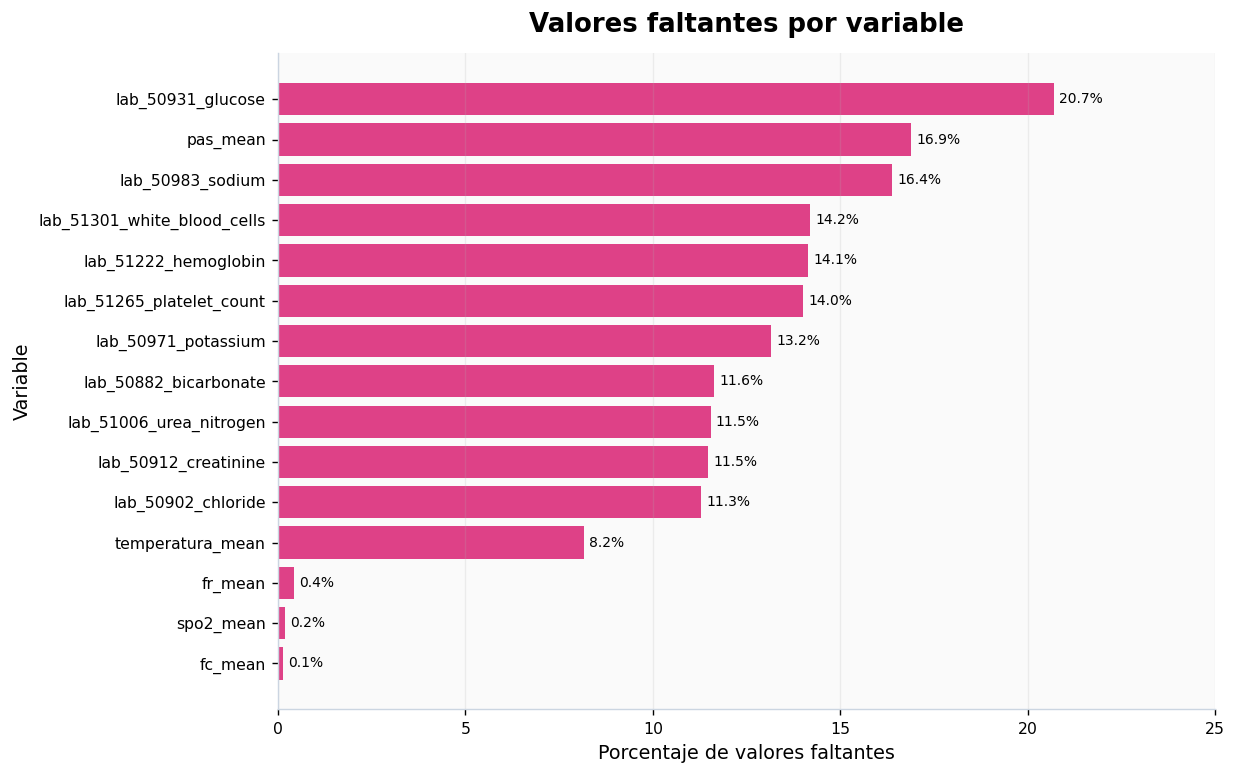

In [16]:
falt_graf = faltantes[faltantes["pct_faltantes"] > 0].sort_values("pct_faltantes")

fig, ax = plt.subplots(figsize=(10, max(5, len(falt_graf)*0.42)))
bars = ax.barh(falt_graf["variable"], falt_graf["pct_faltantes"], color=ROSA, alpha=0.88)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xlim(0, max(25, falt_graf["pct_faltantes"].max()*1.15))
finalizar_grafica(
    ax,
    "Valores faltantes por variable",
    "Porcentaje de valores faltantes",
    "Variable",
    grid_axis="x"
)


,pct_faltantes_predictores_EDA
count,"90,467.000"
mean,9.669
std,18.301
min,0.000
25%,0.000
50%,0.000
75%,11.765
max,88.235


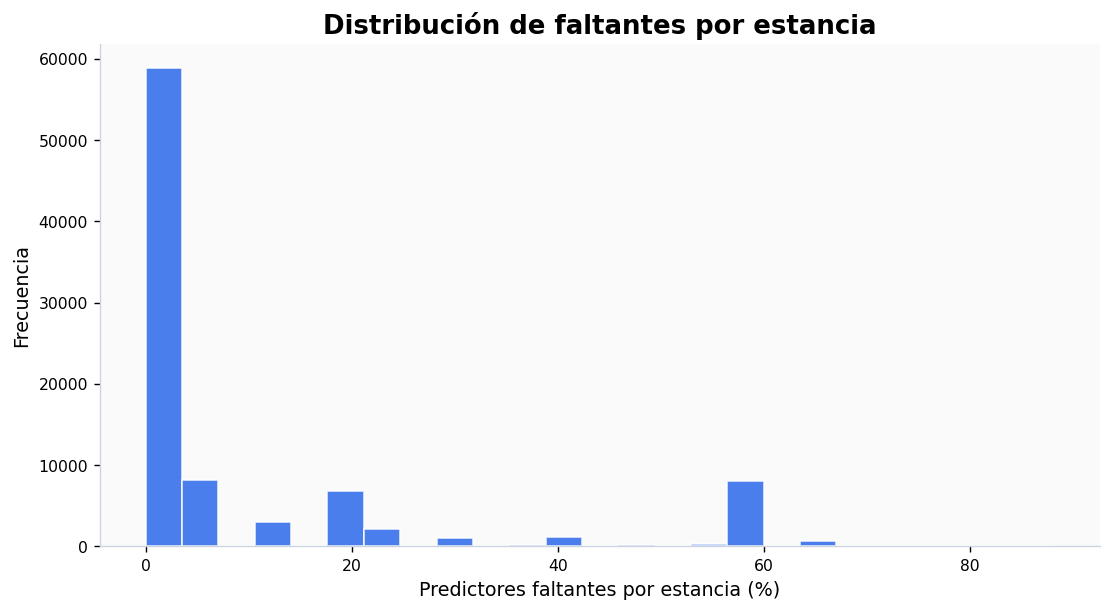

In [17]:
predictores = [c for c in df.columns if c not in IDS + [TARGET]]
df["n_faltantes_predictores_EDA"] = df[predictores].isna().sum(axis=1)
df["pct_faltantes_predictores_EDA"] = df[predictores].isna().mean(axis=1)*100

display(df["pct_faltantes_predictores_EDA"].describe().to_frame())

plt.figure(figsize=(9,5))
plt.hist(df["pct_faltantes_predictores_EDA"], bins=25, color=AZUL, alpha=0.82, edgecolor="white")
plt.xlabel("Predictores faltantes por estancia (%)")
plt.ylabel("Frecuencia")
plt.title("Distribución de faltantes por estancia")
plt.tight_layout()
plt.show()


## 3. Estadística descriptiva de variables numéricas

Además de media y desviación estándar se muestran mediana, percentiles, rango intercuartílico, asimetría y curtosis. Esto es especialmente importante en variables clínicas y en duración de estancia, cuyas distribuciones suelen ser no simétricas.


In [18]:
numericas = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in IDS + ["n_faltantes_predictores_EDA", "pct_faltantes_predictores_EDA"]
]

desc = df[numericas].describe(
    percentiles=[.01,.05,.10,.25,.50,.75,.90,.95,.99]
).T

desc["IQR"] = desc["75%"] - desc["25%"]
desc["asimetria"] = df[numericas].skew()
desc["curtosis"] = df[numericas].kurt()

display(desc)


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max,IQR,asimetria,curtosis
edad_ingreso,"90,467.000",64.804,16.644,18.000,22.000,32.000,41.000,55.000,66.000,77.000,85.000,89.000,92.000,103.000,22.000,-0.544,-0.147
fc_mean,"90,356.000",85.209,17.071,27.214,51.490,60.385,64.824,73.267,83.357,95.923,108.136,115.500,129.462,724.077,22.656,1.056,22.133
fr_mean,"90,078.000",27.355,"1,884.220",0.000,11.727,13.571,14.500,16.154,18.385,21.300,24.615,26.909,31.500,"538,512.000",5.146,267.134,"74,764.474"
spo2_mean,"90,290.000",98.468,309.190,34.429,90.750,93.231,94.211,95.667,97.250,98.750,99.636,99.909,100.000,"81,824.000",3.083,236.727,"58,656.743"
temperatura_mean,"83,080.000",98.264,12.008,0.000,95.842,96.833,97.325,97.800,98.225,98.700,99.350,99.867,100.928,"3,343.233",0.900,239.227,"64,234.625"
pas_mean,"75,185.000",119.059,154.218,0.000,83.154,92.000,96.417,104.579,116.083,130.154,143.636,152.000,169.308,"41,111.360",25.575,251.859,"66,498.753"
lab_50882_bicarbonate,"79,934.000",23.089,4.564,2.000,11.000,16.000,18.000,21.000,23.000,26.000,28.000,30.000,37.000,50.000,5.000,0.291,2.137
lab_50902_chloride,"80,247.000",103.950,6.444,61.000,86.000,93.000,96.000,100.000,104.000,108.000,111.000,113.000,119.000,151.000,8.000,-0.305,1.879
lab_50912_creatinine,"80,077.000",1.455,1.593,0.000,0.400,0.500,0.600,0.700,1.000,1.500,2.800,4.300,8.500,41.500,0.800,4.859,41.735
lab_50931_glucose,"71,739.000",141.327,63.689,15.000,62.380,80.000,88.000,103.000,125.000,160.000,213.000,260.000,371.000,"1,856.000",57.000,3.545,33.742


## 4. Análisis exhaustivo del target: `los_restante_dias`

Se estudia la forma de la distribución, percentiles y valores extremos. **No se transforma ni trunca el target durante el EDA.**


In [19]:
target_desc = df[TARGET].describe(
    percentiles=[.01,.05,.10,.25,.50,.75,.90,.95,.99]
)
display(target_desc.to_frame())

print("Asimetría:", df[TARGET].skew())
print("Curtosis:", df[TARGET].kurt())
print("Valores <= 0:", (df[TARGET] <= 0).sum())
print("Faltantes:", df[TARGET].isna().sum())


,los_restante_dias
count,"90,467.000"
mean,3.276
std,5.474
min,0.000
1%,0.053
5%,0.201
10%,0.335
25%,0.670
50%,1.546
75%,3.487


Asimetría: 6.201794271946764
Curtosis: 87.88759474601531
Valores <= 0: 1
Faltantes: 0


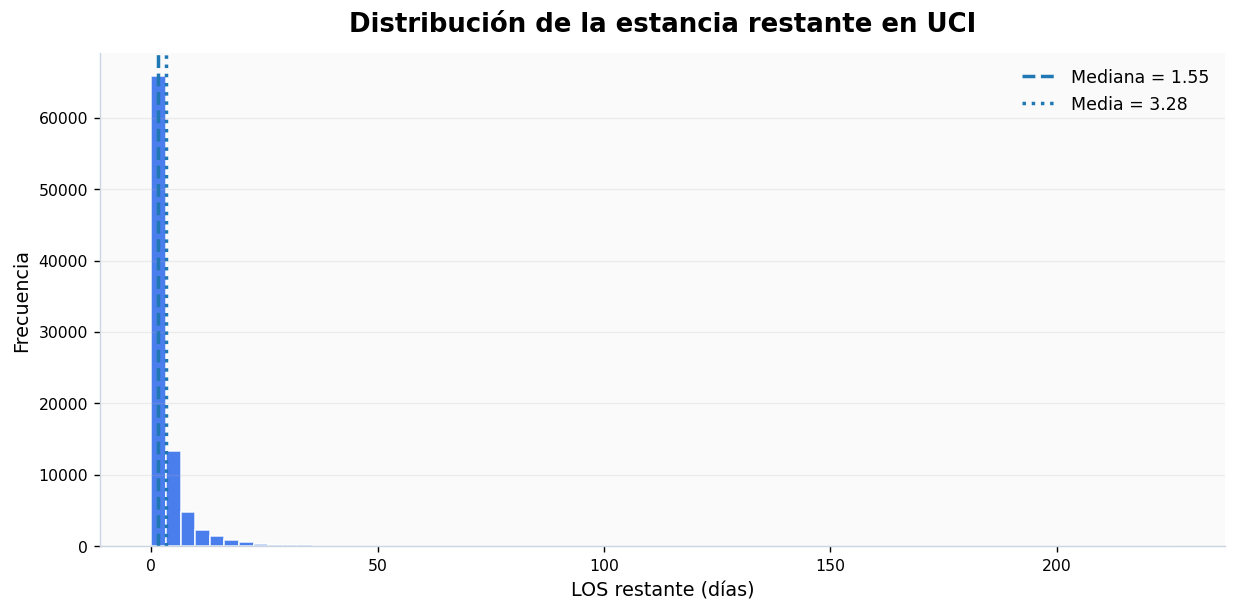

In [20]:
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(df[TARGET].dropna(), bins=70, color=AZUL, alpha=0.82, edgecolor="white")
ax.axvline(df[TARGET].median(), linestyle="--", linewidth=2,
           label=f"Mediana = {df[TARGET].median():.2f}")
ax.axvline(df[TARGET].mean(), linestyle=":", linewidth=2,
           label=f"Media = {df[TARGET].mean():.2f}")
ax.legend()
finalizar_grafica(
    ax,
    "Distribución de la estancia restante en UCI",
    "LOS restante (días)",
    "Frecuencia"
)


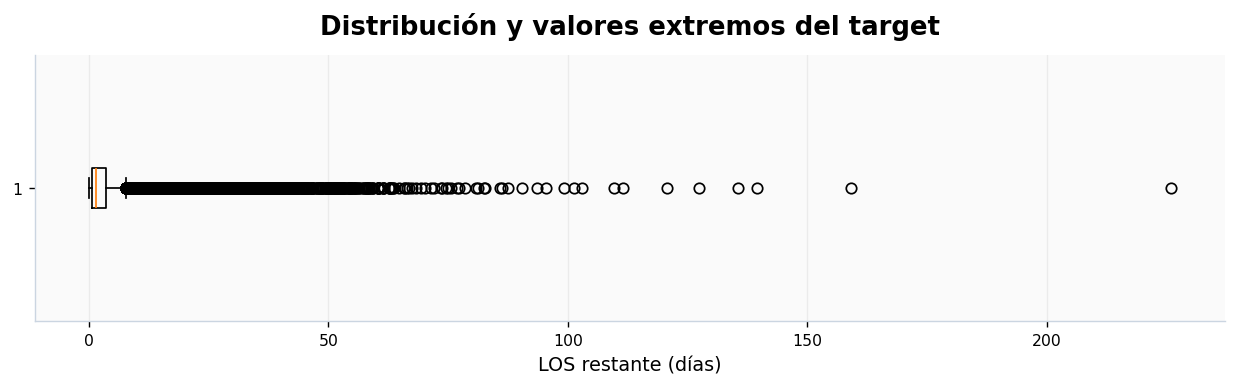

In [21]:
fig, ax = plt.subplots(figsize=(10,3.2))
ax.boxplot(df[TARGET].dropna(), vert=False, showfliers=True)
finalizar_grafica(
    ax,
    "Distribución y valores extremos del target",
    "LOS restante (días)",
    "",
    grid_axis="x"
)


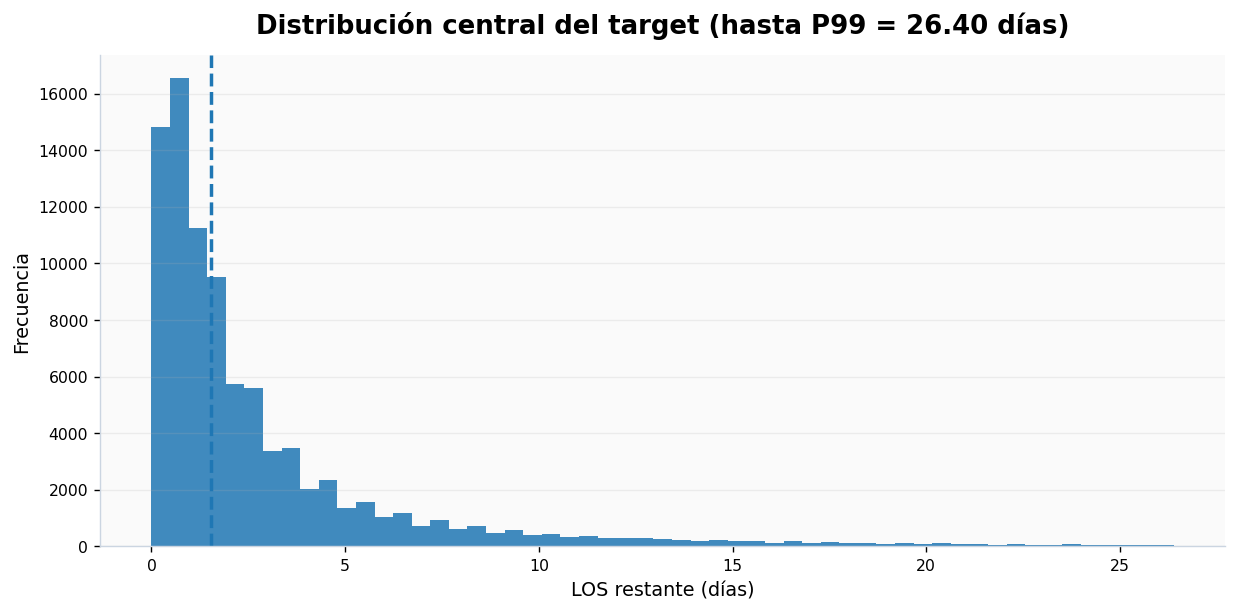

In [22]:
p99_target = df[TARGET].quantile(.99)

fig, ax = plt.subplots(figsize=(10,5))
ax.hist(df.loc[df[TARGET] <= p99_target, TARGET].dropna(), bins=55, alpha=.85)
ax.axvline(df[TARGET].median(), linestyle="--", linewidth=2)
finalizar_grafica(
    ax,
    f"Distribución central del target (hasta P99 = {p99_target:.2f} días)",
    "LOS restante (días)",
    "Frecuencia"
)


## 5. Variables categóricas

En el conjunto final reducido se espera principalmente `gender`. Se revisan frecuencias absolutas, porcentajes y la distribución del target por categoría.



=== gender ===


,n,pct
gender,,
M,50732,56.078
F,39735,43.922


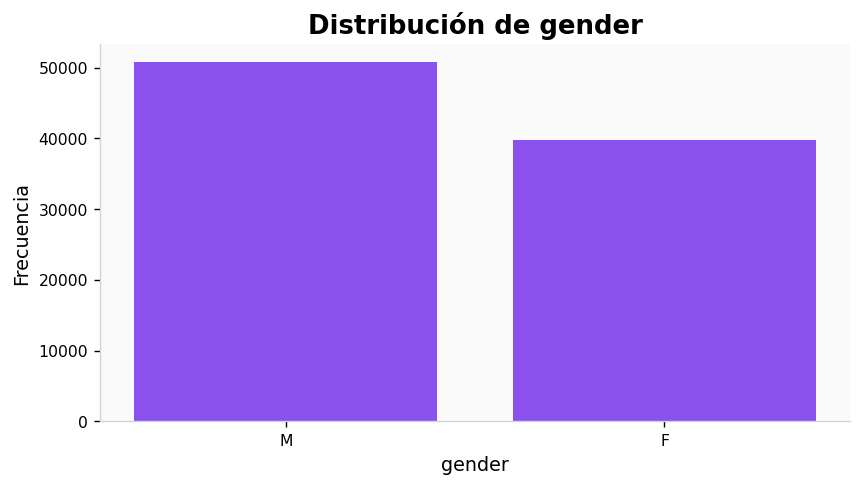

In [23]:
categoricas = [
    c for c in df.select_dtypes(include=["object","category","bool"]).columns
    if c not in IDS
]

for c in categoricas:
    tabla = pd.DataFrame({
        "n": df[c].value_counts(dropna=False),
        "pct": df[c].value_counts(dropna=False, normalize=True)*100
    })
    print(f"\n=== {c} ===")
    display(tabla)

    plt.figure(figsize=(7,4))
    counts = df[c].fillna("Faltante").value_counts()
    plt.bar(counts.index.astype(str), counts.values, color=MORADO, alpha=0.88)
    plt.xlabel(c)
    plt.ylabel("Frecuencia")
    plt.title(f"Distribución de {c}")
    plt.tight_layout()
    plt.show()


,n,media,mediana,std,q1,q3
gender,,,,,,
F,39735,3.158,1.522,5.242,0.643,3.417
M,50732,3.368,1.563,5.647,0.688,3.535


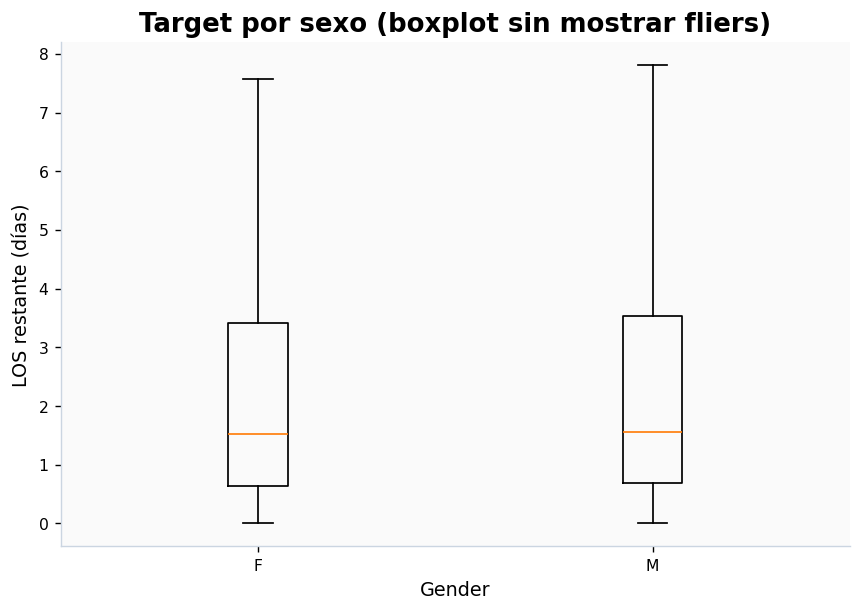

In [24]:
if "gender" in df.columns:
    resumen_gender = df.groupby("gender", dropna=False)[TARGET].agg(
        n="count", media="mean", mediana="median", std="std",
        q1=lambda x: x.quantile(.25),
        q3=lambda x: x.quantile(.75)
    )
    display(resumen_gender)

    grupos = [g[TARGET].dropna().values for _, g in df.groupby("gender", dropna=False)]
    etiquetas = [str(k) for k, _ in df.groupby("gender", dropna=False)]

    plt.figure(figsize=(7,5))
    plt.boxplot(grupos, tick_labels=etiquetas, showfliers=False)
    plt.xlabel("Gender")
    plt.ylabel("LOS restante (días)")
    plt.title("Target por sexo (boxplot sin mostrar fliers)")
    plt.tight_layout()
    plt.show()


## 6. Distribuciones de todos los predictores numéricos

Se generan histogramas y boxplots **individuales** para cada variable. Esto permite identificar asimetrías, acumulaciones, posibles errores y valores extremos sin ocultarlos mediante agregación.


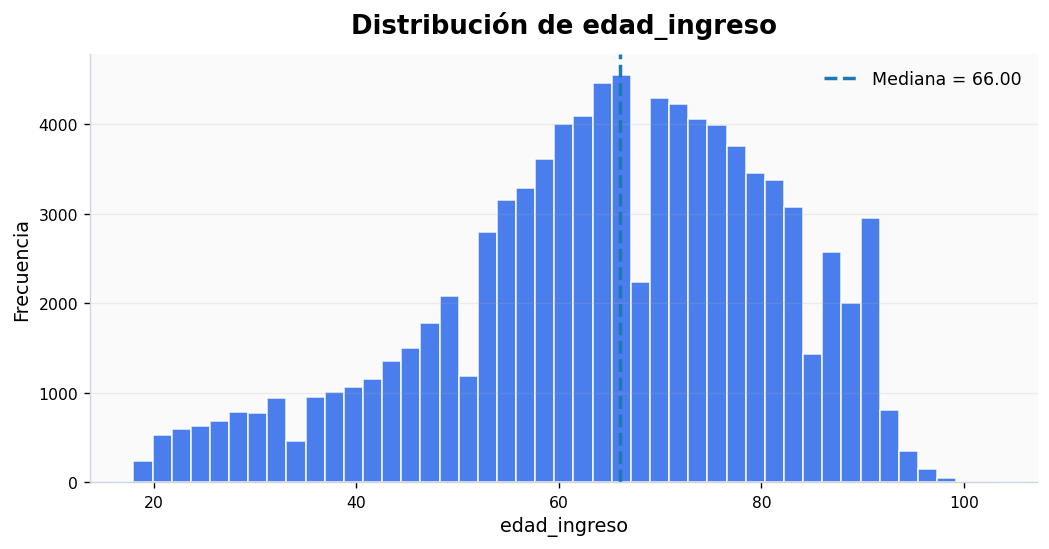

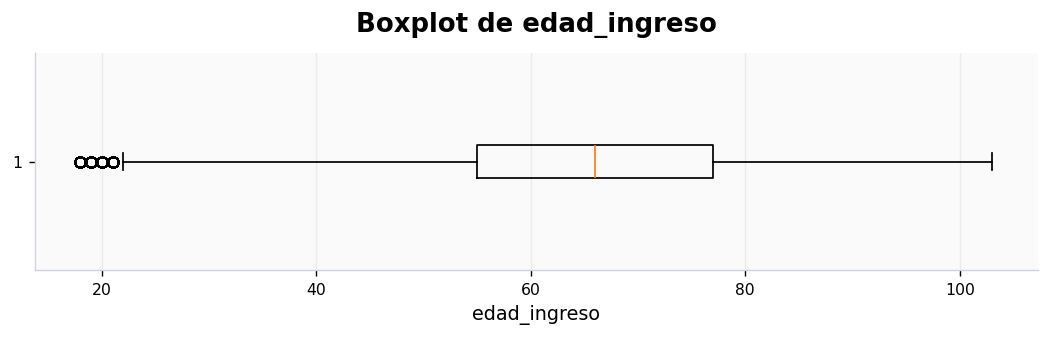

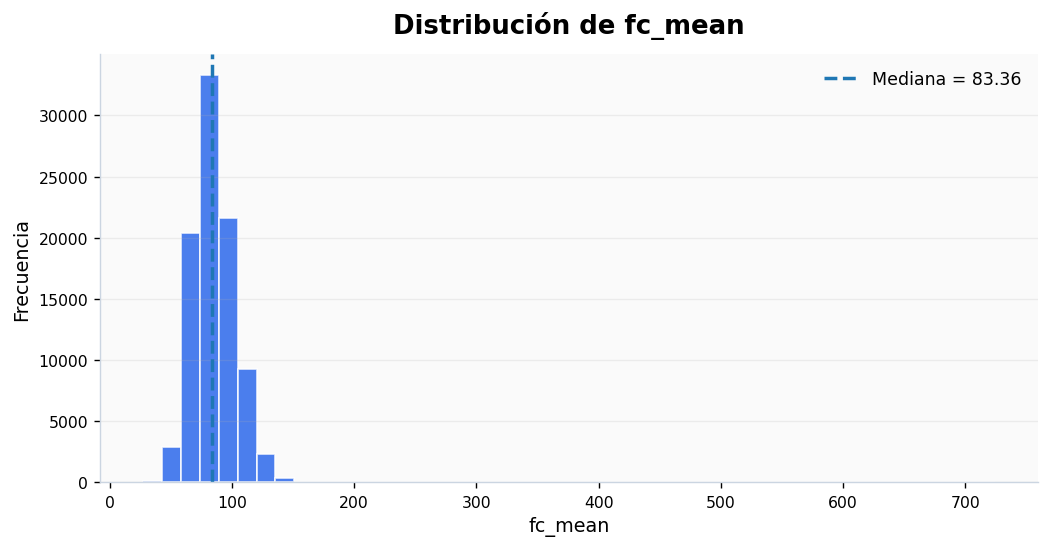

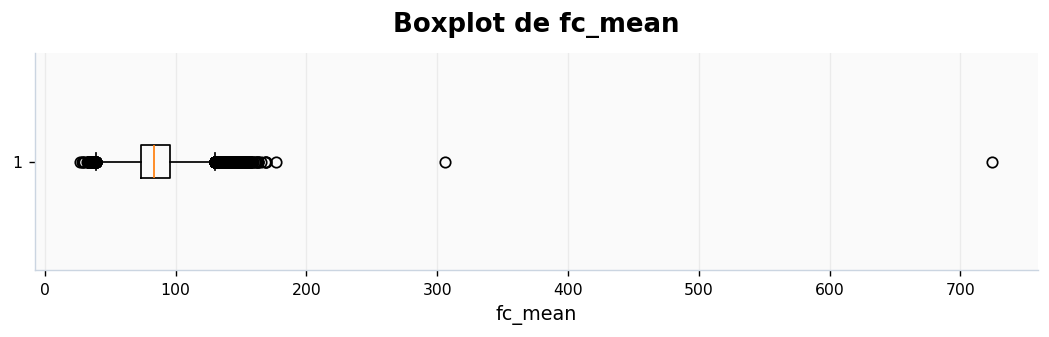

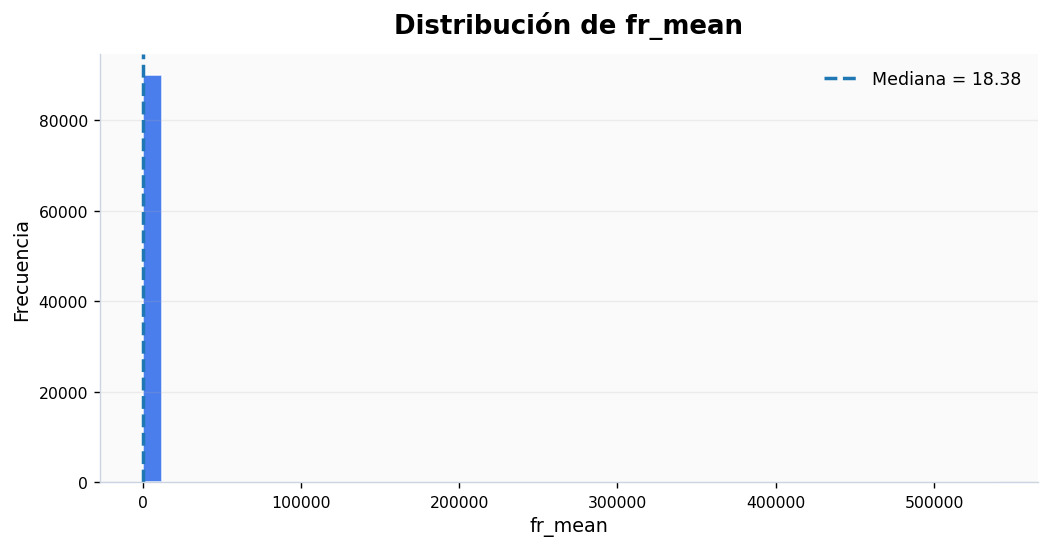

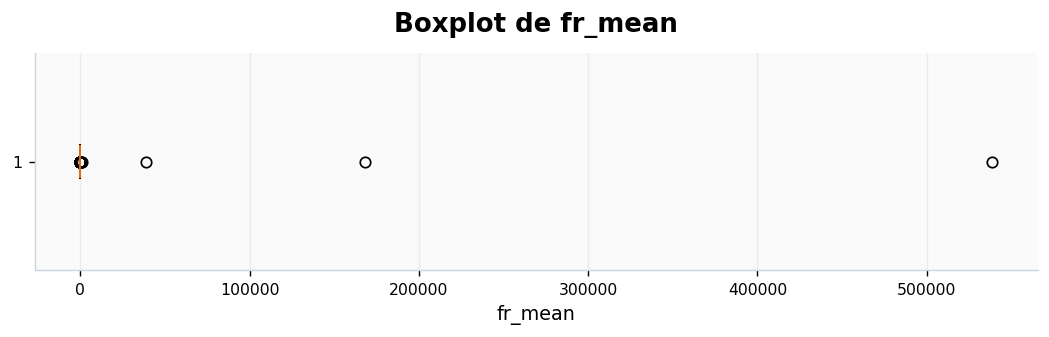

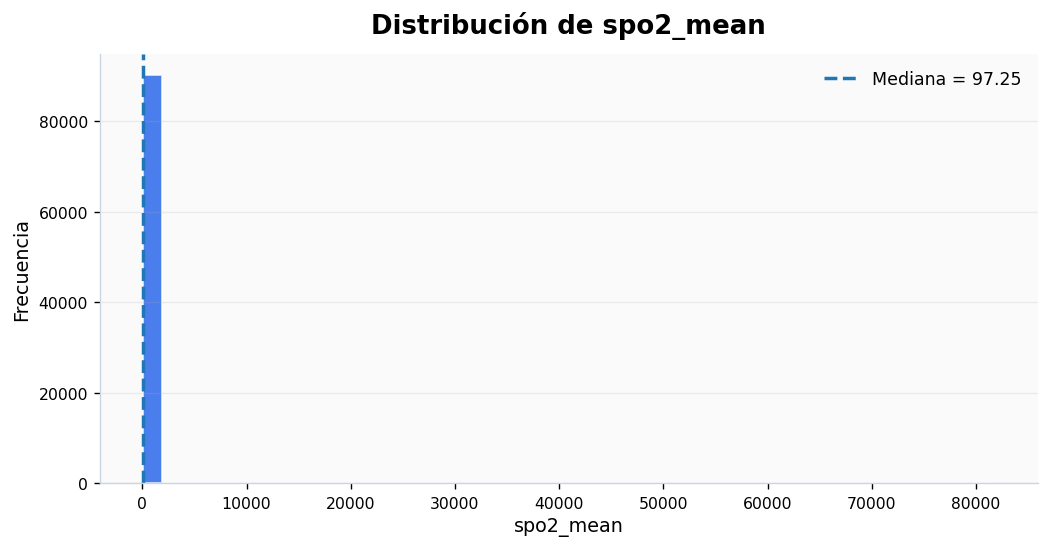

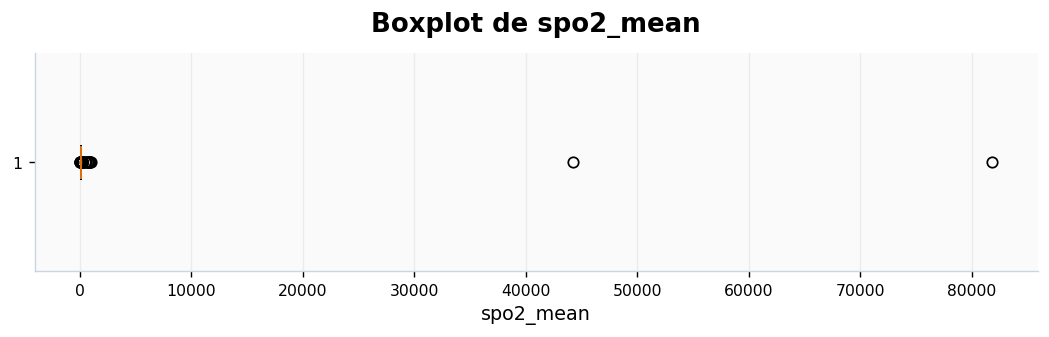

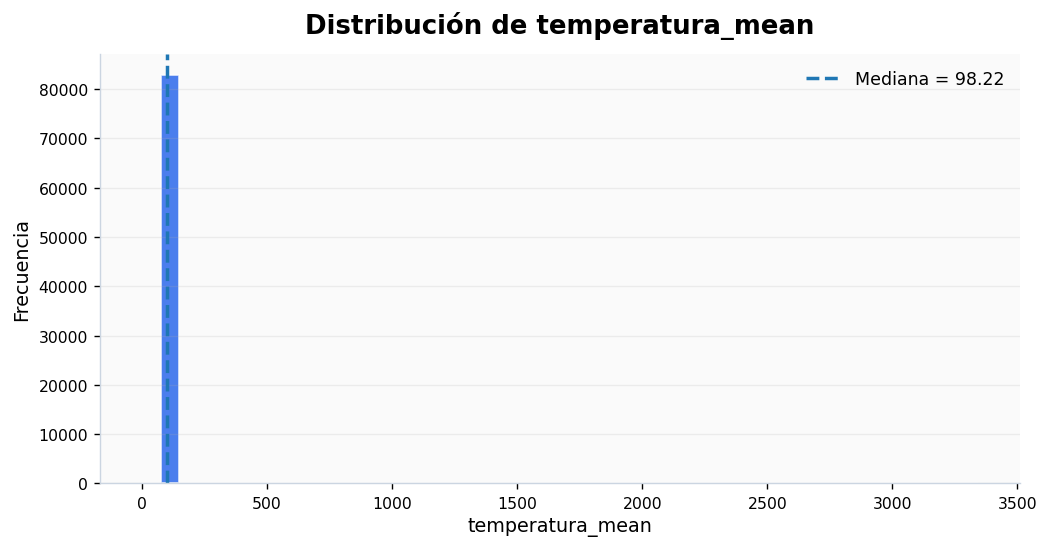

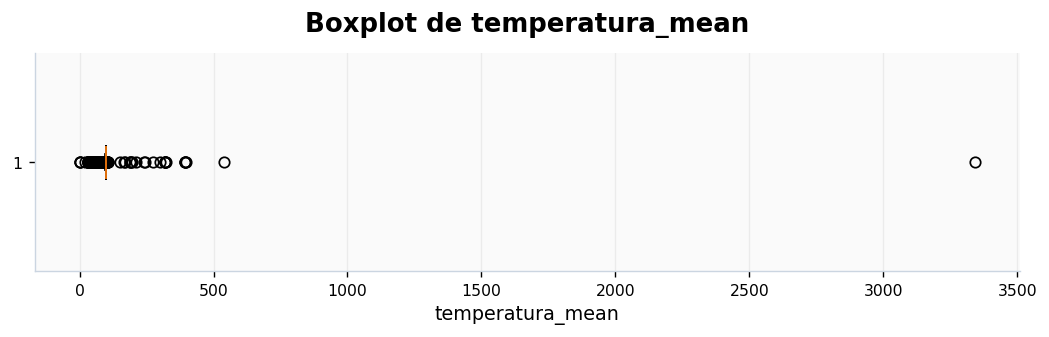

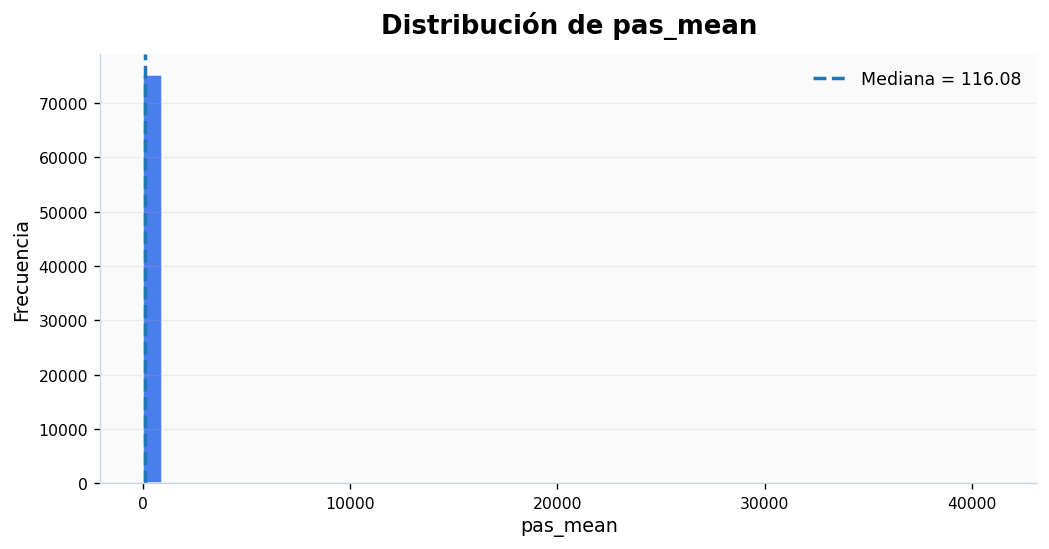

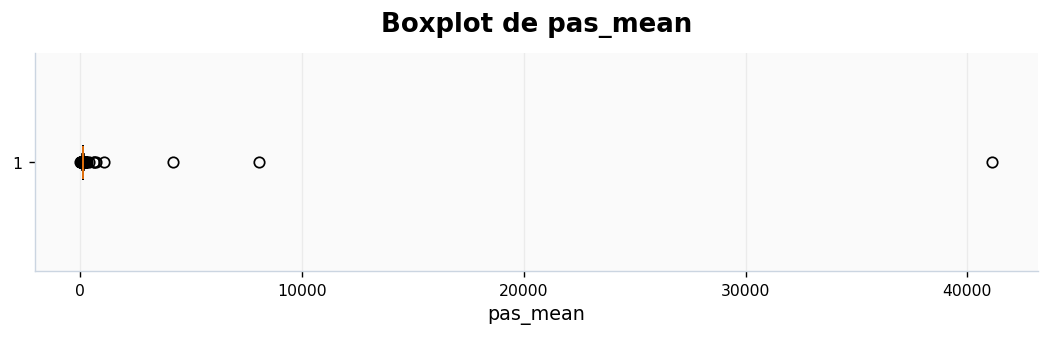

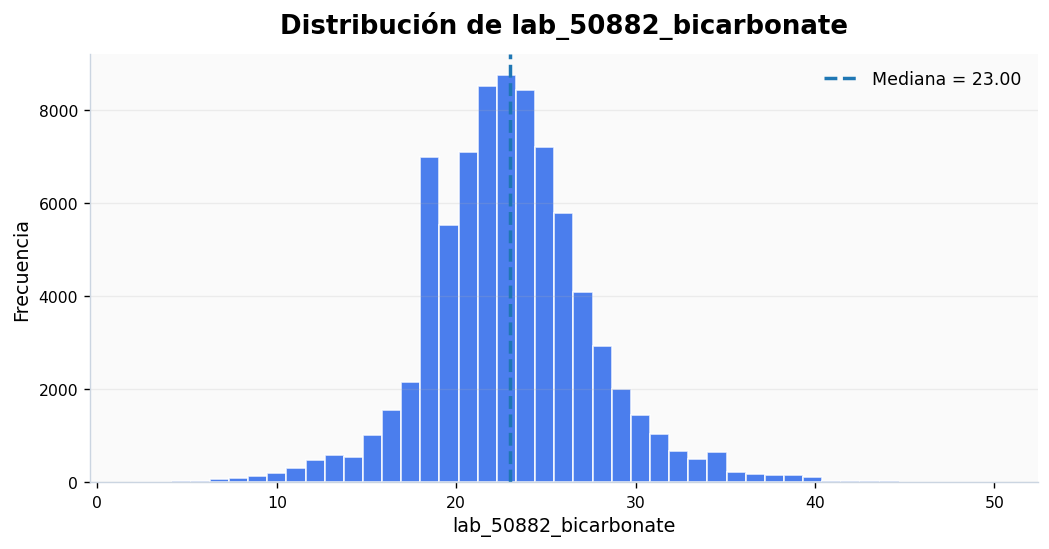

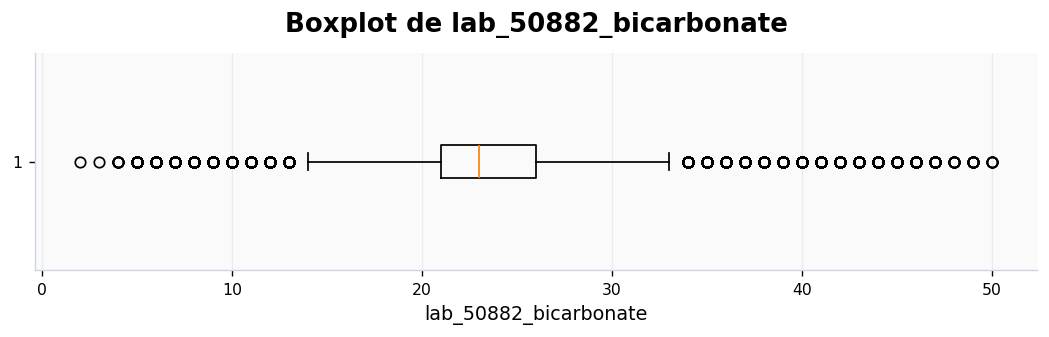

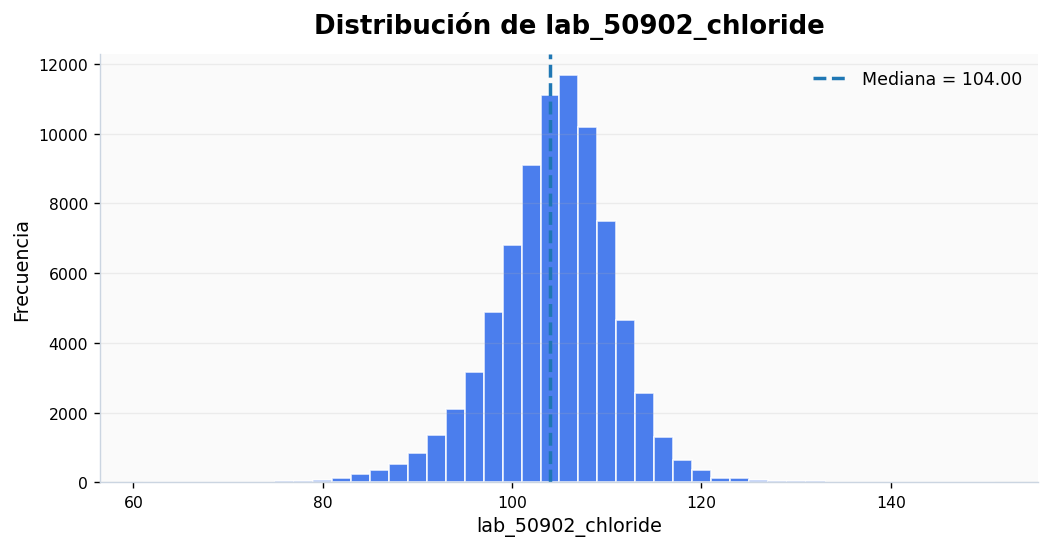

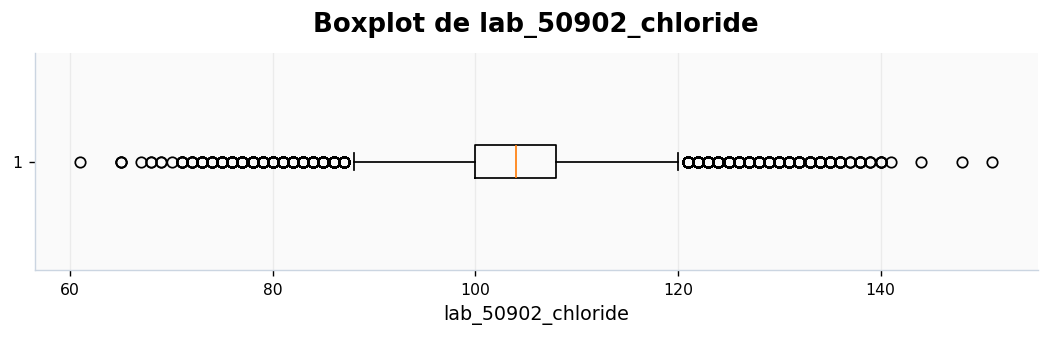

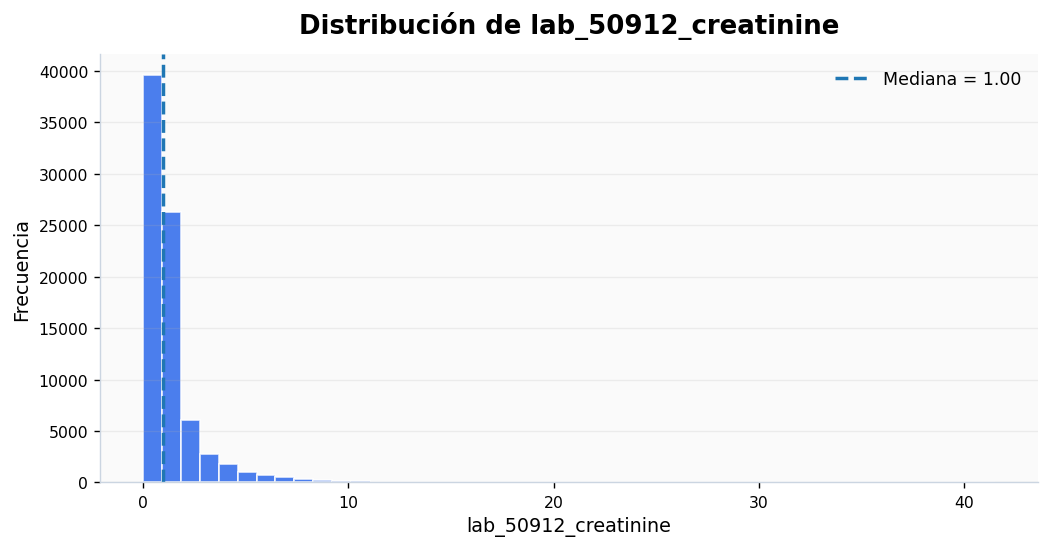

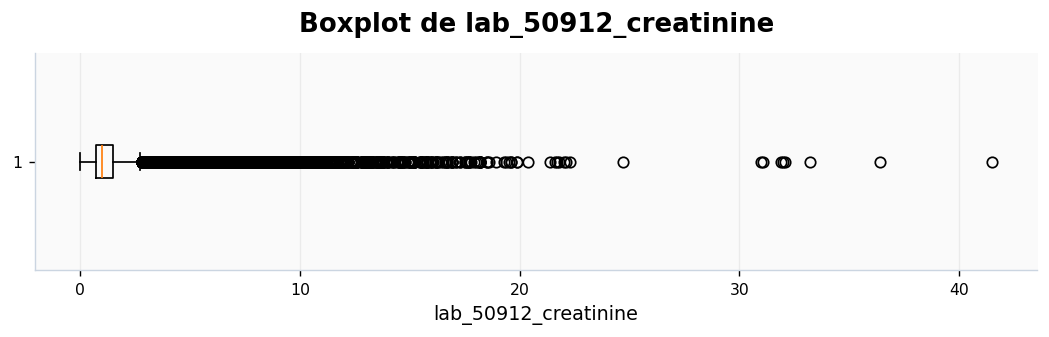

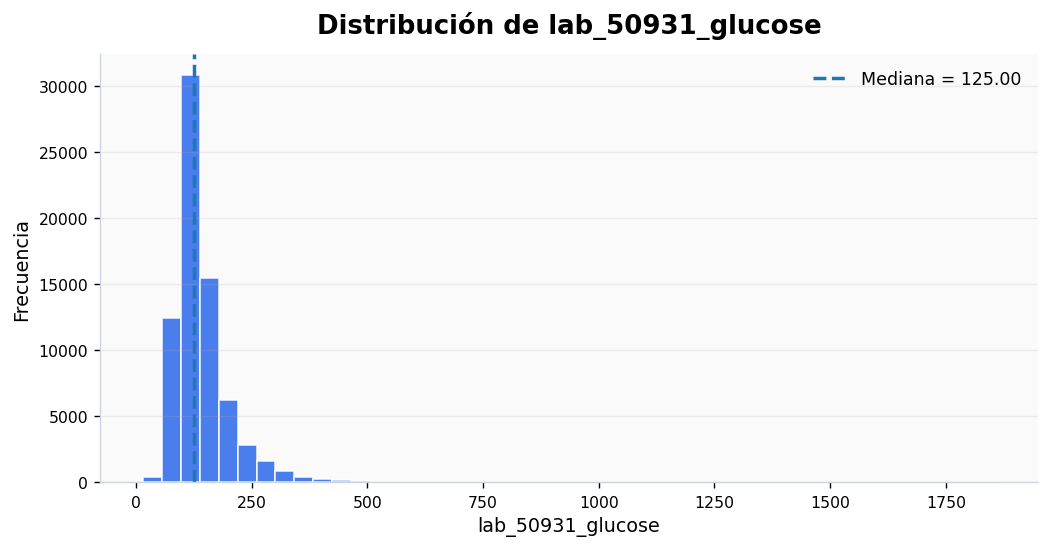

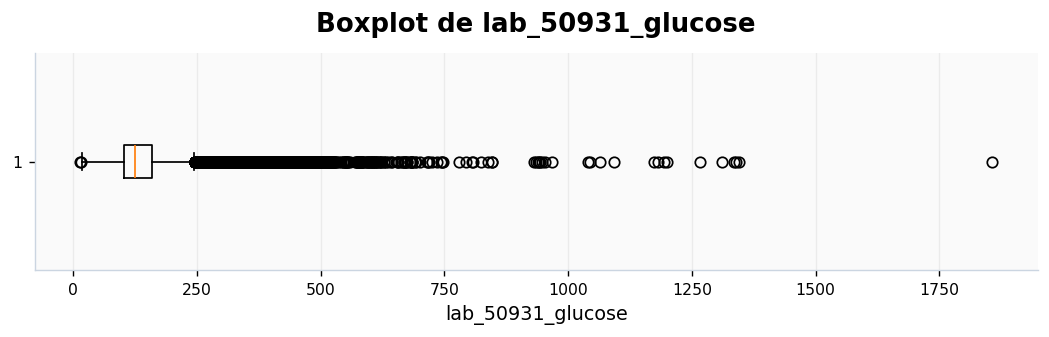

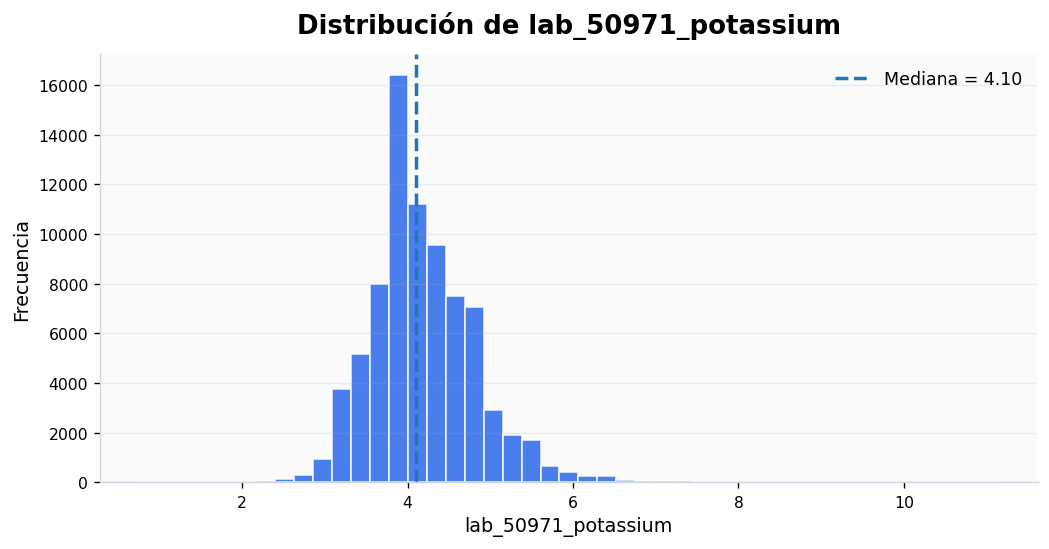

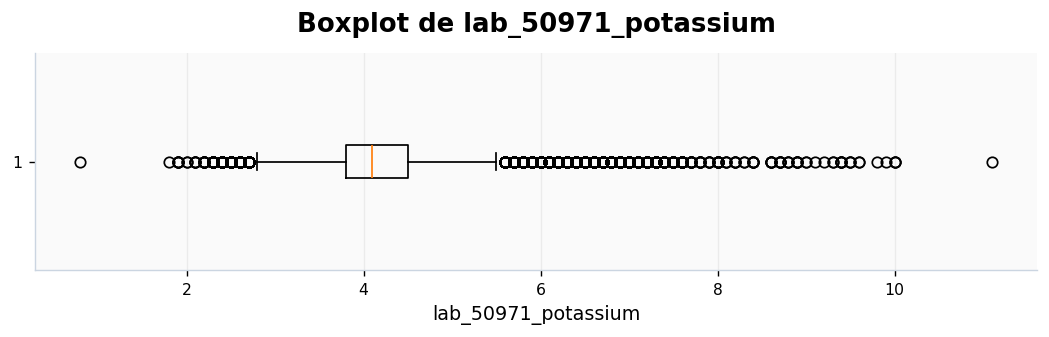

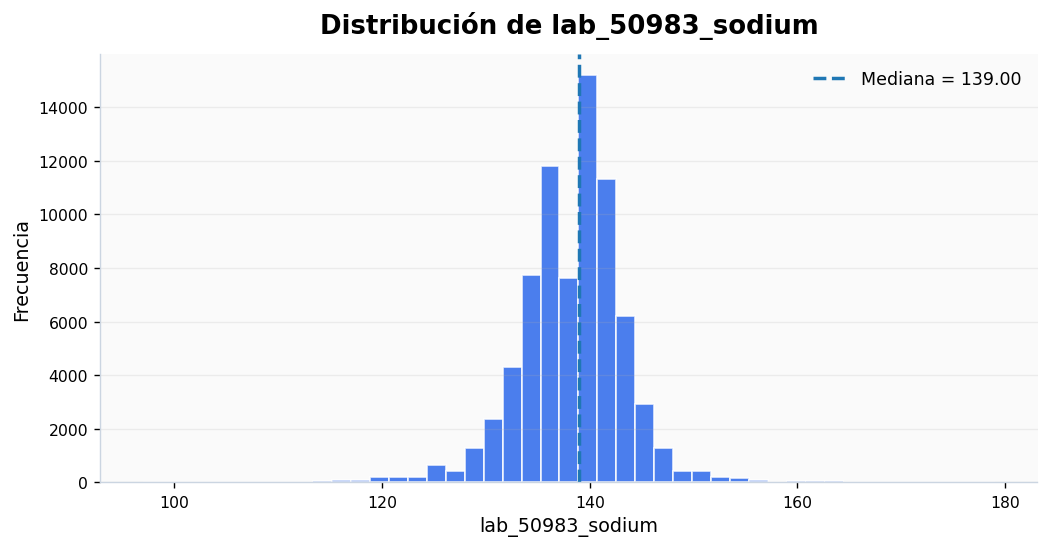

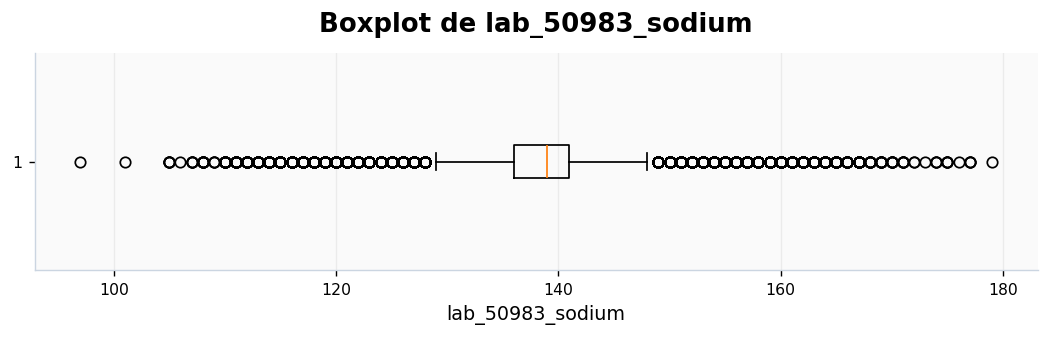

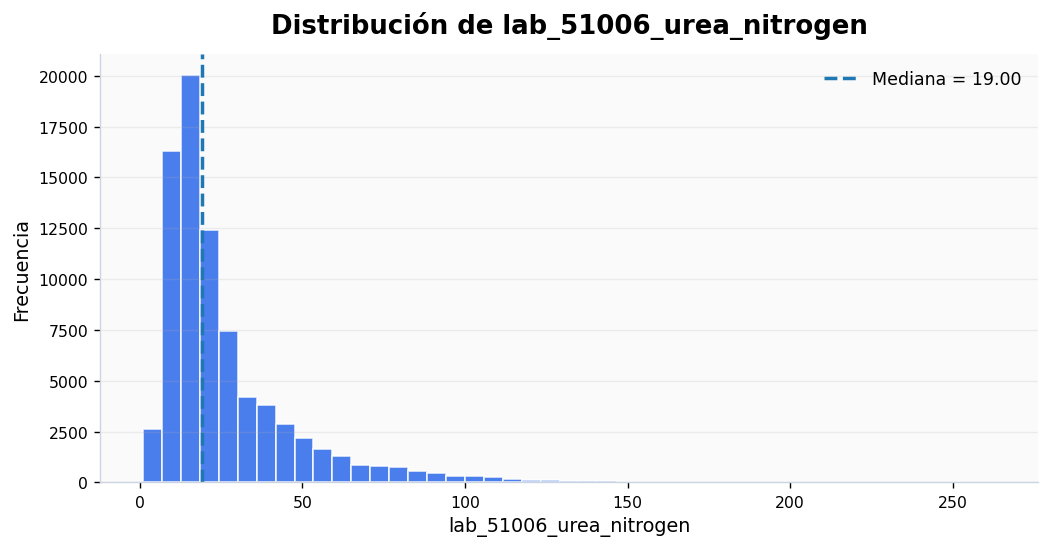

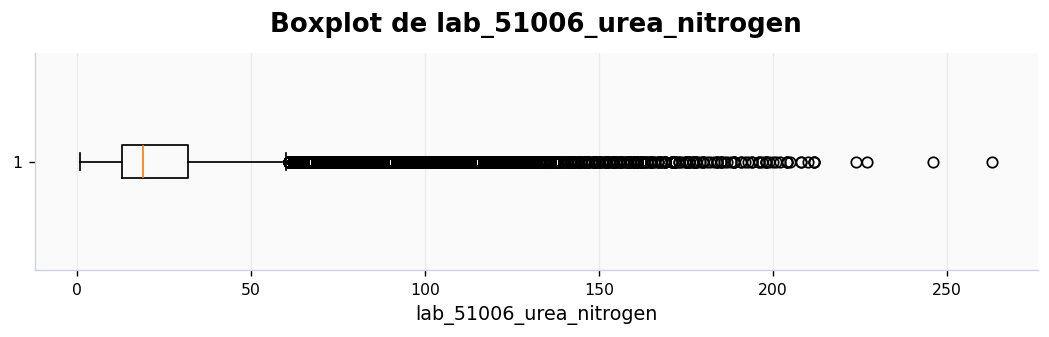

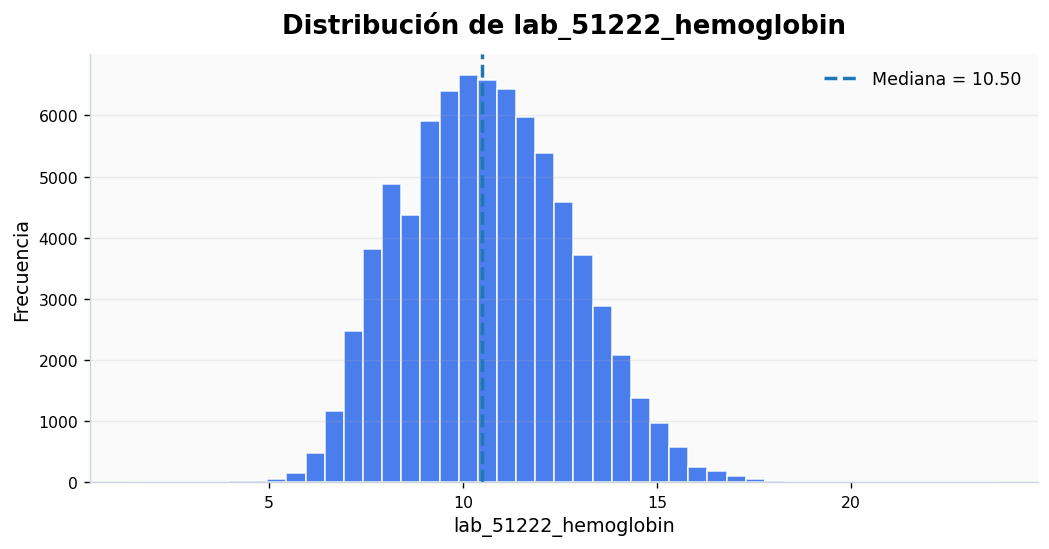

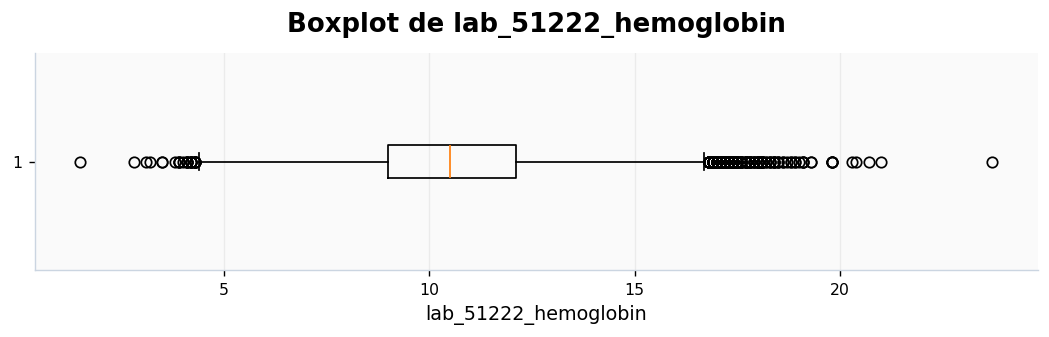

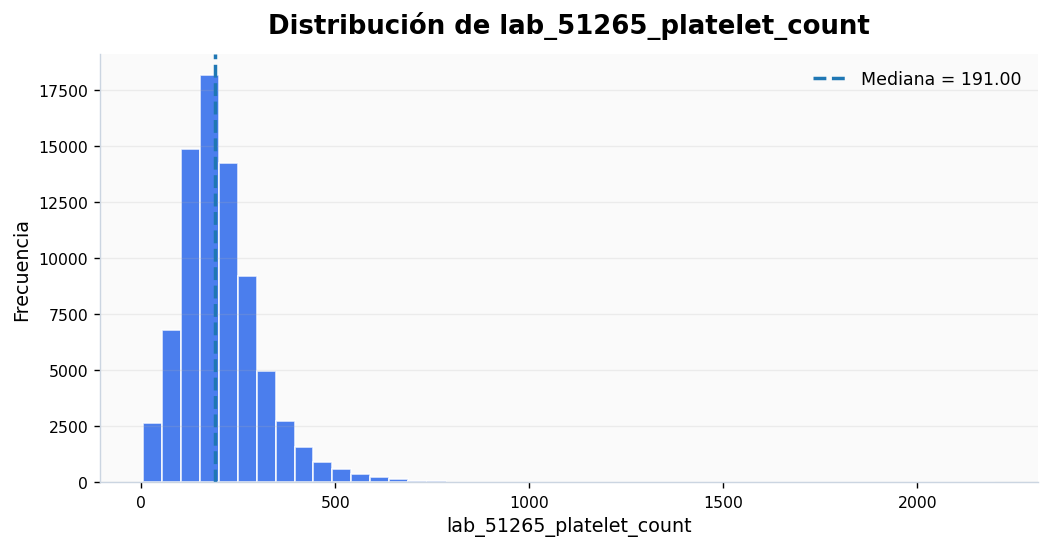

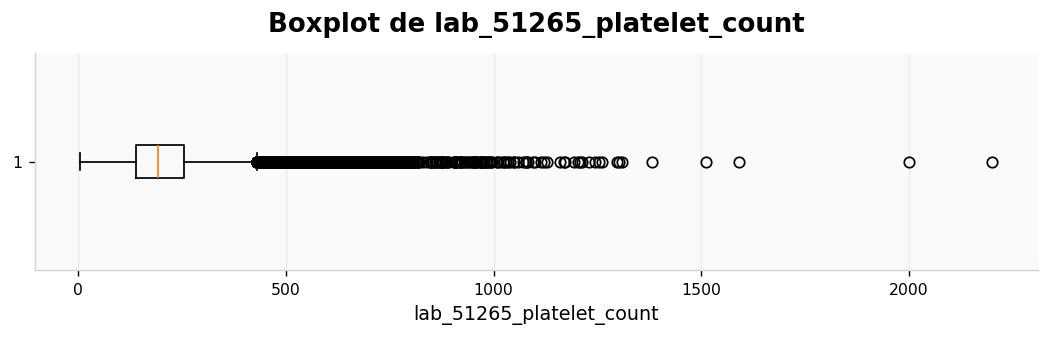

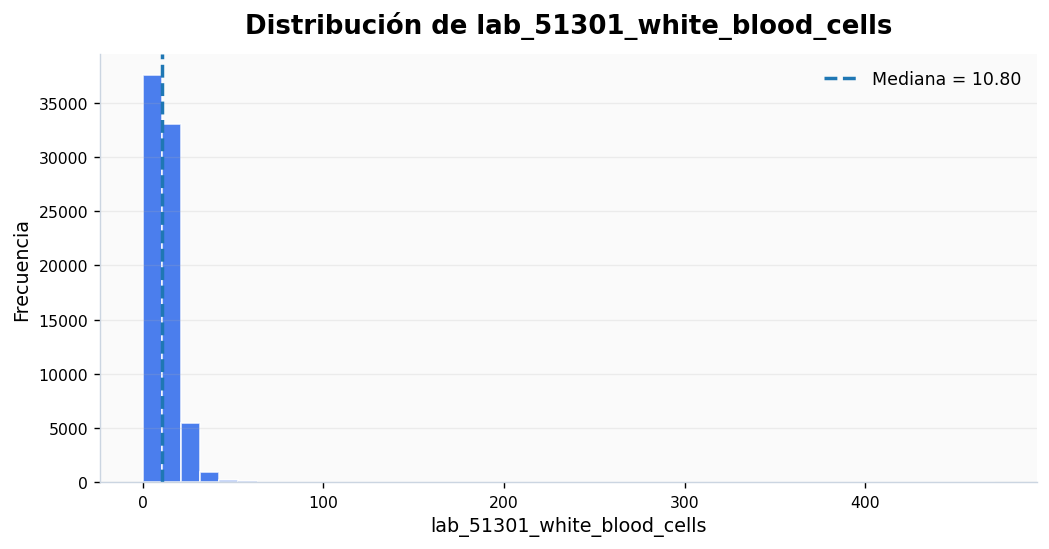

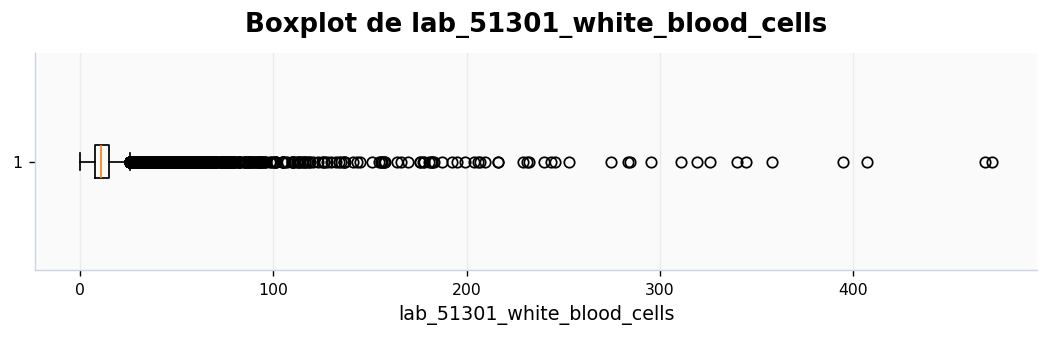

In [25]:
num_pred = [c for c in numericas if c != TARGET]

for c in num_pred:
    serie = df[c].dropna()

    fig, ax = plt.subplots(figsize=(8.5,4.5))
    ax.hist(serie, bins=45, color=AZUL, alpha=0.82, edgecolor="white")
    ax.axvline(serie.median(), linestyle="--", linewidth=2,
               label=f"Mediana = {serie.median():.2f}")
    ax.legend()
    finalizar_grafica(ax, f"Distribución de {c}", c, "Frecuencia")

    fig, ax = plt.subplots(figsize=(8.5,2.8))
    ax.boxplot(serie, vert=False, showfliers=True)
    finalizar_grafica(ax, f"Boxplot de {c}", c, "", grid_axis="x")


## 7. Detección de outliers por IQR

Un valor marcado por IQR **no es automáticamente un dato erróneo**. En variables clínicas puede representar un paciente crítico real. Esta sección cuantifica extremos estadísticos para revisión posterior.


In [26]:
outliers_iqr = []

for c in numericas:
    s = df[c].dropna()
    q1 = s.quantile(.25)
    q3 = s.quantile(.75)
    iqr = q3-q1
    li = q1 - 1.5*iqr
    ls = q3 + 1.5*iqr
    mask = (df[c] < li) | (df[c] > ls)
    n = int(mask.sum())

    outliers_iqr.append({
        "variable": c,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "limite_inferior": li,
        "limite_superior": ls,
        "n_outliers_IQR": n,
        "pct_outliers_IQR": n/df[c].notna().sum()*100 if df[c].notna().sum() else np.nan
    })

tabla_outliers_iqr = pd.DataFrame(outliers_iqr).sort_values(
    "pct_outliers_IQR", ascending=False
)
display(tabla_outliers_iqr)


,variable,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers_IQR,pct_outliers_IQR
8,lab_50912_creatinine,0.700,1.500,0.800,-0.500,2.700,8057,10.062
16,los_restante_dias,0.670,3.487,2.817,-3.556,7.713,8940,9.882
12,lab_51006_urea_nitrogen,13.000,32.000,19.000,-15.500,60.500,6267,7.831
4,temperatura_mean,97.800,98.700,0.900,96.450,100.050,5406,6.507
9,lab_50931_glucose,103.000,160.000,57.000,17.500,245.500,4378,6.103
11,lab_50983_sodium,136.000,141.000,5.000,128.500,148.500,4090,5.407
6,lab_50882_bicarbonate,21.000,26.000,5.000,13.500,33.500,3619,4.527
15,lab_51301_white_blood_cells,7.700,15.000,7.300,-3.250,25.950,3264,4.205
14,lab_51265_platelet_count,138.000,255.000,117.000,-37.500,430.500,2846,3.659
10,lab_50971_potassium,3.800,4.500,0.700,2.750,5.550,2768,3.523


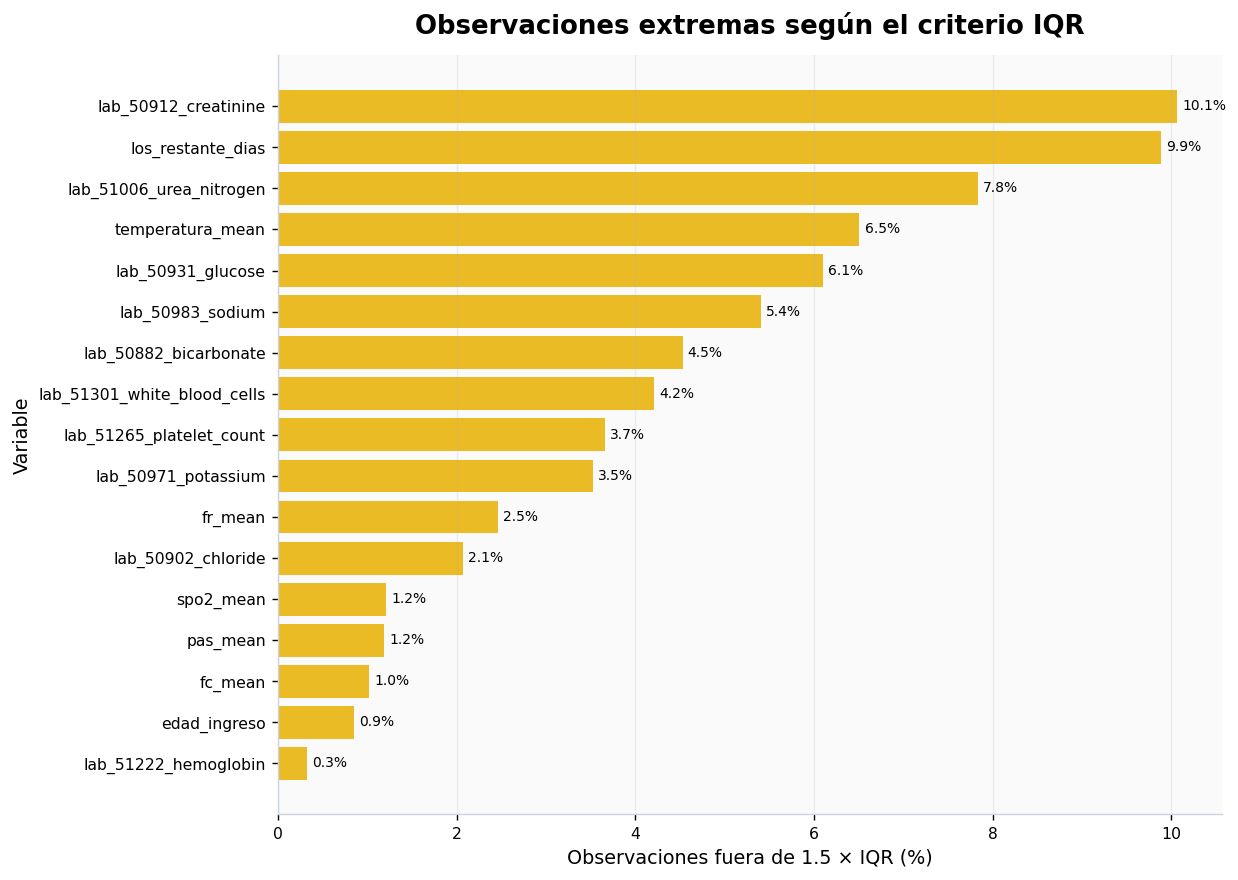

In [27]:
tmp = tabla_outliers_iqr.sort_values("pct_outliers_IQR")

fig, ax = plt.subplots(figsize=(10, max(5, len(tmp)*.42)))
bars = ax.barh(tmp["variable"], tmp["pct_outliers_IQR"], color=AMARILLO, alpha=0.88)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
finalizar_grafica(
    ax,
    "Observaciones extremas según el criterio IQR",
    "Observaciones fuera de 1.5 × IQR (%)",
    "Variable",
    grid_axis="x"
)


## 8. Detección robusta adicional mediante MAD

Como complemento al IQR se calcula un z-score robusto basado en la mediana y la desviación absoluta mediana (MAD). Se utiliza `|z robusto| > 3.5` únicamente como bandera diagnóstica.


In [28]:
outliers_mad = []

for c in numericas:
    s = df[c].dropna()
    med = s.median()
    mad = np.median(np.abs(s-med))

    if mad == 0 or np.isnan(mad):
        n = 0
        pct = 0
    else:
        rz = 0.6745*(s-med)/mad
        n = int((np.abs(rz)>3.5).sum())
        pct = n/len(s)*100

    outliers_mad.append({
        "variable":c,
        "mediana":med,
        "MAD":mad,
        "n_outliers_MAD":n,
        "pct_outliers_MAD":pct
    })

tabla_outliers_mad = pd.DataFrame(outliers_mad).sort_values(
    "pct_outliers_MAD", ascending=False
)
display(tabla_outliers_mad)


,variable,mediana,MAD,n_outliers_MAD,pct_outliers_MAD
16,los_restante_dias,1.546,1.053,10173,11.245
8,lab_50912_creatinine,1.000,0.300,8966,11.197
12,lab_51006_urea_nitrogen,19.000,8.000,6267,7.831
9,lab_50931_glucose,125.000,26.000,3591,5.006
6,lab_50882_bicarbonate,23.000,2.000,3039,3.802
4,temperatura_mean,98.225,0.425,2967,3.571
15,lab_51301_white_blood_cells,10.800,3.600,2037,2.624
14,lab_51265_platelet_count,191.000,58.000,1618,2.080
11,lab_50983_sodium,139.000,3.000,1259,1.664
2,fr_mean,18.385,2.473,1012,1.123


## 9. Revisión de valores claramente incompatibles con la medición

Esta sección se utiliza como **control de calidad**, no como una regla para borrar pacientes.

En este dataset, `temperatura_mean` proviene de la medición de temperatura en **Fahrenheit**, por lo que no debe evaluarse contra límites en °C. Para facilitar interpretación, durante la limpieza se convertirá a Celsius.

Los límites definidos abajo son deliberadamente amplios y se usan para identificar valores técnicamente incompatibles o extraordinariamente improbables. Los outliers estadísticos de IQR/MAD **no se eliminan** por sí solos.


In [29]:
# Límites amplios de control de calidad.
# No equivalen a intervalos de referencia "normales".
rangos_revision = {
    "edad_ingreso": (18, 120),
    "fc_mean": (20, 300),
    "fr_mean": (3, 100),
    "spo2_mean": (20, 100),
    "temperatura_mean": (77, 113),   # Fahrenheit ≈ 25–45 °C
    "pas_mean": (30, 300),
    "lab_50882_bicarbonate": (2, 80),
    "lab_50902_chloride": (40, 180),
    "lab_50912_creatinine": (0.05, 30),
    "lab_50931_glucose": (10, 1500),
    "lab_50971_potassium": (1, 12),
    "lab_50983_sodium": (80, 220),
    "lab_51006_urea_nitrogen": (1, 300),
    "lab_51222_hemoglobin": (1, 30),
    "lab_51265_platelet_count": (1, 2000),
    "lab_51301_white_blood_cells": (0.05, 200)
}

plausibilidad = []
for c, (li, ls) in rangos_revision.items():
    if c not in df.columns:
        continue
    validos = df[c].notna()
    fuera = validos & ((df[c] < li) | (df[c] > ls))
    plausibilidad.append({
        "variable":c,
        "limite_revision_inferior":li,
        "limite_revision_superior":ls,
        "n_fuera_rango_revision":int(fuera.sum()),
        "pct_fuera_rango_revision":fuera.sum()/validos.sum()*100
    })

tabla_plausibilidad = pd.DataFrame(plausibilidad).sort_values(
    "pct_fuera_rango_revision", ascending=False
)
display(tabla_plausibilidad)


,variable,limite_revision_inferior,limite_revision_superior,n_fuera_rango_revision,pct_fuera_rango_revision
4,temperatura_mean,77.000,113,169,0.203
3,spo2_mean,20.000,100,32,0.035
15,lab_51301_white_blood_cells,0.050,200,27,0.035
8,lab_50912_creatinine,0.050,30,12,0.015
5,pas_mean,30.000,300,10,0.013
2,fr_mean,3.000,100,11,0.012
14,lab_51265_platelet_count,1.000,2000,2,0.003
1,fc_mean,20.000,300,2,0.002
9,lab_50931_glucose,10.000,1500,1,0.001
10,lab_50971_potassium,1.000,12,1,0.001


## 10. Asociación de cada predictor numérico con el target

Se calculan Pearson y Spearman. Pearson resume asociación lineal; Spearman permite identificar asociaciones monotónicas y es menos sensible a la forma de distribuciones muy asimétricas.

Una correlación baja con el target **no implica automáticamente que una variable carezca de utilidad multivariable**.


In [30]:
asociaciones = []

for c in num_pred:
    pares = df[[c,TARGET]].dropna()
    if len(pares) < 3 or pares[c].nunique() < 2:
        continue

    pearson_r, pearson_p = stats.pearsonr(pares[c], pares[TARGET])
    spearman_r, spearman_p = stats.spearmanr(pares[c], pares[TARGET])

    asociaciones.append({
        "variable":c,
        "n_pares":len(pares),
        "pearson_r":pearson_r,
        "pearson_p":pearson_p,
        "spearman_rho":spearman_r,
        "spearman_p":spearman_p,
        "spearman_abs":abs(spearman_r)
    })

tabla_asociaciones = pd.DataFrame(asociaciones).sort_values(
    "spearman_abs", ascending=False
)
display(tabla_asociaciones)


,variable,n_pares,pearson_r,pearson_p,spearman_rho,spearman_p,spearman_abs
12,lab_51006_urea_nitrogen,80026,0.084,0.000,0.132,0.000,0.132
2,fr_mean,90078,0.003,0.296,0.128,0.000,0.128
15,lab_51301_white_blood_cells,77615,0.057,0.000,0.124,0.000,0.124
9,lab_50931_glucose,71739,0.057,0.000,0.108,0.000,0.108
4,temperatura_mean,83080,0.005,0.181,0.101,0.000,0.101
8,lab_50912_creatinine,80077,0.050,0.000,0.100,0.000,0.100
1,fc_mean,90356,0.084,0.000,0.100,0.000,0.100
6,lab_50882_bicarbonate,79934,-0.040,0.000,-0.075,0.000,0.075
5,pas_mean,75185,-0.007,0.046,-0.074,0.000,0.074
13,lab_51222_hemoglobin,77679,-0.029,0.000,-0.068,0.000,0.068


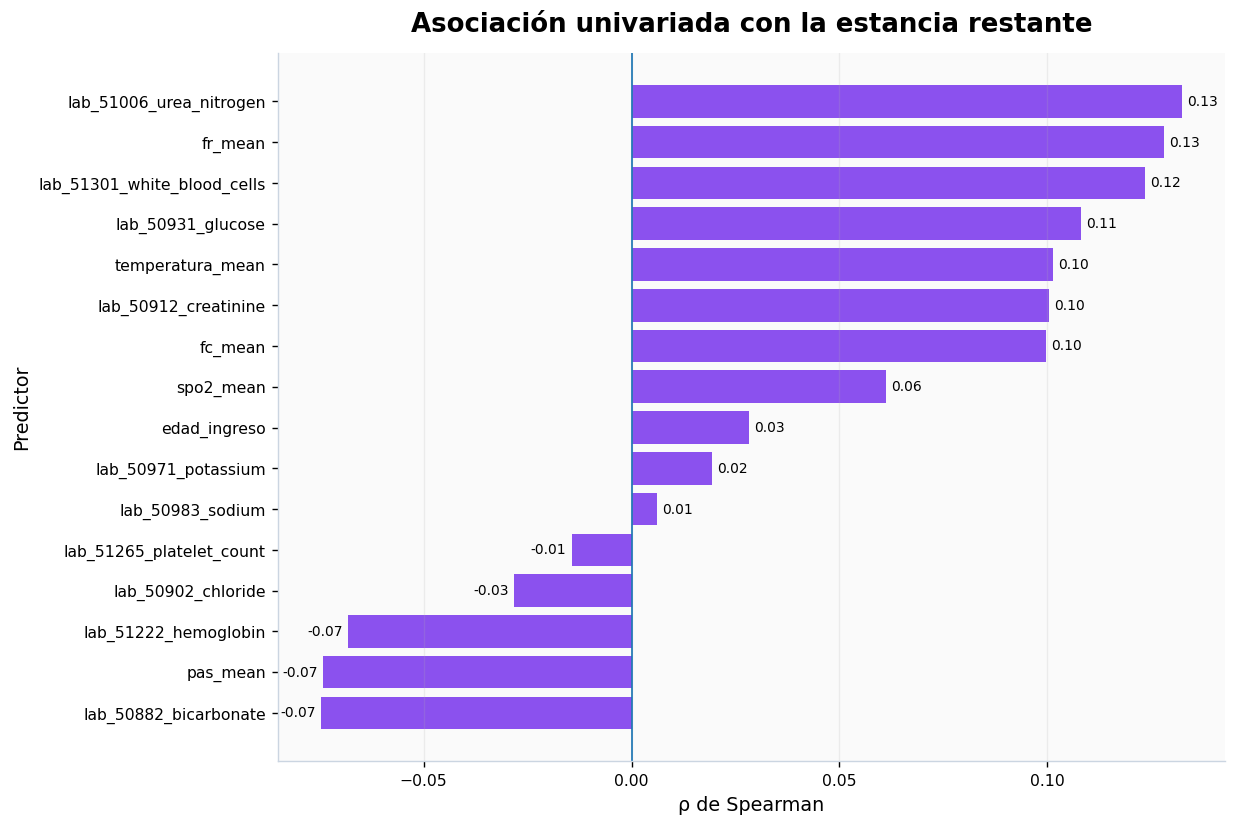

In [31]:
tmp = tabla_asociaciones.sort_values("spearman_rho")

fig, ax = plt.subplots(figsize=(10, max(5, len(tmp)*.42)))
bars = ax.barh(tmp["variable"], tmp["spearman_rho"], color=MORADO, alpha=0.88)
ax.axvline(0, linewidth=1)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
finalizar_grafica(
    ax,
    "Asociación univariada con la estancia restante",
    "ρ de Spearman",
    "Predictor",
    grid_axis="x"
)


## 11. Scatterplots predictor–target

Para evitar que 90 mil observaciones hagan ilegibles las gráficas, se usa una muestra aleatoria reproducible **solo para visualización**. Los cálculos estadísticos anteriores utilizan todas las observaciones disponibles.


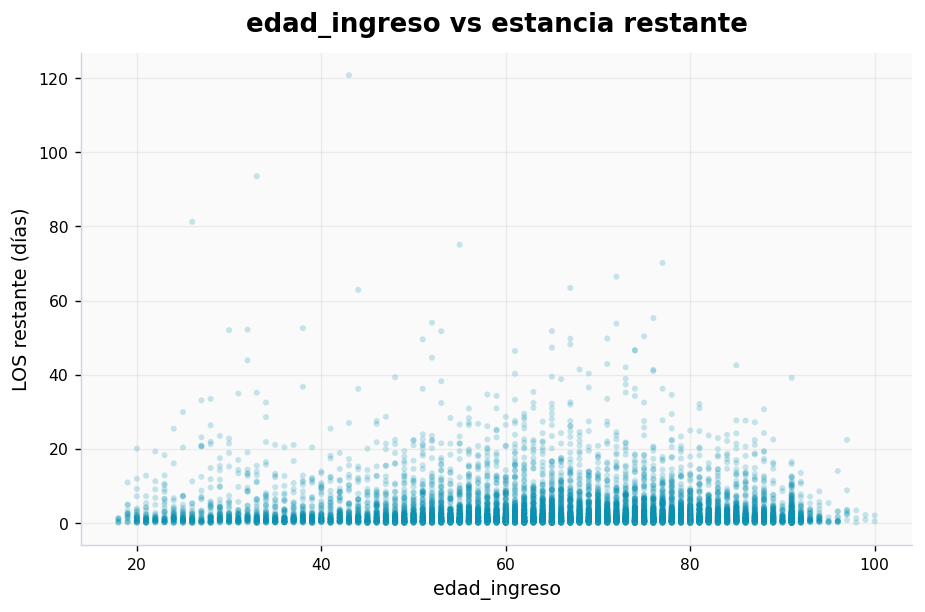

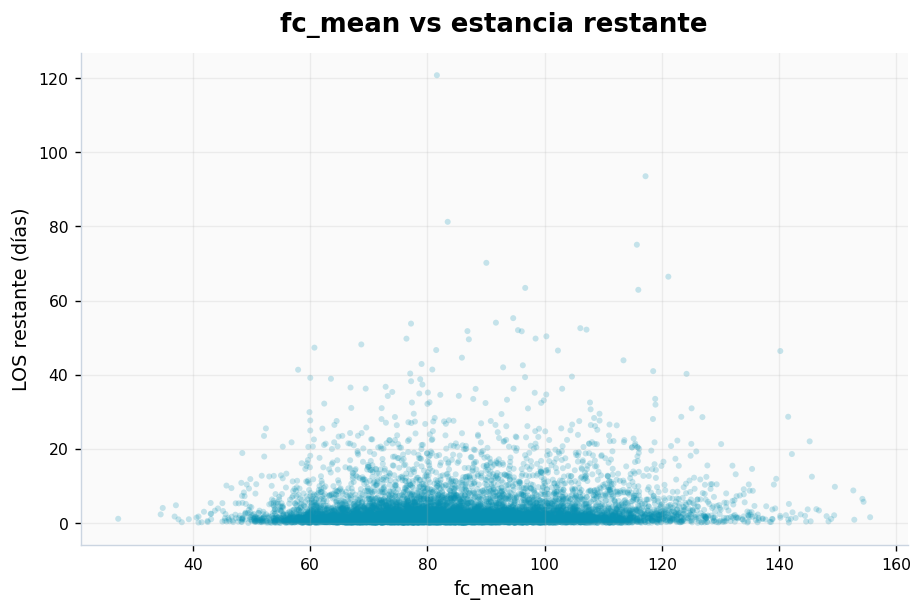

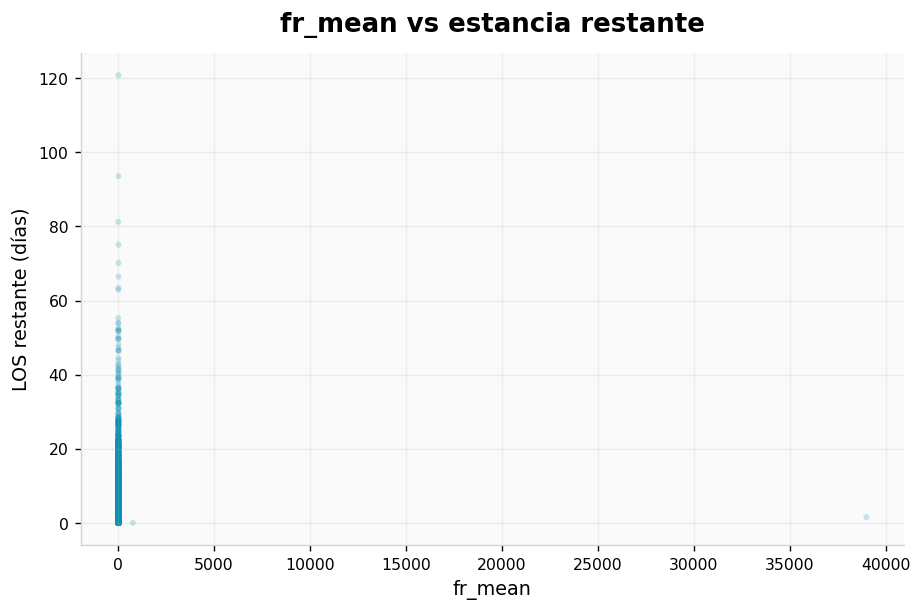

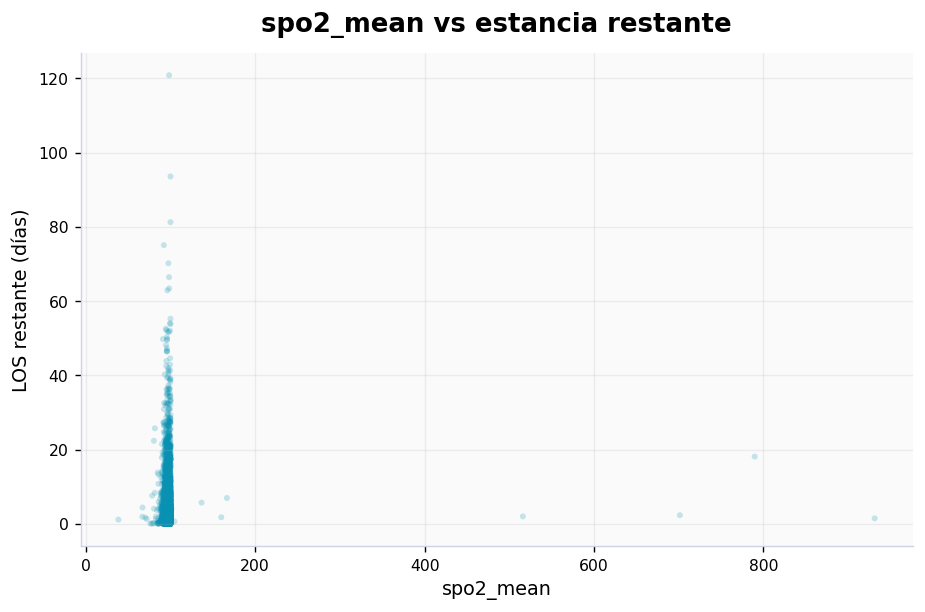

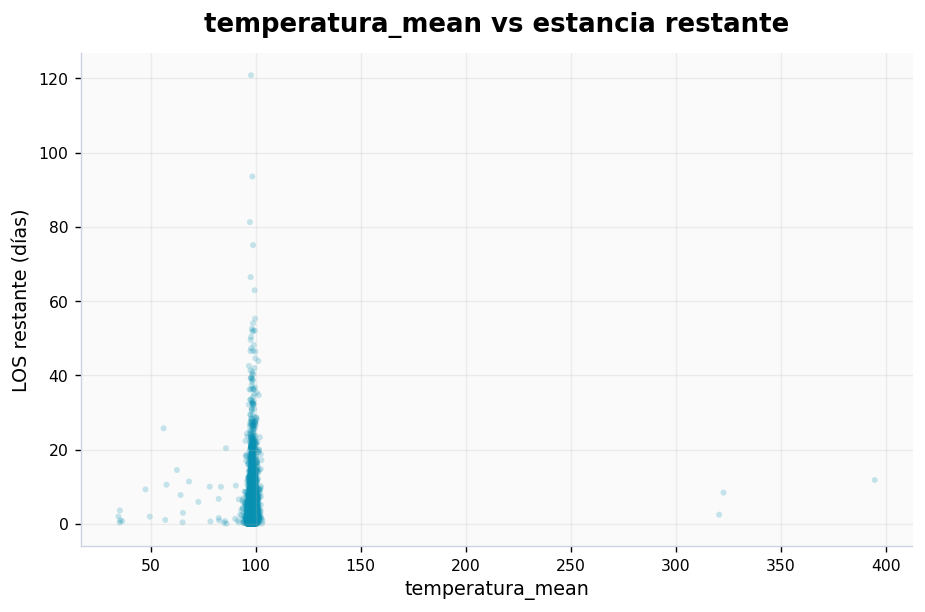

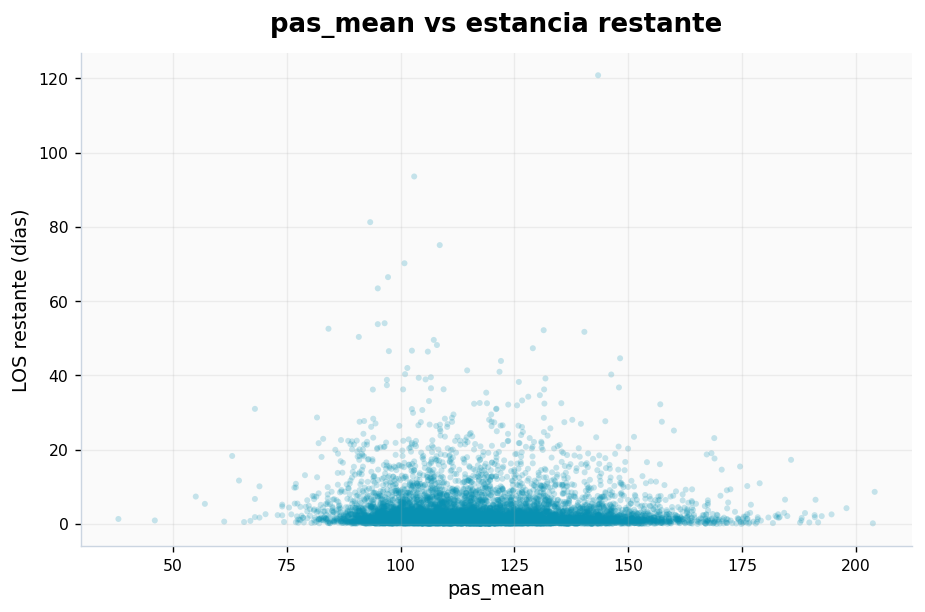

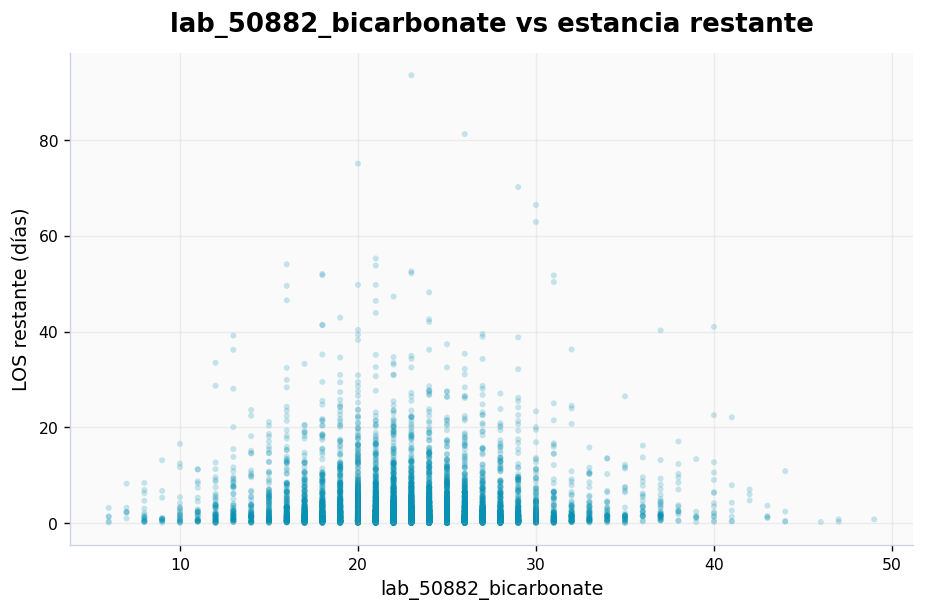

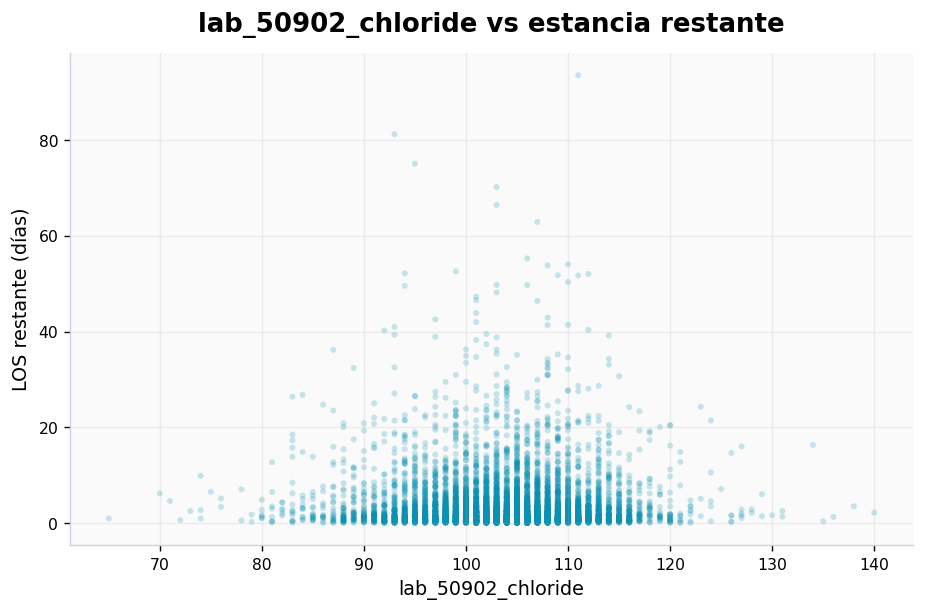

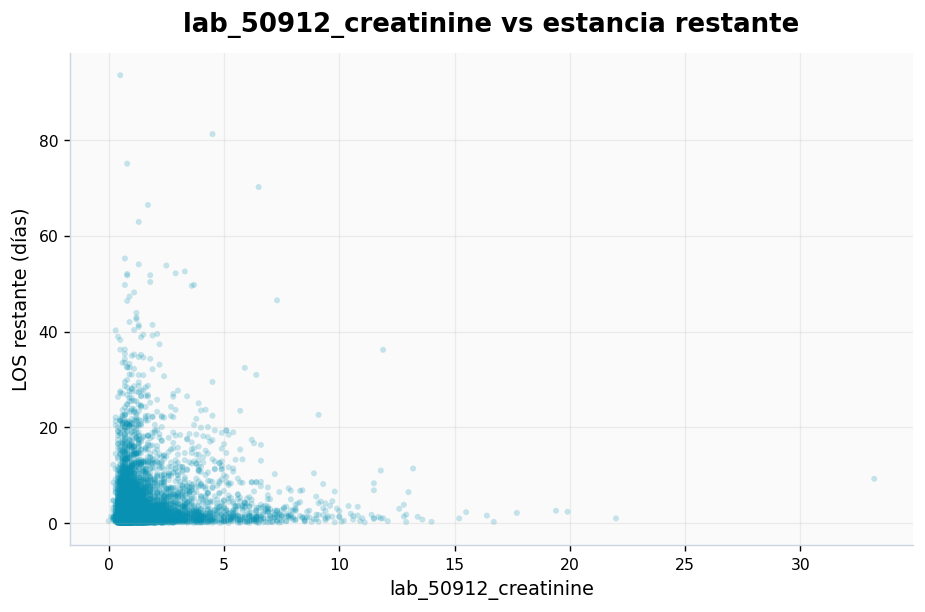

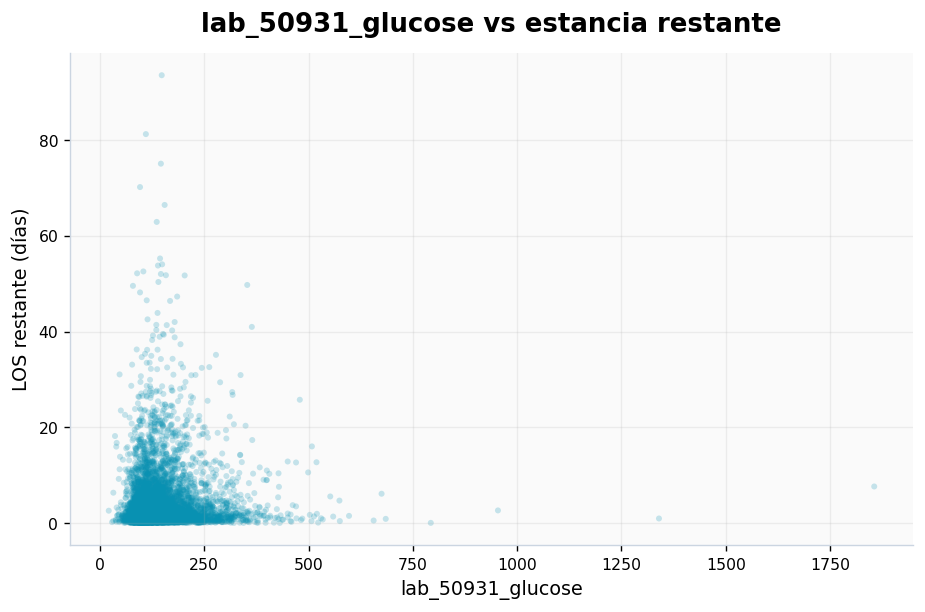

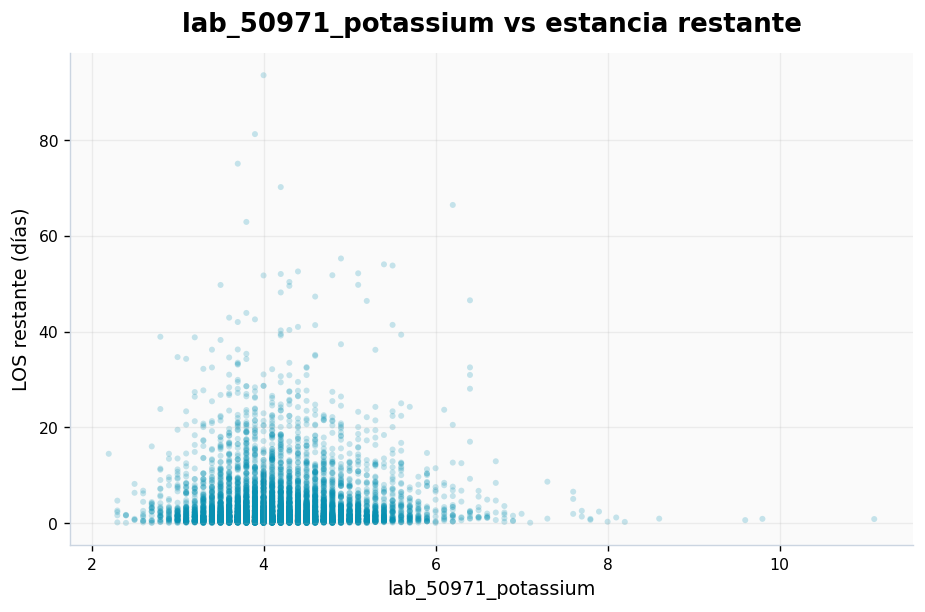

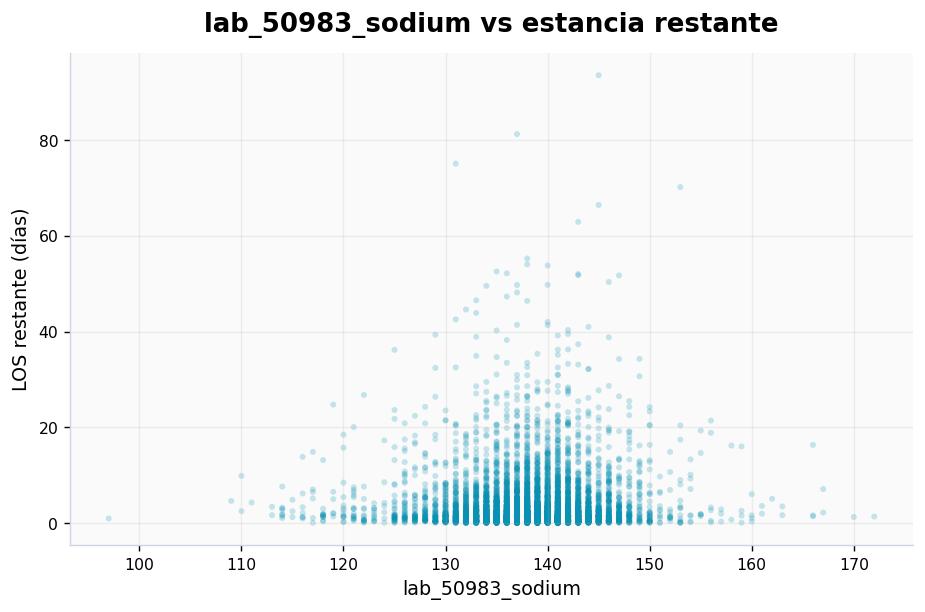

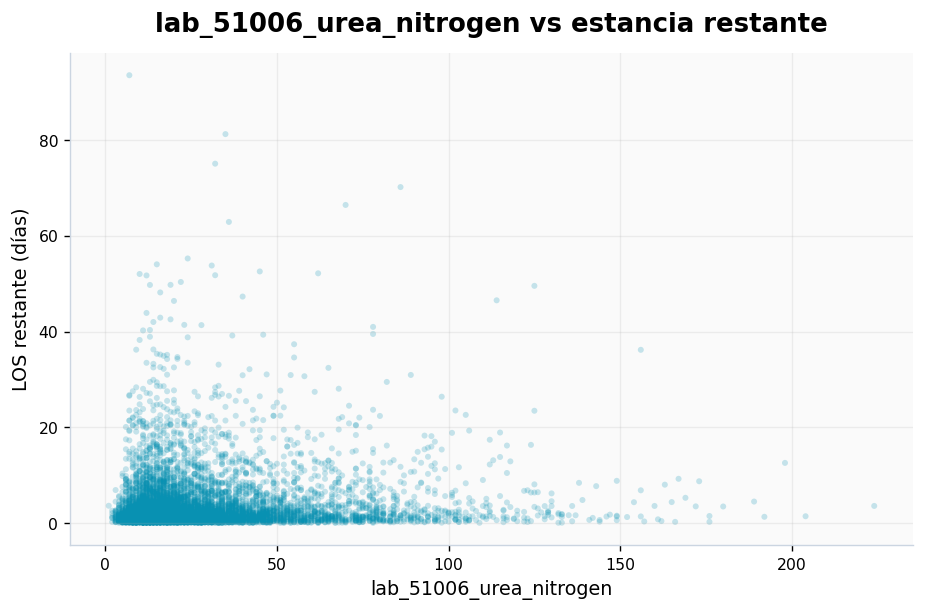

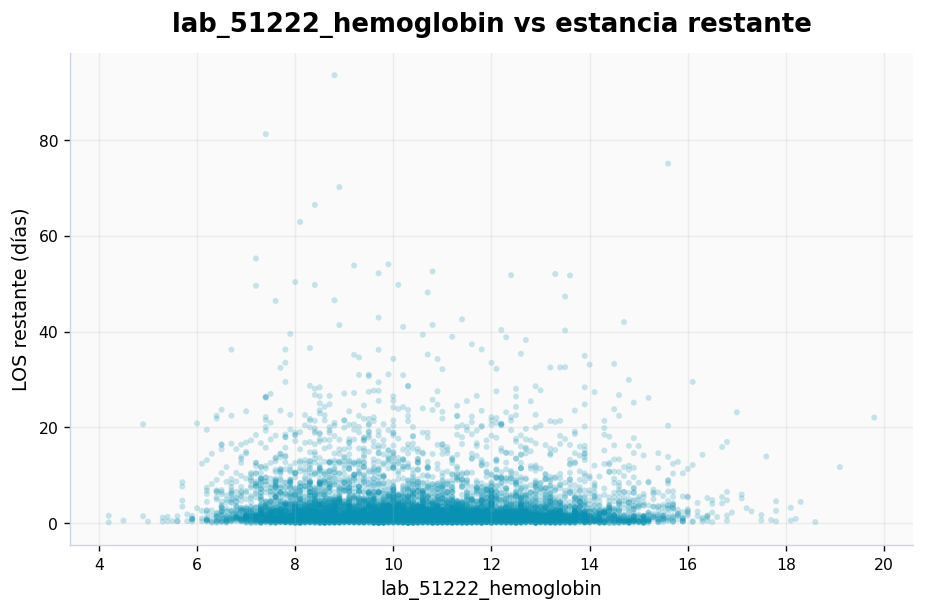

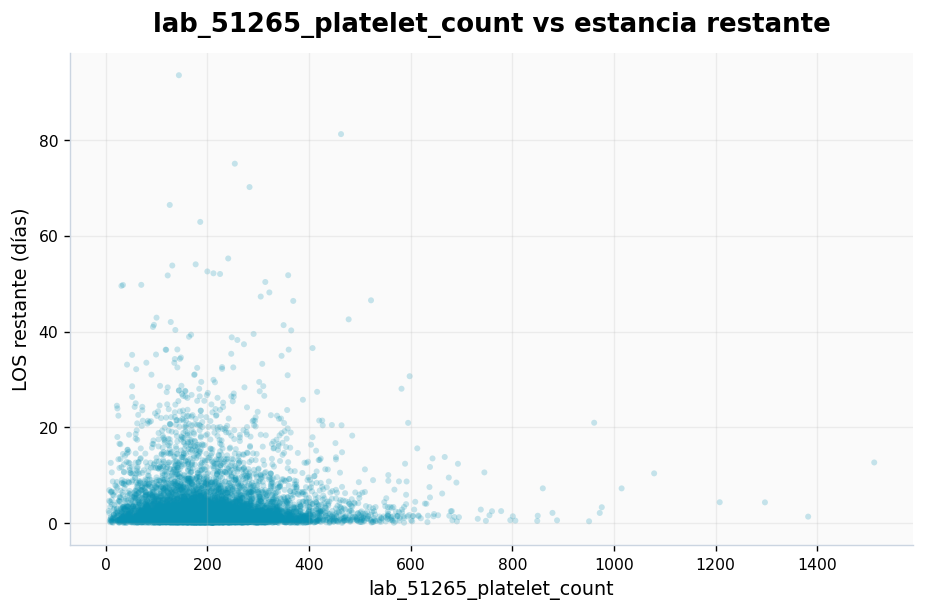

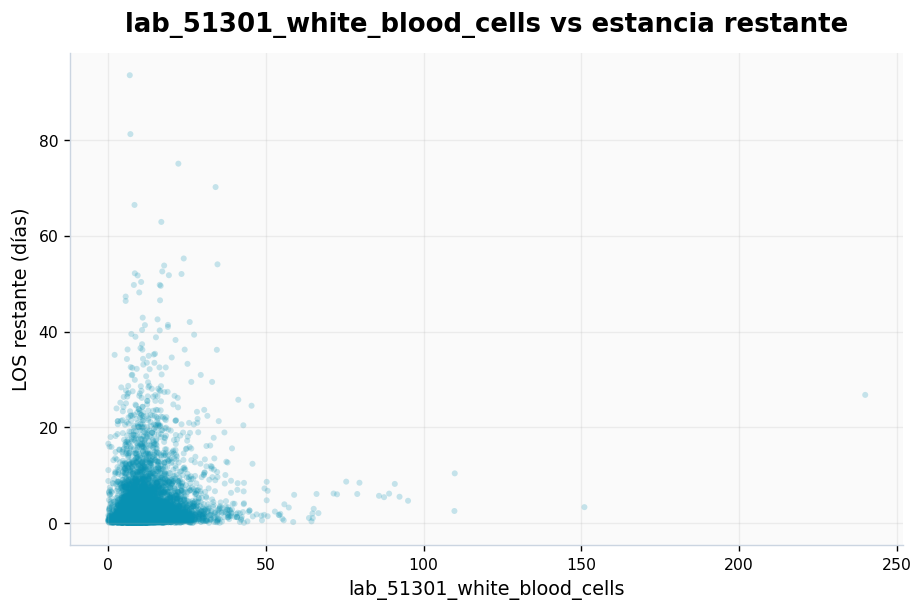

In [32]:
muestra = df.sample(min(10000, len(df)), random_state=42)

for c in num_pred:
    pares = muestra[[c,TARGET]].dropna()

    fig, ax = plt.subplots(figsize=(7.5,5))
    ax.scatter(pares[c], pares[TARGET], alpha=.22, s=12, color=TURQUESA, edgecolors="none")
    finalizar_grafica(
        ax,
        f"{c} vs estancia restante",
        c,
        "LOS restante (días)",
        grid_axis="both"
    )


## 12. Matriz de correlación entre predictores

Se revisa Spearman entre variables numéricas del dataset final. Los pares con `|ρ| ≥ 0.80` se reportan explícitamente como posibles redundancias antes de la regresión.


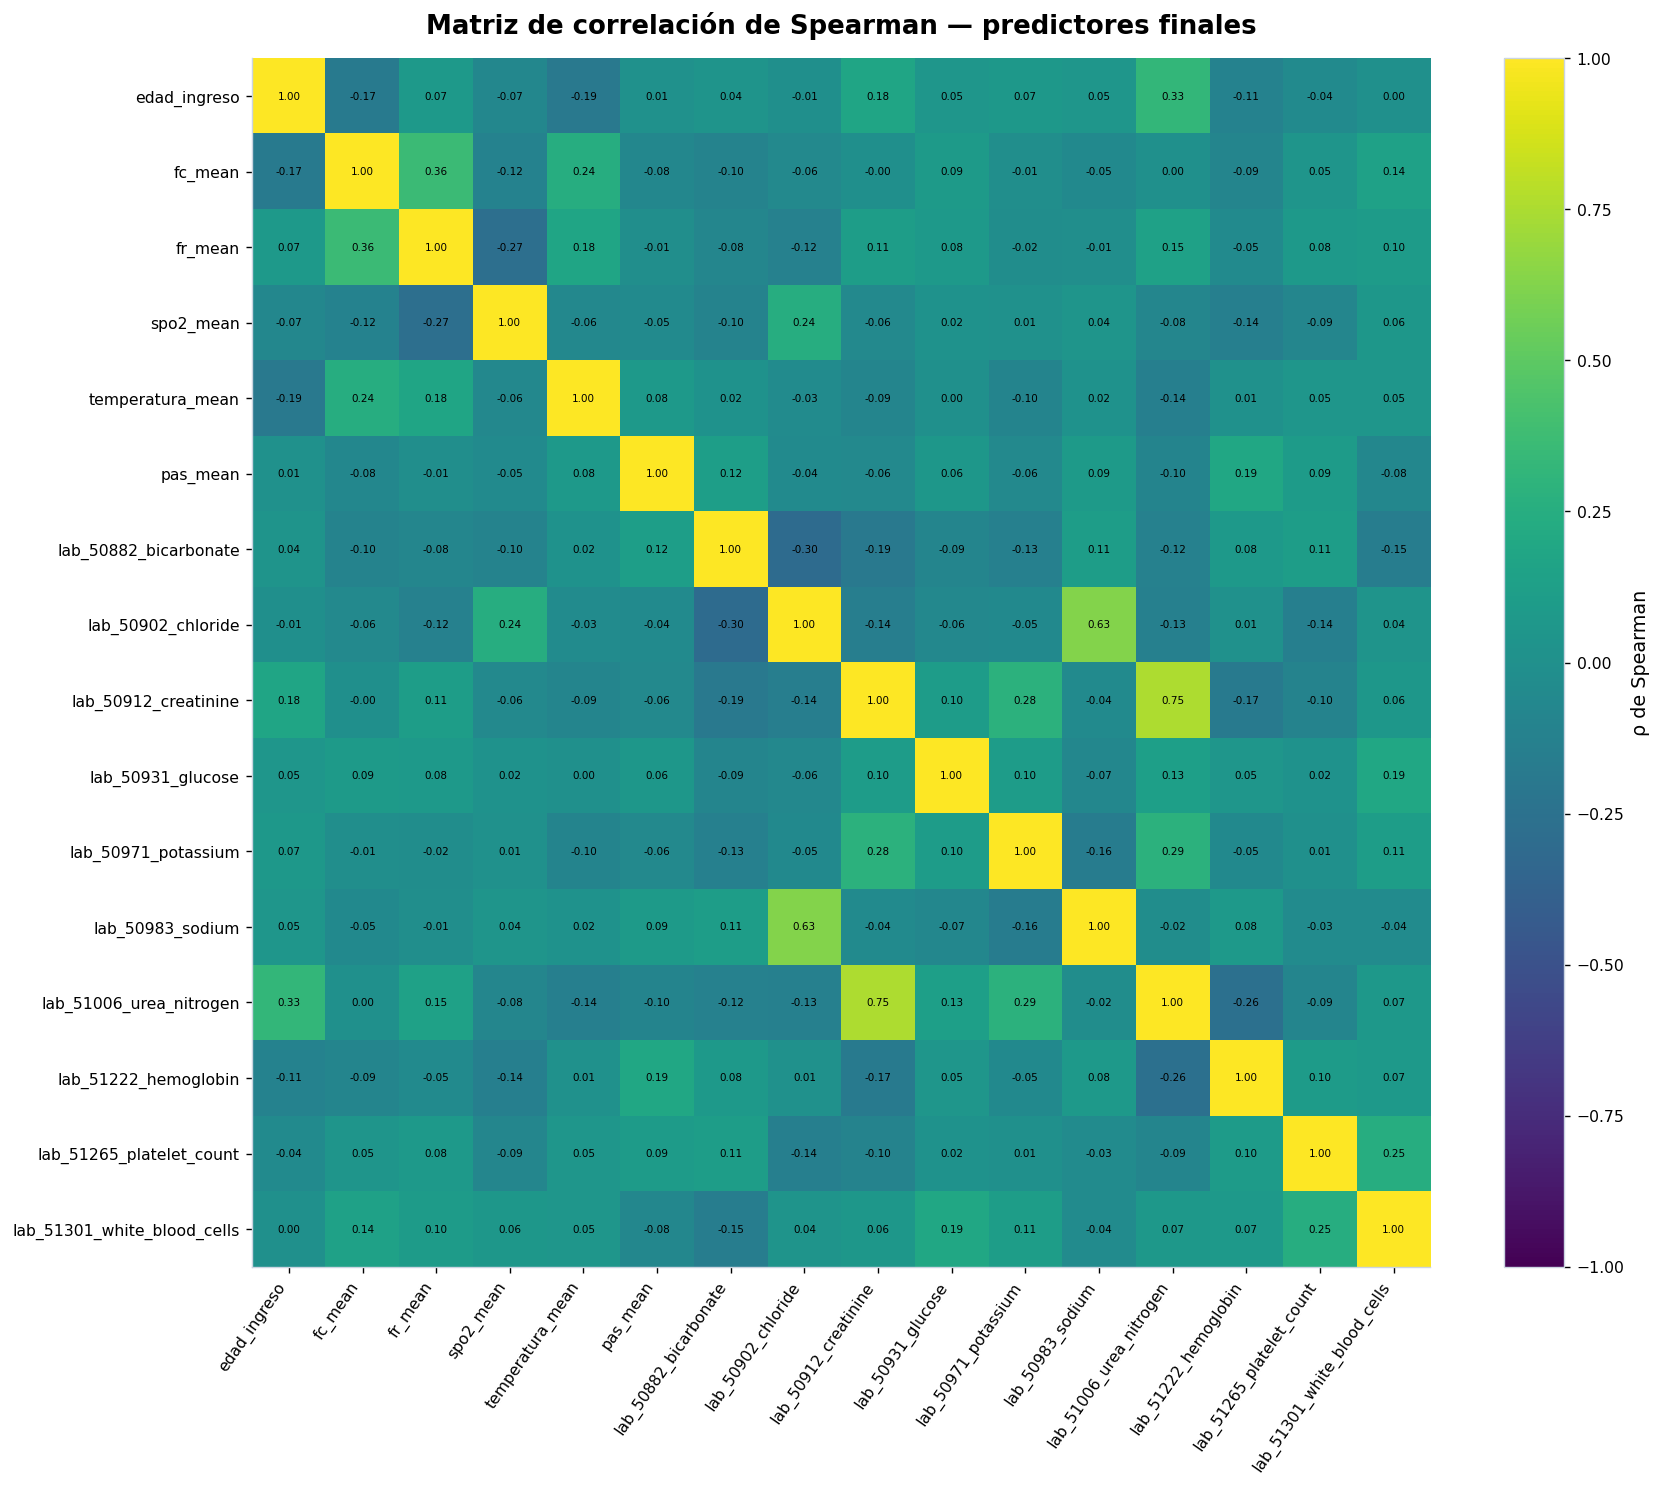

In [33]:
corr = df[num_pred].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14,12))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="ρ de Spearman")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=55, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

# Anotar valores para facilitar interpretación.
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}",
                ha="center", va="center", fontsize=6)

ax.set_title("Matriz de correlación de Spearman — predictores finales", pad=14)
fig.tight_layout()
plt.show()


In [34]:
upper = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pares_altos = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0":"variable_1","level_1":"variable_2",0:"rho_abs"})
    .query("rho_abs >= 0.80")
    .sort_values("rho_abs", ascending=False)
    .reset_index(drop=True)
)

print("Pares de predictores con |rho| >= 0.80:")
display(pares_altos)


Pares de predictores con |rho| >= 0.80:


,variable_1,variable_2,rho_abs


## 13. Relación entre faltantes y target

Se comprueba descriptivamente si las estancias con diferente cantidad de información disponible presentan diferencias en `los_restante_dias`. Esto ayuda a detectar si el patrón de missingness puede ser informativo.


,count,mean,median,std
grupo_faltantes_EDA,,,,
0%,58824,3.296,1.529,5.392
>0–10%,8198,4.362,2.078,6.774
>10–25%,12009,2.780,1.516,5.030
>25–50%,2488,3.232,1.635,5.434
>50%,8948,2.828,1.253,5.101


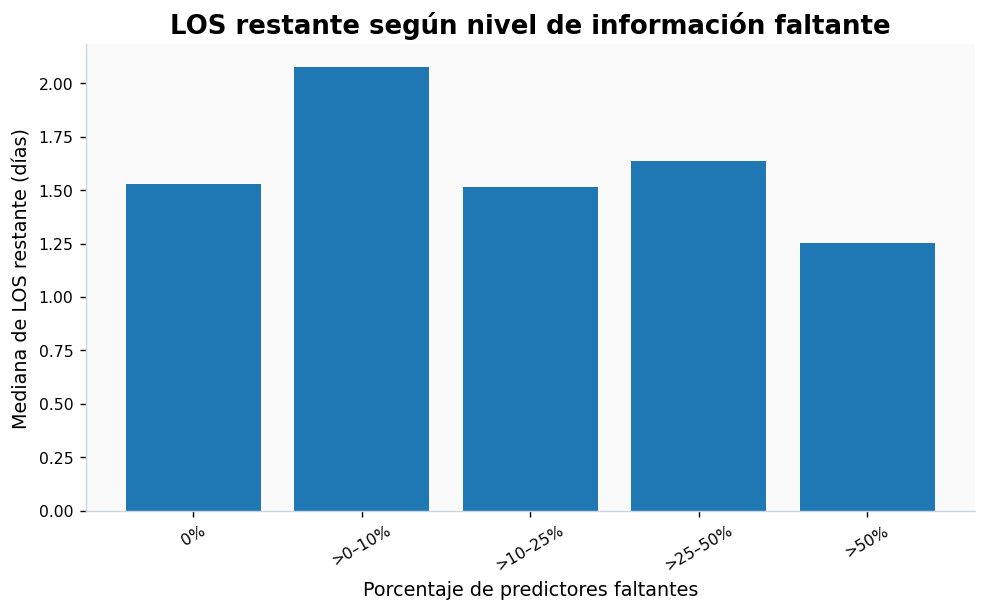

In [35]:
df["grupo_faltantes_EDA"] = pd.cut(
    df["pct_faltantes_predictores_EDA"],
    bins=[-0.01, 0, 10, 25, 50, 100],
    labels=["0%", ">0–10%", ">10–25%", ">25–50%", ">50%"]
)

missing_target = df.groupby(
    "grupo_faltantes_EDA", observed=True
)[TARGET].agg(["count","mean","median","std"])

display(missing_target)

plt.figure(figsize=(8,5))
plt.bar(
    missing_target.index.astype(str),
    missing_target["median"]
)
plt.xlabel("Porcentaje de predictores faltantes")
plt.ylabel("Mediana de LOS restante (días)")
plt.title("LOS restante según nivel de información faltante")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 14. Resumen automático de calidad del dataset

Esta tabla concentra los principales diagnósticos por variable y puede exportarse como anexo del EDA.


In [36]:
calidad = pd.DataFrame({"variable": df.columns})

calidad = calidad.merge(
    faltantes[["variable","n_faltantes","pct_faltantes"]],
    on="variable", how="left"
)

calidad["n_unicos"] = calidad["variable"].map(
    {c:df[c].nunique(dropna=True) for c in df.columns}
)

calidad["dtype"] = calidad["variable"].map(
    {c:str(df[c].dtype) for c in df.columns}
)

calidad = calidad.merge(
    tabla_outliers_iqr[["variable","n_outliers_IQR","pct_outliers_IQR"]],
    on="variable", how="left"
)

calidad = calidad.merge(
    tabla_outliers_mad[["variable","n_outliers_MAD","pct_outliers_MAD"]],
    on="variable", how="left"
)

calidad = calidad.merge(
    tabla_asociaciones[["variable","pearson_r","spearman_rho"]],
    on="variable", how="left"
)

display(calidad)


,variable,n_faltantes,pct_faltantes,n_unicos,dtype,n_outliers_IQR,pct_outliers_IQR,n_outliers_MAD,pct_outliers_MAD,pearson_r,spearman_rho
0,subject_id,0.000,0.000,63487,int64,NaN,NaN,NaN,NaN,NaN,NaN
1,stay_id,0.000,0.000,90467,int64,NaN,NaN,NaN,NaN,NaN,NaN
2,edad_ingreso,0.000,0.000,86,int64,772.000,0.853,0.000,0.000,-0.018,0.028
3,gender,0.000,0.000,2,object,NaN,NaN,NaN,NaN,NaN,NaN
4,fc_mean,111.000,0.123,13998,float64,923.000,1.022,192.000,0.212,0.084,0.100
5,fr_mean,389.000,0.430,5952,float64,"2,217.000",2.461,"1,012.000",1.123,0.003,0.128
6,spo2_mean,177.000,0.196,3506,float64,"1,092.000",1.209,509.000,0.564,0.001,0.061
7,temperatura_mean,"7,387.000",8.165,2667,float64,"5,406.000",6.507,"2,967.000",3.571,0.005,0.101
8,pas_mean,"15,282.000",16.892,10437,float64,893.000,1.188,216.000,0.287,-0.007,-0.074
9,lab_50882_bicarbonate,"10,533.000",11.643,52,float64,"3,619.000",4.527,"3,039.000",3.802,-0.040,-0.075


## 15. Conclusiones automáticas del EDA

Las siguientes líneas resumen hallazgos cuantitativos. Deben interpretarse junto con las tablas y gráficas anteriores.


In [37]:
print("=== RESUMEN EDA ===")
print(f"Observaciones: {len(df):,}")
print(f"Variables originales del dataset final: {len([c for c in df.columns if not c.endswith('_EDA') and c != 'grupo_faltantes_EDA'])}")
print(f"Duplicados completos: {df.drop(columns=['n_faltantes_predictores_EDA','pct_faltantes_predictores_EDA','grupo_faltantes_EDA'], errors='ignore').duplicated().sum():,}")

falt_real = faltantes[faltantes["n_faltantes"]>0]
print(f"Variables con al menos un faltante: {len(falt_real)}")
if len(falt_real):
    mayor = falt_real.iloc[0]
    print(f"Mayor porcentaje de faltantes: {mayor['variable']} ({mayor['pct_faltantes']:.2f}%)")

print(f"\nTarget — media: {df[TARGET].mean():.2f} días")
print(f"Target — mediana: {df[TARGET].median():.2f} días")
print(f"Target — P95: {df[TARGET].quantile(.95):.2f} días")
print(f"Target — P99: {df[TARGET].quantile(.99):.2f} días")
print(f"Target — asimetría: {df[TARGET].skew():.2f}")

print(f"\nPares de predictores con |rho| >= 0.80: {len(pares_altos)}")

if len(tabla_asociaciones):
    print("\nMayores asociaciones absolutas de Spearman con el target:")
    display(tabla_asociaciones[["variable","spearman_rho"]].head(10))


=== RESUMEN EDA ===
Observaciones: 90,467
Variables originales del dataset final: 20
Duplicados completos: 0
Variables con al menos un faltante: 15
Mayor porcentaje de faltantes: lab_50931_glucose (20.70%)

Target — media: 3.28 días
Target — mediana: 1.55 días
Target — P95: 12.45 días
Target — P99: 26.40 días
Target — asimetría: 6.20

Pares de predictores con |rho| >= 0.80: 0

Mayores asociaciones absolutas de Spearman con el target:


,variable,spearman_rho
12,lab_51006_urea_nitrogen,0.132
2,fr_mean,0.128
15,lab_51301_white_blood_cells,0.124
9,lab_50931_glucose,0.108
4,temperatura_mean,0.101
8,lab_50912_creatinine,0.100
1,fc_mean,0.100
6,lab_50882_bicarbonate,-0.075
5,pas_mean,-0.074
13,lab_51222_hemoglobin,-0.068


## 16. Exportar tablas del EDA

Se exportan las tablas diagnósticas. El dataset original no se sobrescribe.


In [38]:
OUTPUT_DIR = RESULTS_DIR / "eda_resultados"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

faltantes.to_csv(OUTPUT_DIR/"01_faltantes.csv", index=False)
desc.to_csv(OUTPUT_DIR/"02_descriptivos_numericos.csv")
tabla_outliers_iqr.to_csv(OUTPUT_DIR/"03_outliers_IQR.csv", index=False)
tabla_outliers_mad.to_csv(OUTPUT_DIR/"04_outliers_MAD.csv", index=False)
tabla_plausibilidad.to_csv(OUTPUT_DIR/"05_revision_plausibilidad.csv", index=False)
tabla_asociaciones.to_csv(OUTPUT_DIR/"06_asociaciones_target.csv", index=False)
pares_altos.to_csv(OUTPUT_DIR/"07_correlaciones_altas.csv", index=False)
calidad.to_csv(OUTPUT_DIR/"08_resumen_calidad_variables.csv", index=False)

print("Tablas guardadas en:", OUTPUT_DIR.resolve())


Tablas guardadas en: C:\Users\grise\Downloads\estancia-hospitalaria-uci\results\eda_resultados


# Fin del EDA original

Hasta este punto se conserva el diagnóstico exploratorio. A continuación se añade la fase de **limpieza, separación por paciente y evaluación de imputación**, manteniendo explícitamente aislado el conjunto de prueba.


# 17. Limpieza del dataset

A partir de los hallazgos del EDA se aplica una limpieza **conservadora**:

1. No se eliminan outliers únicamente por IQR o MAD, porque en UCI pueden representar pacientes realmente graves.
2. Los valores que exceden los límites amplios de control de calidad se convierten a `NaN`; se conserva la estancia.
3. La temperatura se convierte de Fahrenheit a Celsius.
4. No se eliminan filas por tener laboratorios faltantes.
5. El target no se winsoriza ni se recorta.
6. La imputación se realiza **después de separar entrenamiento y prueba por `subject_id`** para evitar fuga de información.


In [39]:
# Trabajamos sobre una copia limpia; el dataframe original del EDA queda intacto.
df_limpio = df.drop(
    columns=[
        "n_faltantes_predictores_EDA",
        "pct_faltantes_predictores_EDA",
        "grupo_faltantes_EDA"
    ],
    errors="ignore"
).copy()

registro_limpieza = []

for c, (li, ls) in rangos_revision.items():
    if c not in df_limpio.columns:
        continue

    mask = df_limpio[c].notna() & (
        (df_limpio[c] < li) | (df_limpio[c] > ls)
    )

    registro_limpieza.append({
        "variable": c,
        "valores_convertidos_a_NaN": int(mask.sum()),
        "pct_sobre_no_faltantes_originales":
            mask.sum() / df_limpio[c].notna().sum() * 100
    })

    # No borramos al paciente: invalidamos solamente esa medición.
    df_limpio.loc[mask, c] = np.nan

tabla_limpieza = pd.DataFrame(registro_limpieza)
display(tabla_limpieza.sort_values("valores_convertidos_a_NaN", ascending=False))


,variable,valores_convertidos_a_NaN,pct_sobre_no_faltantes_originales
4,temperatura_mean,169,0.203
3,spo2_mean,32,0.035
15,lab_51301_white_blood_cells,27,0.035
8,lab_50912_creatinine,12,0.015
2,fr_mean,11,0.012
5,pas_mean,10,0.013
1,fc_mean,2,0.002
14,lab_51265_platelet_count,2,0.003
10,lab_50971_potassium,1,0.001
9,lab_50931_glucose,1,0.001


## 17.1 Conversión de temperatura a Celsius

`temperatura_mean` se encontraba en Fahrenheit. Después de invalidar valores incompatibles con esa unidad, se convierte a Celsius para mejorar interpretación y consistencia.


In [40]:
if "temperatura_mean" in df_limpio.columns:
    df_limpio["temperatura_mean"] = (
        df_limpio["temperatura_mean"] - 32
    ) * 5/9

    df_limpio = df_limpio.rename(
        columns={"temperatura_mean": "temperatura_c_mean"}
    )

    print(df_limpio["temperatura_c_mean"].describe())


count   82,911.000
mean        36.813
std          0.568
min         25.176
25%         36.556
50%         36.792
75%         37.056
max         40.750
Name: temperatura_c_mean, dtype: float64


## 17.2 Verificación posterior a la limpieza

Se comprueba que la limpieza no haya eliminado estancias ni modificado el target.


In [41]:
print(f"Filas antes: {len(df):,}")
print(f"Filas después: {len(df_limpio):,}")
print("Filas eliminadas:", len(df)-len(df_limpio))

print("\nFaltantes después de invalidar mediciones incompatibles:")
faltantes_post = (
    df_limpio.isna().mean().mul(100)
    .sort_values(ascending=False)
    .to_frame("pct_faltantes")
)
display(faltantes_post)

assert len(df_limpio) == len(df)
assert df_limpio[TARGET].equals(df[TARGET])


Filas antes: 90,467
Filas después: 90,467
Filas eliminadas: 0

Faltantes después de invalidar mediciones incompatibles:


,pct_faltantes
lab_50931_glucose,20.703
pas_mean,16.903
lab_50983_sodium,16.387
lab_51301_white_blood_cells,14.236
lab_51222_hemoglobin,14.136
lab_51265_platelet_count,14.017
lab_50971_potassium,13.157
lab_50882_bicarbonate,11.643
lab_51006_urea_nitrogen,11.541
lab_50912_creatinine,11.498


# 18. Separación Train/Test por paciente

La separación se realiza por `subject_id`, no por filas. De esta manera, si un paciente tiene más de una estancia, todas sus estancias permanecen en un solo conjunto.

Esto debe hacerse **antes de imputar**. De lo contrario, la imputación podría utilizar información de pacientes que posteriormente pertenecerán al conjunto de prueba.


In [42]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

idx_train, idx_test = next(
    gss.split(df_limpio, groups=df_limpio["subject_id"])
)

train = df_limpio.iloc[idx_train].copy()
test = df_limpio.iloc[idx_test].copy()

print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")

pacientes_comunes = set(train["subject_id"]) & set(test["subject_id"])
print("Pacientes presentes en ambos conjuntos:", len(pacientes_comunes))

assert len(pacientes_comunes) == 0


Train: (72469, 20)
Test:  (17998, 20)
Pacientes presentes en ambos conjuntos: 0


# 19. ¿KNN o mediana para imputar?

**KNN puede ser una buena opción para datos clínicos, pero no es automáticamente mejor por tratarse de datos clínicos.** Su ventaja es que estima un valor a partir de pacientes con perfiles similares en varias variables.

Tiene dos consideraciones importantes:

- es sensible a la escala, por lo que las variables deben estandarizarse antes de calcular vecinos;
- puede ser considerablemente más costoso que una imputación por mediana con decenas de miles de observaciones.

Por eso este notebook no elige KNN por intuición. Primero compara **mediana vs KNN** ocultando artificialmente valores observados del conjunto de entrenamiento y midiendo qué tan bien los recupera. El conjunto de prueba real permanece completamente aislado.


In [43]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Solo predictores numéricos. IDs y target jamás se imputan como predictores.
numeric_features = [
    c for c in train.select_dtypes(include=np.number).columns
    if c not in IDS + [TARGET]
]

print("Predictores numéricos para imputación:")
print(numeric_features)


Predictores numéricos para imputación:
['edad_ingreso', 'fc_mean', 'fr_mean', 'spo2_mean', 'temperatura_c_mean', 'pas_mean', 'lab_50882_bicarbonate', 'lab_50902_chloride', 'lab_50912_creatinine', 'lab_50931_glucose', 'lab_50971_potassium', 'lab_50983_sodium', 'lab_51006_urea_nitrogen', 'lab_51222_hemoglobin', 'lab_51265_platelet_count', 'lab_51301_white_blood_cells']


## 19.1 Comparación experimental de imputadores

Para que la evaluación sea computacionalmente razonable, se toma una muestra reproducible del train, se seleccionan valores originalmente observados y se oculta aproximadamente 10% de ellos. Después se compara el error de reconstrucción.

La selección del imputador se basa en **MAE estandarizado**, de modo que variables con unidades grandes no dominen el resultado.


In [44]:
rng = np.random.default_rng(42)

# KNNImputer puede ser costoso en 90 mil filas; la comparación se hace en una
# muestra suficientemente grande del TRAIN, nunca del TEST.
n_eval = min(12000, len(train))
eval_df = train[numeric_features].sample(n=n_eval, random_state=42).copy()

# Estandarización aprendida solo con la muestra de train.
scaler_eval = StandardScaler()
eval_scaled = pd.DataFrame(
    scaler_eval.fit_transform(eval_df),
    columns=numeric_features,
    index=eval_df.index
)

# Ocultamos 10% de valores que originalmente sí estaban observados.
observed = eval_scaled.notna().to_numpy()
mask_candidates = np.argwhere(observed)
n_hide = int(len(mask_candidates) * 0.10)

chosen = mask_candidates[
    rng.choice(len(mask_candidates), size=n_hide, replace=False)
]

masked = eval_scaled.copy()
truth = []
positions = []

for r, c in chosen:
    truth.append(eval_scaled.iat[r, c])
    positions.append((r, c))
    masked.iat[r, c] = np.nan

truth = np.asarray(truth)

resultados_imputacion = []

# Baseline: mediana
med_imp = SimpleImputer(strategy="median")
med_arr = med_imp.fit_transform(masked)
pred = np.array([med_arr[r,c] for r,c in positions])

resultados_imputacion.append({
    "metodo":"Mediana",
    "MAE_estandarizado":mean_absolute_error(truth,pred),
    "RMSE_estandarizado":np.sqrt(mean_squared_error(truth,pred))
})

# KNN con distintos k
for k in [3, 5, 7, 10]:
    imp = KNNImputer(n_neighbors=k, weights="distance")
    arr = imp.fit_transform(masked)
    pred = np.array([arr[r,c] for r,c in positions])

    resultados_imputacion.append({
        "metodo":f"KNN k={k}",
        "MAE_estandarizado":mean_absolute_error(truth,pred),
        "RMSE_estandarizado":np.sqrt(mean_squared_error(truth,pred))
    })

comparacion_imputadores = (
    pd.DataFrame(resultados_imputacion)
    .sort_values("MAE_estandarizado")
    .reset_index(drop=True)
)

display(comparacion_imputadores)


,metodo,MAE_estandarizado,RMSE_estandarizado
0,KNN k=10,0.693,0.955
1,Mediana,0.703,0.986
2,KNN k=7,0.707,0.973
3,KNN k=5,0.724,0.994
4,KNN k=3,0.759,1.043


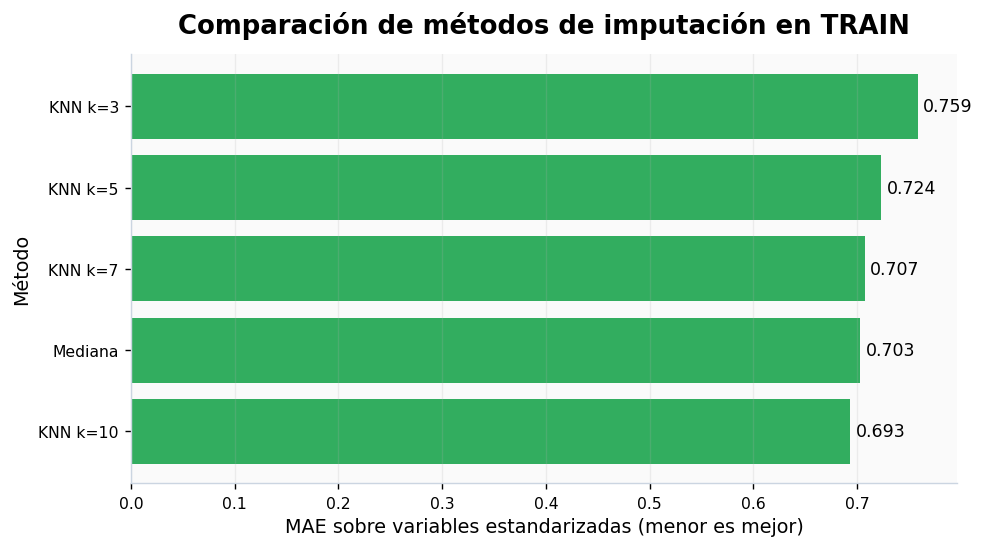

In [45]:
fig, ax = plt.subplots(figsize=(8,4.5))
orden = comparacion_imputadores.sort_values("MAE_estandarizado", ascending=True)
bars = ax.barh(orden["metodo"], orden["MAE_estandarizado"], color=VERDE, alpha=0.88)
ax.bar_label(bars, fmt="%.3f", padding=3)
finalizar_grafica(
    ax,
    "Comparación de métodos de imputación en TRAIN",
    "MAE sobre variables estandarizadas (menor es mejor)",
    "Método",
    grid_axis="x"
)


## 19.2 Imputación definitiva sin fuga de información

El bloque siguiente utiliza automáticamente el método con menor MAE en la comparación anterior.

Si gana KNN:
- el escalador se ajusta solo con `train`;
- KNN se ajusta solo con `train`;
- `test` únicamente se transforma;
- finalmente se regresan las variables a sus unidades originales para guardar un dataset interpretable.

Si gana mediana, la mediana también se estima únicamente con `train`.

`gender` no se imputa con KNN en este notebook; se conserva como variable categórica y se codificará dentro del pipeline del modelo.


In [46]:
mejor_metodo = comparacion_imputadores.iloc[0]["metodo"]
print("Método seleccionado:", mejor_metodo)

X_train_num = train[numeric_features].copy()
X_test_num = test[numeric_features].copy()

if mejor_metodo.startswith("KNN"):
    mejor_k = int(mejor_metodo.split("=")[1])

    # StandardScaler ignora NaN al estimar media/desviación.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_test_scaled = scaler.transform(X_test_num)

    imputer = KNNImputer(
        n_neighbors=mejor_k,
        weights="distance"
    )

    # IMPORTANTE: fit solo en train.
    X_train_imp_scaled = imputer.fit_transform(X_train_scaled)
    X_test_imp_scaled = imputer.transform(X_test_scaled)

    # Volvemos a unidades originales para guardar los datos limpios.
    X_train_imp = scaler.inverse_transform(X_train_imp_scaled)
    X_test_imp = scaler.inverse_transform(X_test_imp_scaled)

else:
    imputer = SimpleImputer(strategy="median")
    X_train_imp = imputer.fit_transform(X_train_num)
    X_test_imp = imputer.transform(X_test_num)

train_imputado = train.copy()
test_imputado = test.copy()

train_imputado[numeric_features] = X_train_imp
test_imputado[numeric_features] = X_test_imp

print("Faltantes numéricos TRAIN después:", train_imputado[numeric_features].isna().sum().sum())
print("Faltantes numéricos TEST después:", test_imputado[numeric_features].isna().sum().sum())


Método seleccionado: KNN k=10
Faltantes numéricos TRAIN después: 0
Faltantes numéricos TEST después: 0


# 20. Verificación de la imputación

La imputación no debe generar valores absurdos. Se comparan cuantiles antes y después. Esta revisión es especialmente importante con KNN.


In [47]:
comparacion_post = []

for c in numeric_features:
    comparacion_post.append({
        "variable": c,
        "faltantes_antes_train": train[c].isna().sum(),
        "faltantes_despues_train": train_imputado[c].isna().sum(),
        "mediana_antes": train[c].median(),
        "mediana_despues": train_imputado[c].median(),
        "p01_despues": train_imputado[c].quantile(.01),
        "p99_despues": train_imputado[c].quantile(.99)
    })

tabla_post_imputacion = pd.DataFrame(comparacion_post)
display(tabla_post_imputacion)


,variable,faltantes_antes_train,faltantes_despues_train,mediana_antes,mediana_despues,p01_despues,p99_despues
0,edad_ingreso,0,0,66.000,66.000,22.000,92.000
1,fc_mean,90,0,83.308,83.308,51.388,129.500
2,fr_mean,334,0,18.364,18.364,11.738,31.471
3,spo2_mean,167,0,97.250,97.250,90.750,100.000
4,temperatura_c_mean,5998,0,36.792,36.792,35.542,38.254
5,pas_mean,12252,0,116.000,118.024,84.231,167.500
6,lab_50882_bicarbonate,8461,0,23.000,23.000,12.000,36.000
7,lab_50902_chloride,8219,0,104.000,104.511,86.000,119.000
8,lab_50912_creatinine,8360,0,1.000,1.000,0.400,8.500
9,lab_50931_glucose,15034,0,125.000,130.823,64.000,354.000


# 21. Guardar datasets listos para el modelado

Se guardan por separado:

- dataset limpio previo a imputación;
- train imputado;
- test imputado;
- registro de limpieza;
- comparación de imputadores.

No se sobrescribe el dataset maestro.


In [48]:
OUTPUT_CLEAN = PROCESSED_DIR
OUTPUT_CLEAN.mkdir(parents=True, exist_ok=True)

df_limpio.to_csv(
    OUTPUT_CLEAN/"mimic_uci_12h_limpio_pre_split.csv.gz",
    index=False,
    compression="gzip"
)

train_imputado.to_csv(
    OUTPUT_CLEAN/"mimic_uci_12h_train_imputado.csv.gz",
    index=False,
    compression="gzip"
)

test_imputado.to_csv(
    OUTPUT_CLEAN/"mimic_uci_12h_test_imputado.csv.gz",
    index=False,
    compression="gzip"
)

tabla_limpieza.to_csv(
    OUTPUT_CLEAN/"registro_limpieza.csv",
    index=False
)

comparacion_imputadores.to_csv(
    OUTPUT_CLEAN/"comparacion_imputadores.csv",
    index=False
)

tabla_post_imputacion.to_csv(
    OUTPUT_CLEAN/"revision_post_imputacion.csv",
    index=False
)

print("Archivos guardados en:", OUTPUT_CLEAN.resolve())


Archivos guardados en: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\processed


# Conclusión de limpieza

La estrategia evita confundir **outlier estadístico** con **error clínico**. Los extremos de laboratorios y del target se conservan mientras sean observaciones posibles; únicamente las mediciones incompatibles con los controles amplios de calidad se convierten a faltantes.

La imputación no se decide por el tipo de datos, sino mediante una evaluación reproducible dentro de `train`. KNN es especialmente razonable cuando pacientes con perfiles multivariables similares permiten reconstruir valores faltantes mejor que una mediana global, pero se utiliza únicamente si demuestra menor error en esta comparación.

A partir de los archivos `train_imputado` y `test_imputado` ya puede comenzar el notebook de preparación para regresión: codificación de `gender`, diagnóstico de VIF, transformaciones que se decidan para el target y comparación de modelos.


# 22. EDA posterior a la limpieza

Hasta aquí ya se realizó:

- control de calidad de valores incompatibles;
- conversión de temperatura a °C;
- separación por paciente;
- evaluación de mediana frente a KNN;
- imputación utilizando únicamente información de entrenamiento.

Ahora se repite el EDA sobre los datos **después de la limpieza** para verificar que el procedimiento haya mejorado la calidad sin distorsionar las distribuciones clínicas.

Se analiza por separado:

1. dataset limpio antes de imputación;
2. TRAIN después de imputación;
3. comparación antes vs después;
4. distribución del target;
5. distribuciones de predictores;
6. valores faltantes;
7. outliers;
8. correlaciones;
9. asociación con el target.


## 22.1 Dimensiones e integridad después de la limpieza


In [49]:
print("=== DATASET LIMPIO PRE-SPLIT ===")
print(f"Filas: {len(df_limpio):,}")
print(f"Columnas: {df_limpio.shape[1]}")
print(f"Duplicados completos: {df_limpio.duplicated().sum():,}")
print(f"Pacientes únicos: {df_limpio['subject_id'].nunique():,}")
print(f"Estancias únicas: {df_limpio['stay_id'].nunique():,}")

print("\n=== TRAIN IMPUTADO ===")
print(f"Filas: {len(train_imputado):,}")
print(f"Columnas: {train_imputado.shape[1]}")

print("\n=== TEST IMPUTADO ===")
print(f"Filas: {len(test_imputado):,}")
print(f"Columnas: {test_imputado.shape[1]}")

assert set(train_imputado["subject_id"]).isdisjoint(set(test_imputado["subject_id"]))


=== DATASET LIMPIO PRE-SPLIT ===
Filas: 90,467
Columnas: 20
Duplicados completos: 0
Pacientes únicos: 63,487
Estancias únicas: 90,467

=== TRAIN IMPUTADO ===
Filas: 72,469
Columnas: 20

=== TEST IMPUTADO ===
Filas: 17,998
Columnas: 20


## 22.2 Valores faltantes antes y después

Esta comparación permite comprobar visualmente qué variables requerían mayor imputación y verificar que los predictores numéricos hayan quedado completos.


,Antes de imputar,Después de imputar
lab_50931_glucose,20.745,0.000
pas_mean,16.907,0.000
lab_50983_sodium,16.392,0.000
lab_51301_white_blood_cells,14.279,0.000
lab_51222_hemoglobin,14.173,0.000
lab_51265_platelet_count,14.067,0.000
lab_50971_potassium,13.179,0.000
lab_50882_bicarbonate,11.675,0.000
lab_51006_urea_nitrogen,11.579,0.000
lab_50912_creatinine,11.536,0.000


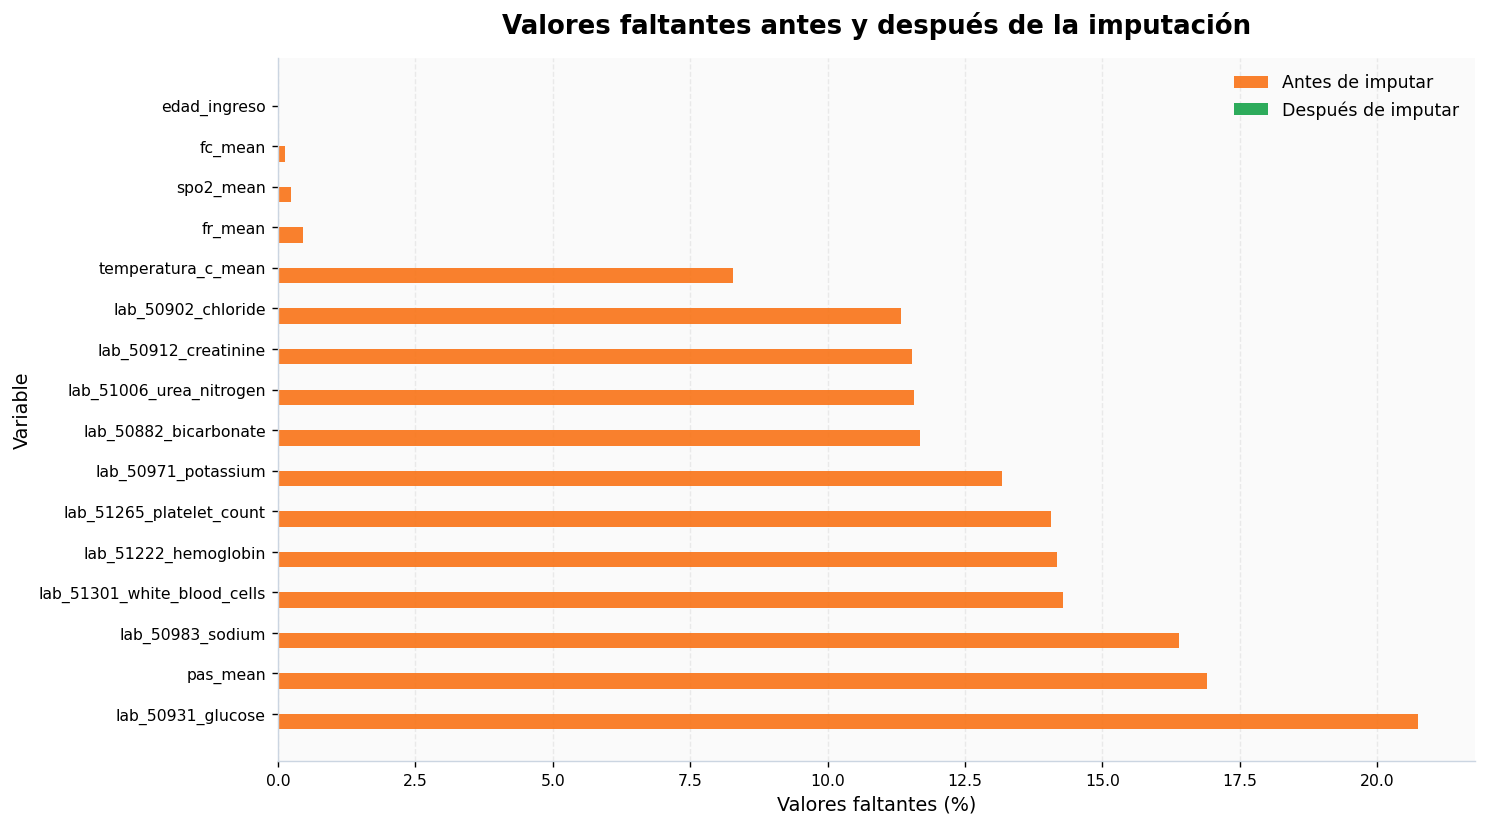

In [50]:
falt_pre = (
    train[numeric_features].isna().mean().mul(100)
    .sort_values(ascending=False)
)
falt_post = (
    train_imputado[numeric_features].isna().mean().mul(100)
    .reindex(falt_pre.index)
)

comp_falt = pd.DataFrame({
    "Antes de imputar": falt_pre,
    "Después de imputar": falt_post
})

display(comp_falt)

fig, ax = plt.subplots(figsize=(12, max(6, len(comp_falt)*0.42)))
y = np.arange(len(comp_falt))
h = 0.38

ax.barh(y-h/2, comp_falt["Antes de imputar"], height=h,
        color=NARANJA, label="Antes de imputar", alpha=.90)
ax.barh(y+h/2, comp_falt["Después de imputar"], height=h,
        color=VERDE, label="Después de imputar", alpha=.90)

ax.set_yticks(y)
ax.set_yticklabels(comp_falt.index)
ax.legend()
formato_ax(
    ax,
    "Valores faltantes antes y después de la imputación",
    "Valores faltantes (%)",
    "Variable",
    eje_grid="x"
)
plt.tight_layout()
plt.show()


## 22.3 Comparación de distribuciones antes y después de imputar

Las curvas se representan mediante histogramas con los mismos intervalos. Una imputación adecuada no debería crear cambios abruptos en la forma general de las distribuciones.


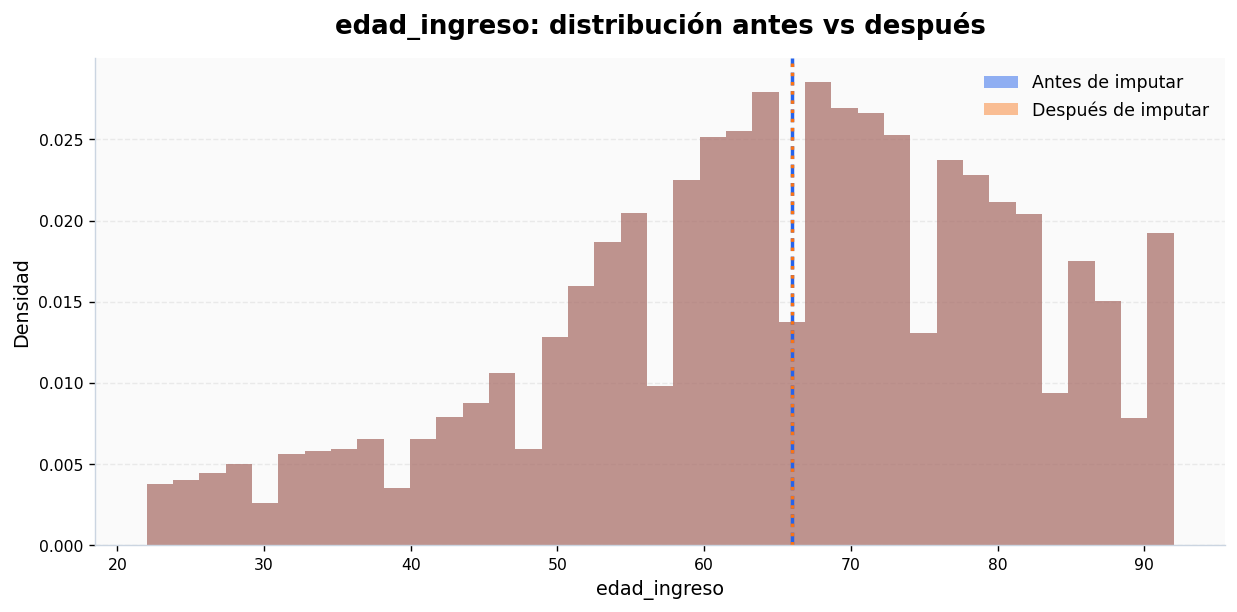

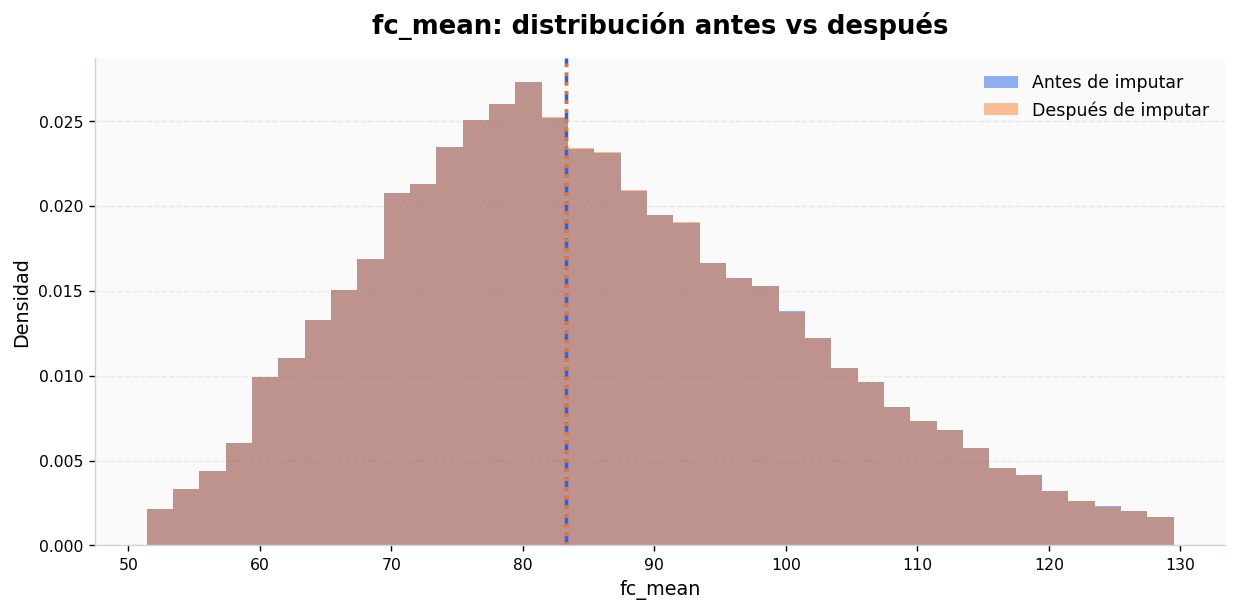

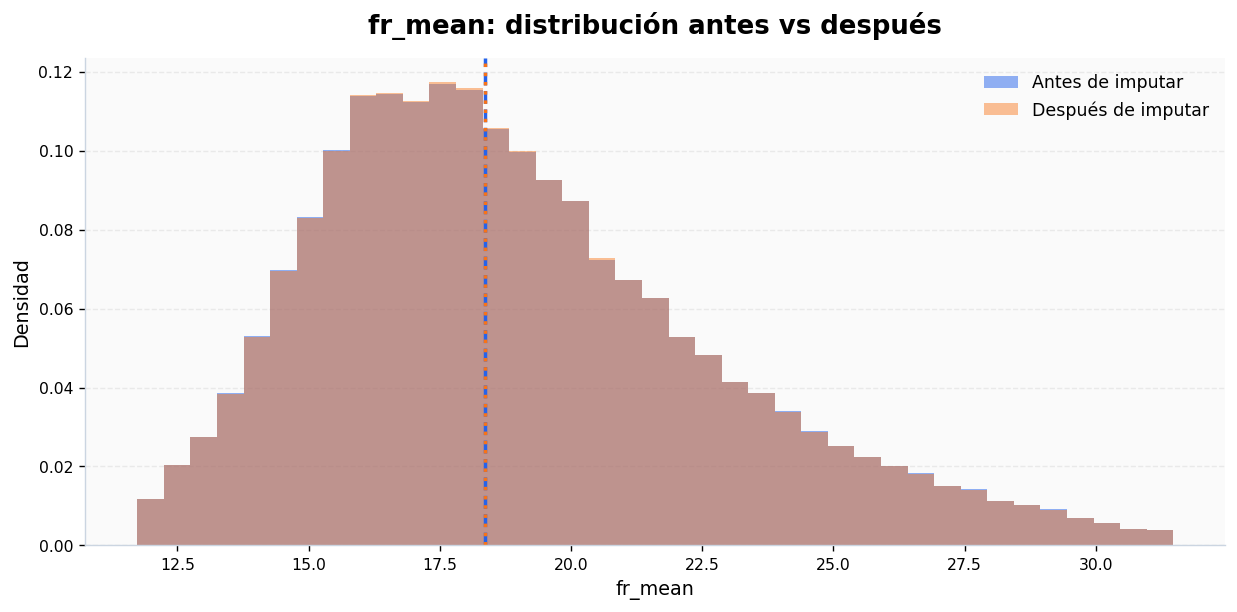

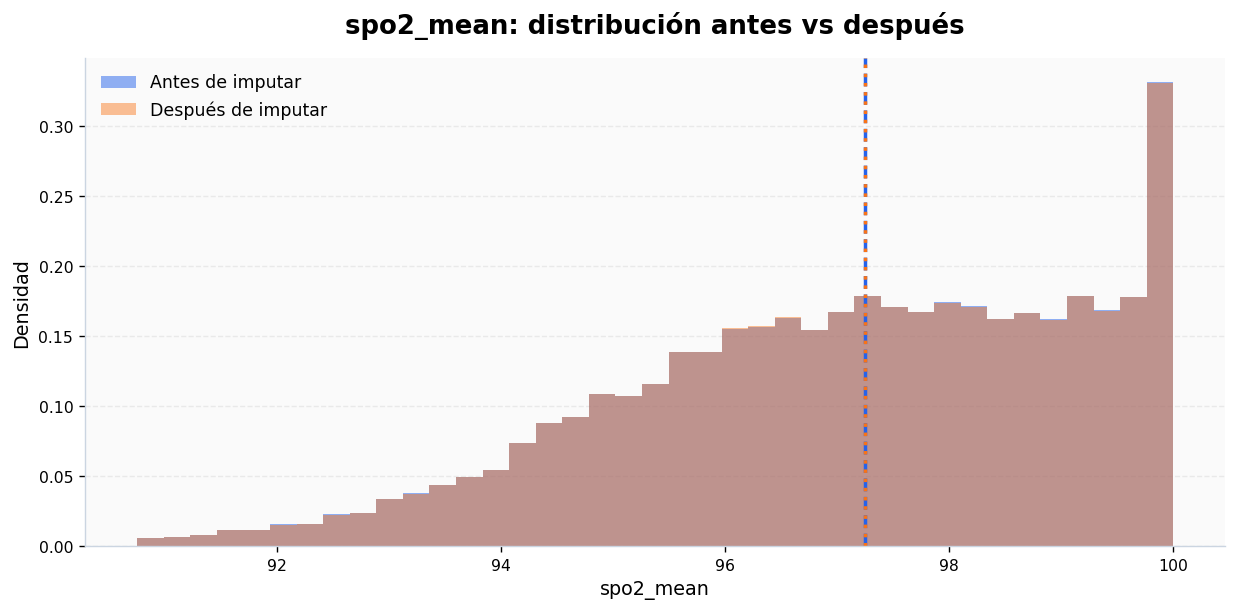

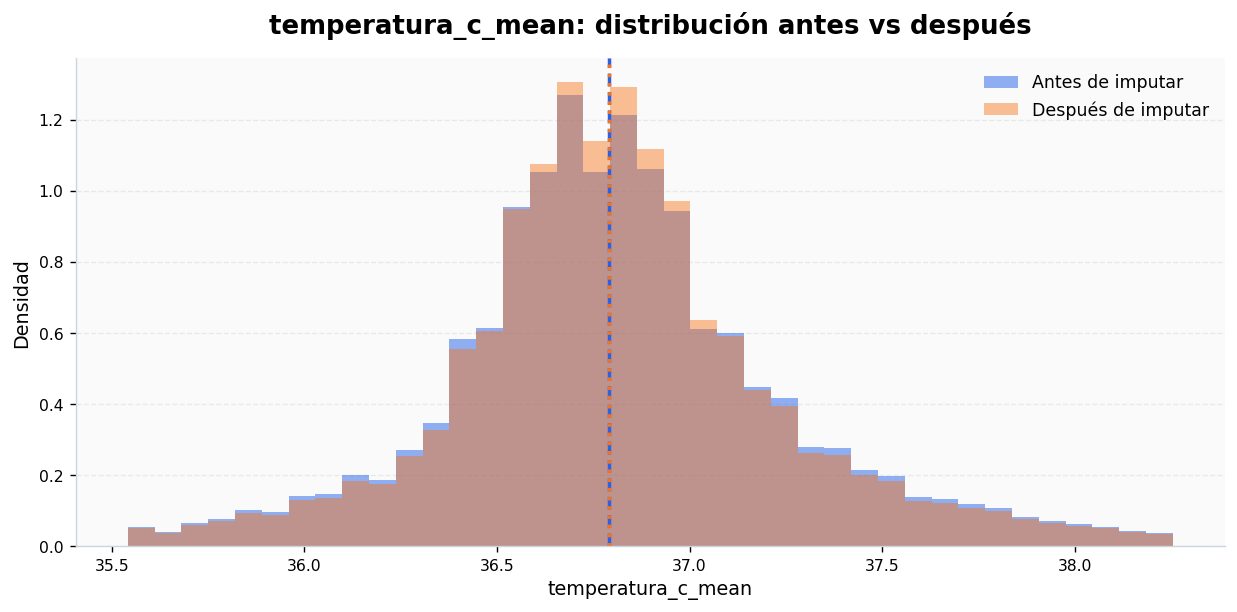

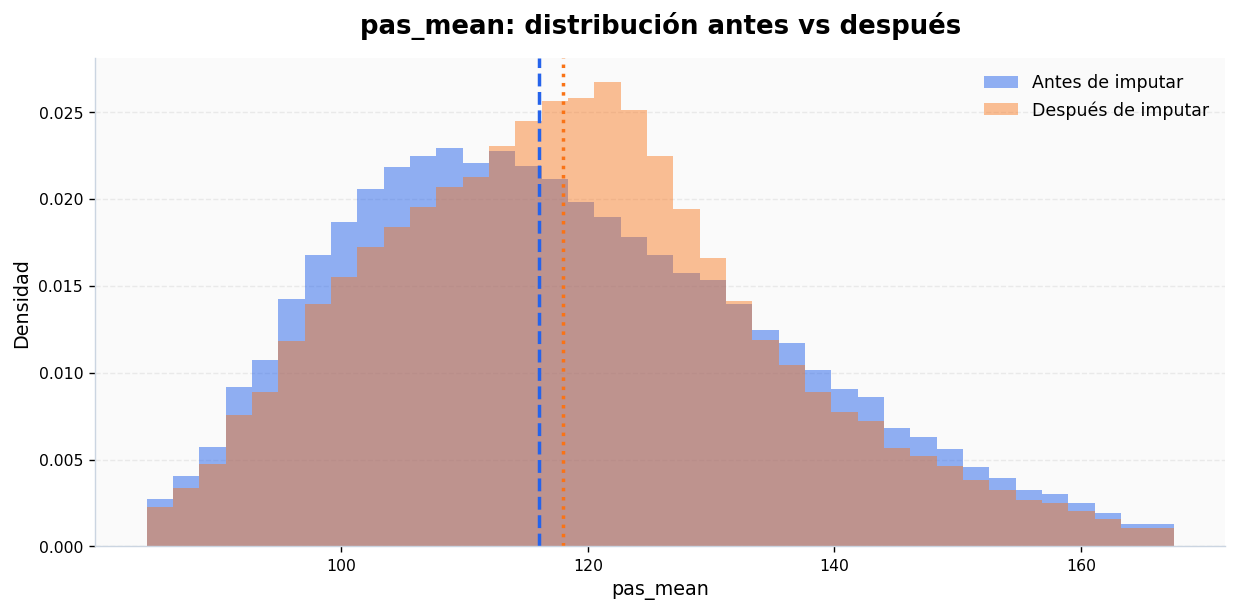

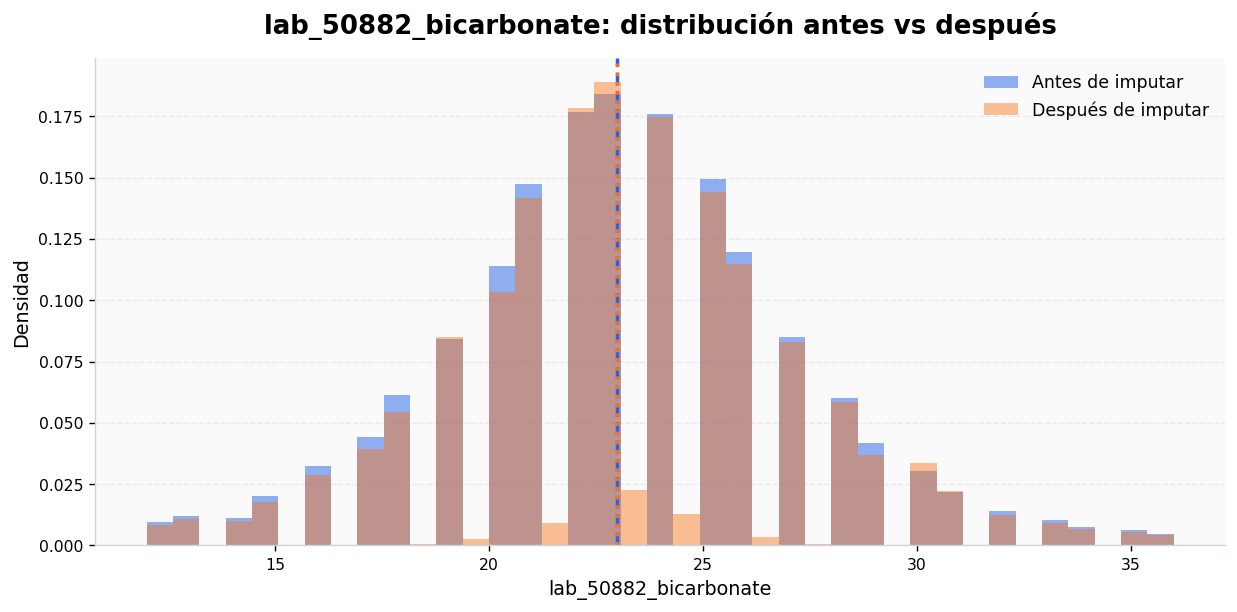

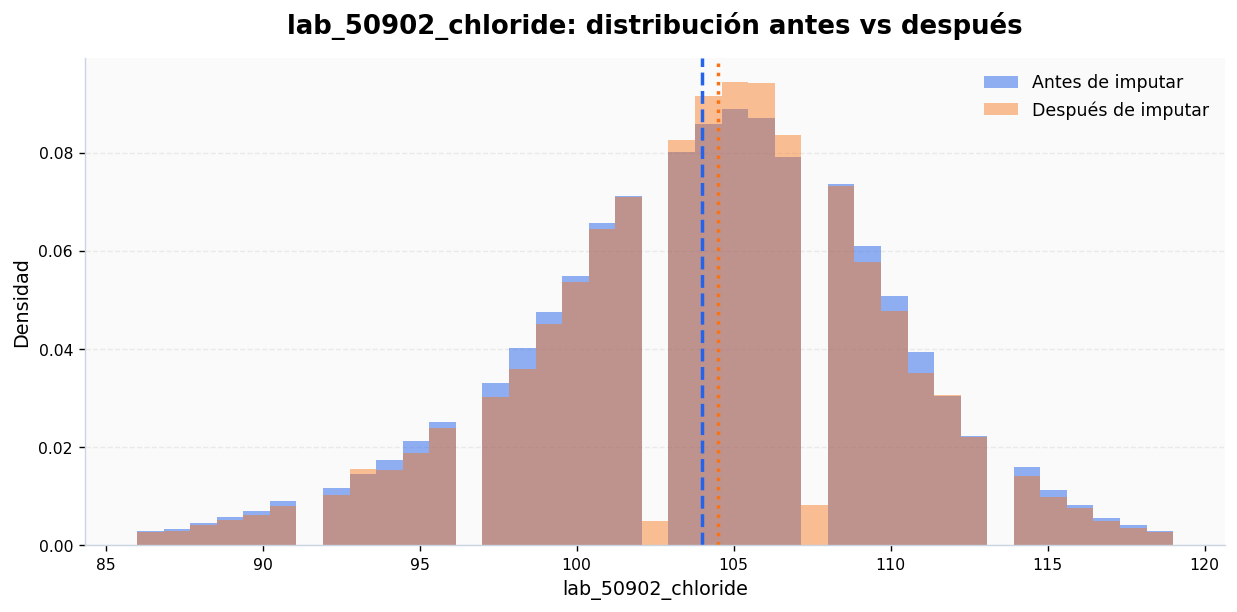

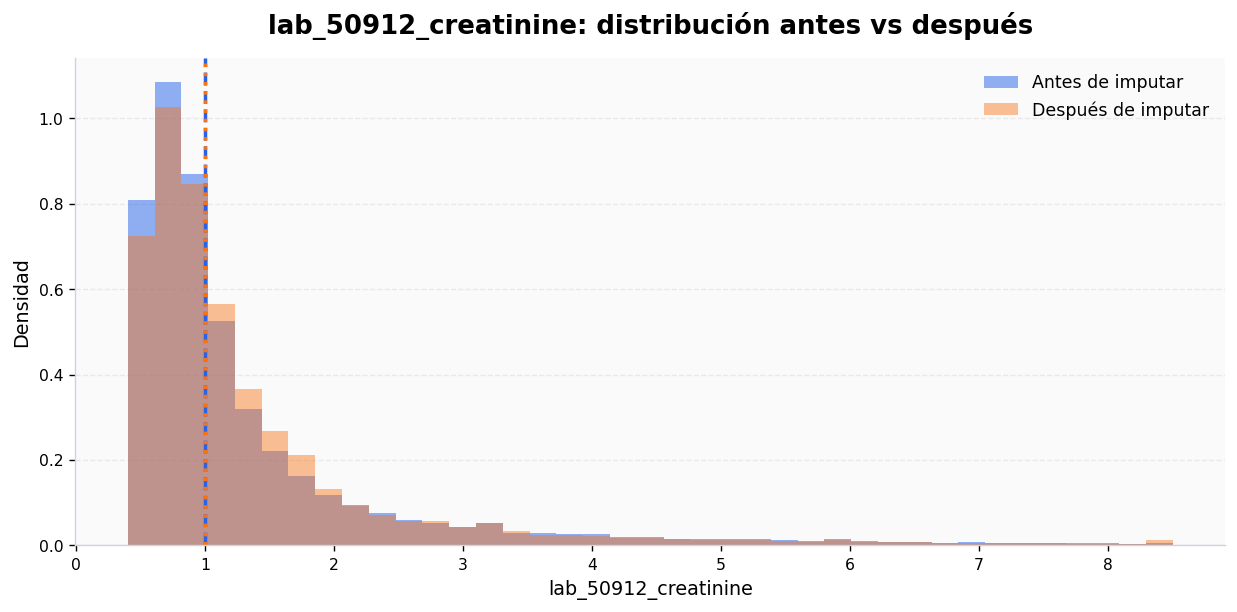

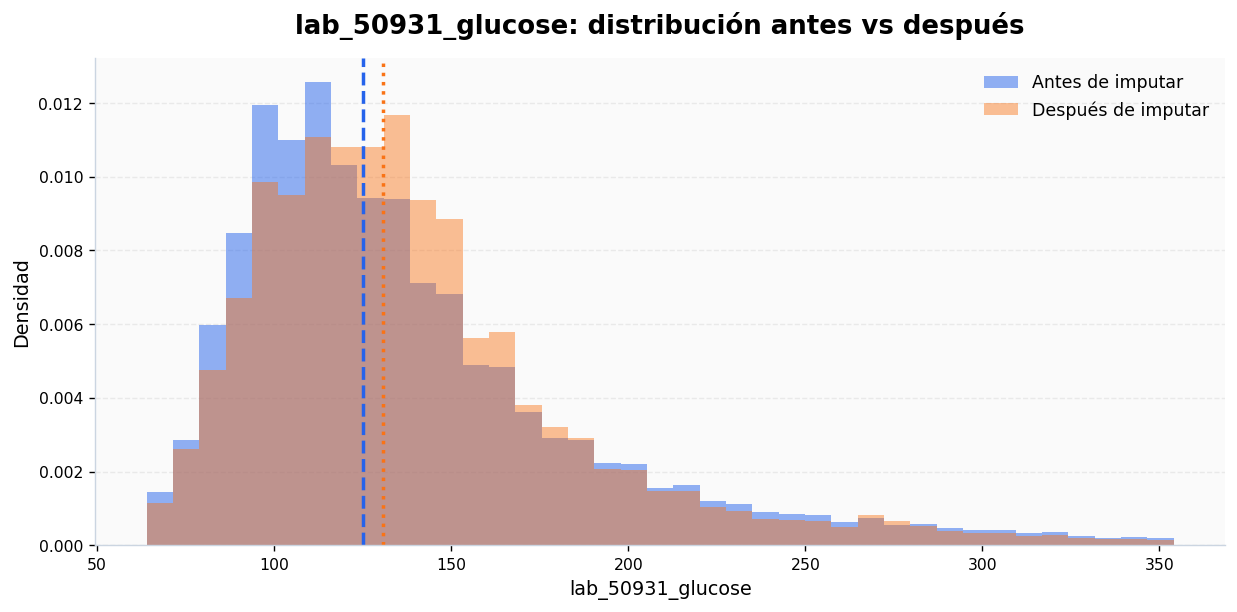

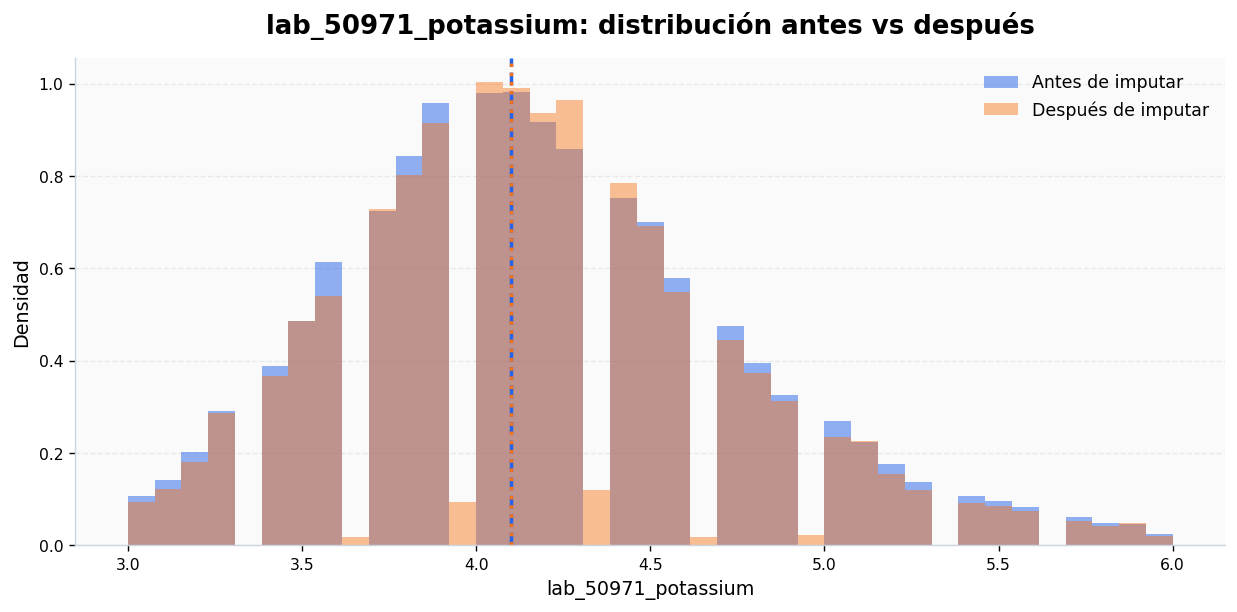

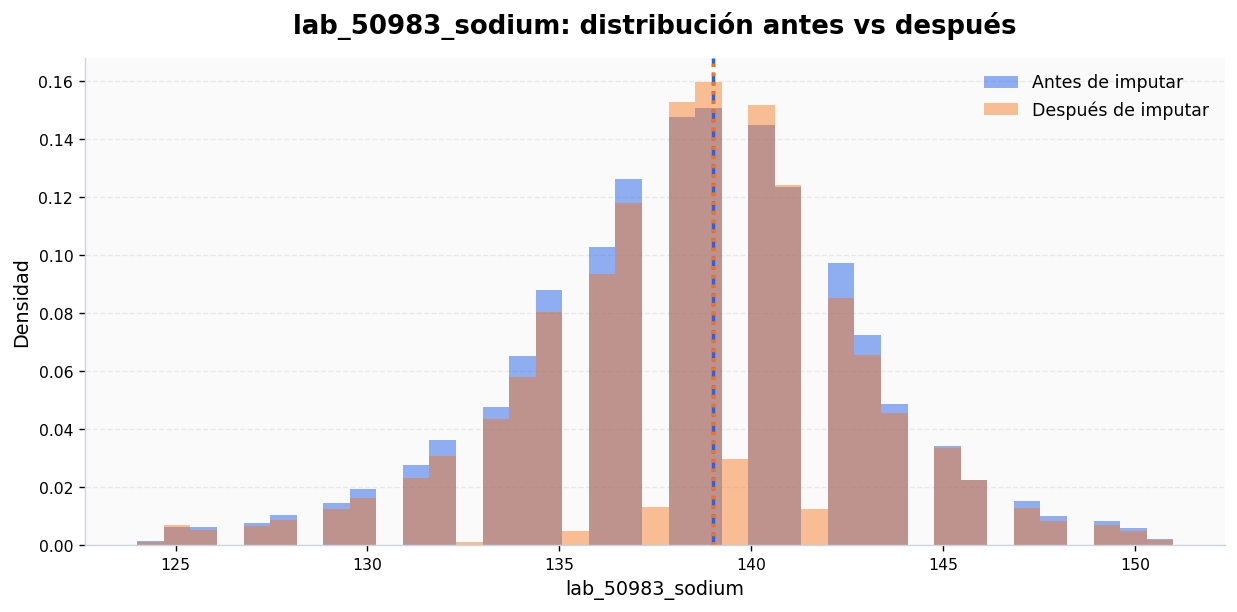

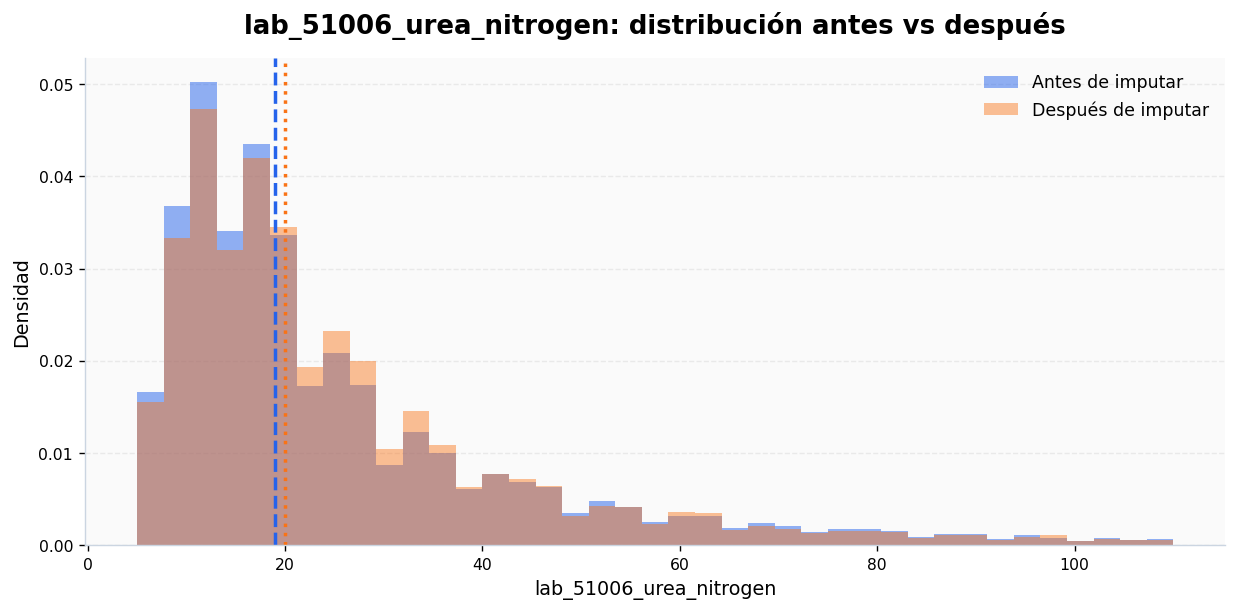

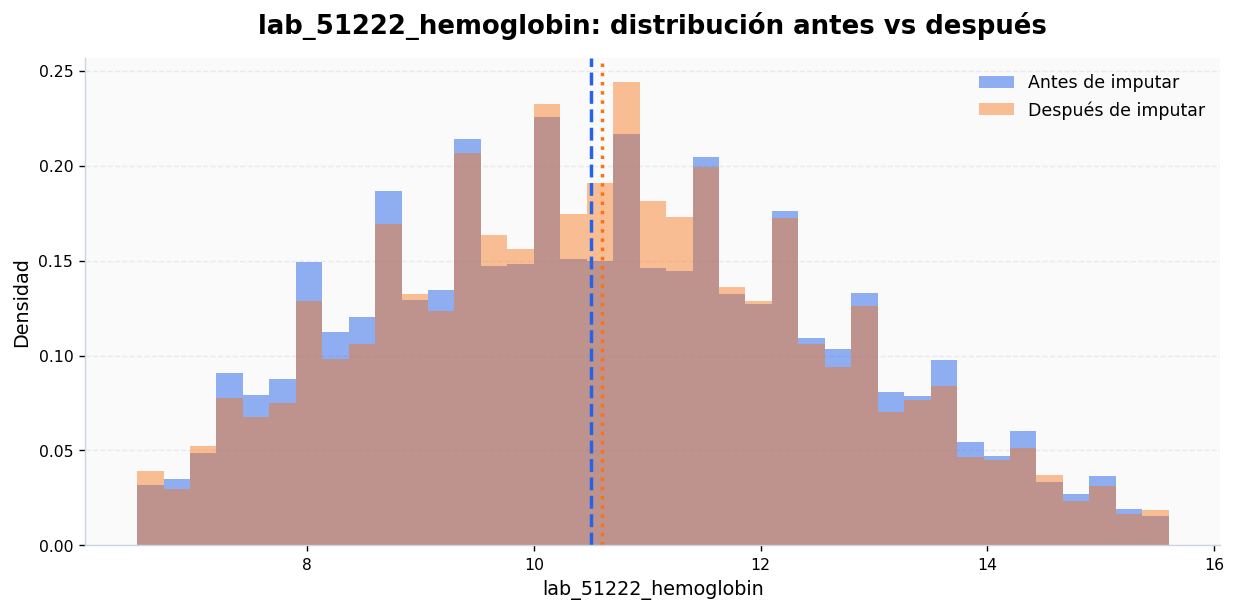

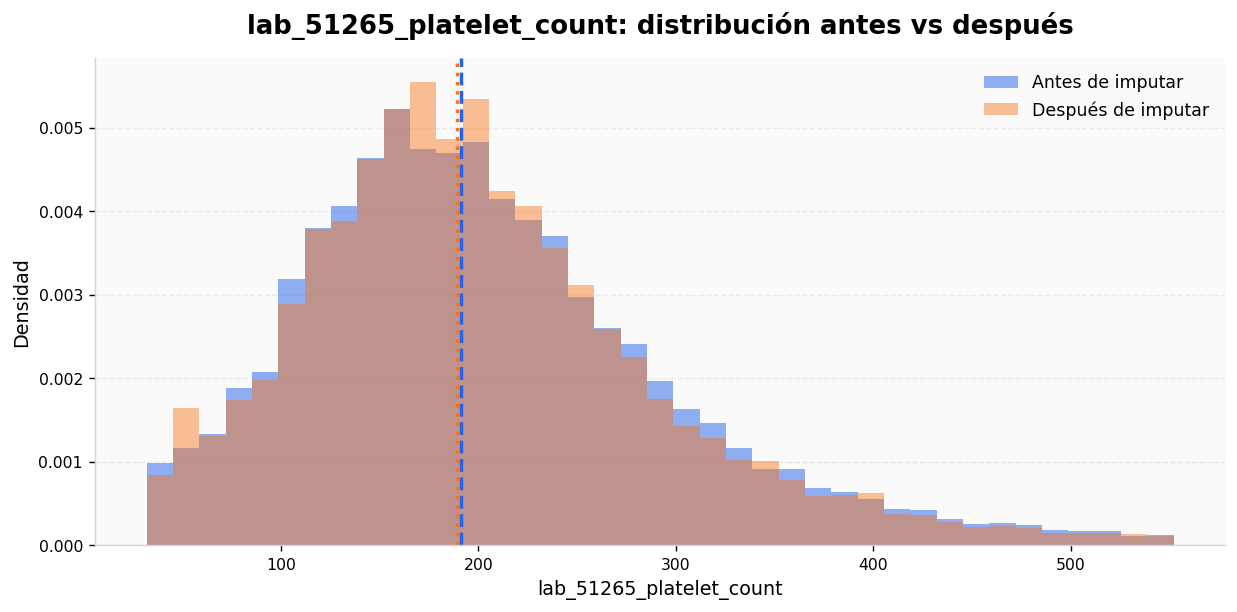

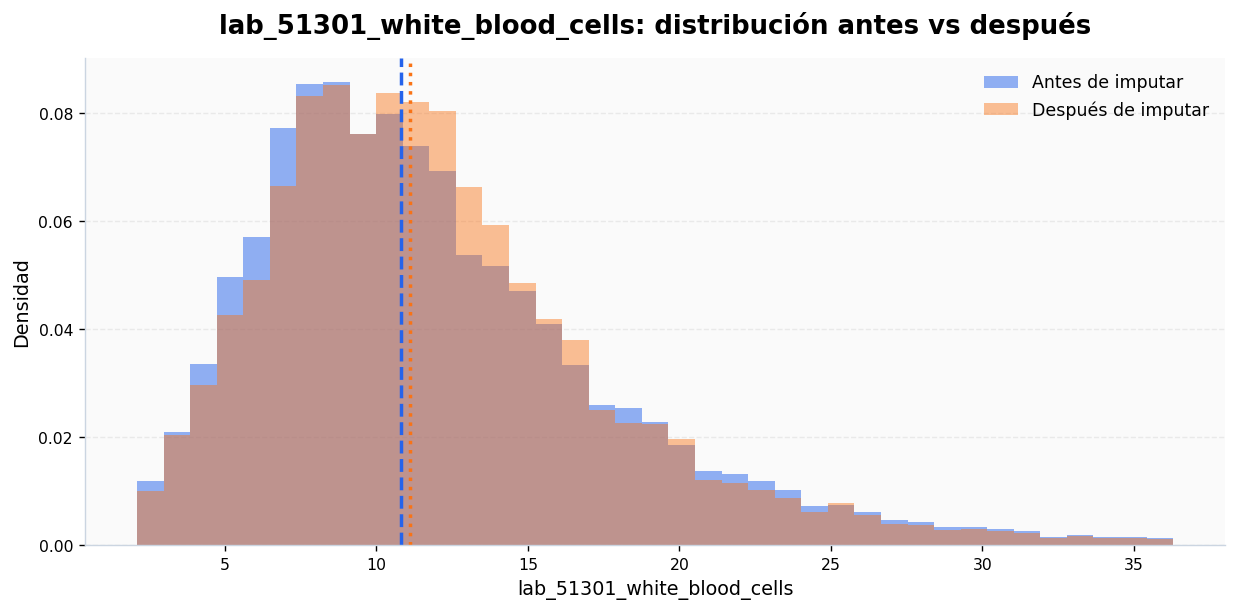

In [51]:
for i, c in enumerate(numeric_features):
    antes = train[c].dropna()
    despues = train_imputado[c].dropna()

    limites = np.nanpercentile(despues, [1, 99])
    if limites[0] == limites[1]:
        limites = [despues.min(), despues.max()]

    bins = np.linspace(limites[0], limites[1], 40)

    fig, ax = plt.subplots(figsize=(10,5))
    ax.hist(antes[(antes>=limites[0]) & (antes<=limites[1])],
            bins=bins, density=True, alpha=.50,
            color=AZUL, label="Antes de imputar")
    ax.hist(despues[(despues>=limites[0]) & (despues<=limites[1])],
            bins=bins, density=True, alpha=.45,
            color=NARANJA, label="Después de imputar")

    ax.axvline(antes.median(), color=AZUL, linestyle="--", linewidth=2)
    ax.axvline(despues.median(), color=NARANJA, linestyle=":", linewidth=2)
    ax.legend()
    formato_ax(
        ax,
        f"{c}: distribución antes vs después",
        c,
        "Densidad"
    )
    plt.tight_layout()
    plt.show()


## 22.4 Estadísticos descriptivos después de la limpieza e imputación


In [52]:
num_post = [
    c for c in train_imputado.select_dtypes(include=np.number).columns
    if c not in IDS
]

desc_post = train_imputado[num_post].describe(
    percentiles=[.01,.05,.10,.25,.50,.75,.90,.95,.99]
).T

desc_post["IQR"] = desc_post["75%"] - desc_post["25%"]
desc_post["asimetria"] = train_imputado[num_post].skew()
desc_post["curtosis"] = train_imputado[num_post].kurt()

display(desc_post)


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max,IQR,asimetria,curtosis
edad_ingreso,"72,469.000",64.747,16.688,18.000,22.000,32.000,41.000,55.000,66.000,77.000,85.000,89.000,92.000,102.000,22.000,-0.544,-0.162
fc_mean,"72,469.000",85.158,16.923,28.273,51.388,60.364,64.786,73.267,83.308,95.846,108.092,115.500,129.500,176.733,22.579,0.471,0.238
fr_mean,"72,469.000",19.045,4.139,3.000,11.738,13.556,14.500,16.154,18.364,21.250,24.615,26.917,31.471,46.167,5.096,0.931,1.460
spo2_mean,"72,469.000",96.984,2.375,34.429,90.750,93.222,94.200,95.667,97.250,98.750,99.636,99.909,100.000,100.000,3.083,-3.211,43.107
temperatura_c_mean,"72,469.000",36.810,0.545,25.176,35.542,36.056,36.319,36.574,36.792,37.028,37.375,37.667,38.254,40.750,0.454,-3.113,59.288
pas_mean,"72,469.000",118.835,17.324,37.000,84.231,93.077,97.768,106.800,118.024,128.538,141.167,149.917,167.500,231.556,21.738,0.521,0.828
lab_50882_bicarbonate,"72,469.000",23.157,4.388,2.000,12.000,16.000,18.000,21.000,23.000,25.000,28.000,30.000,36.000,50.000,4.000,0.283,2.413
lab_50902_chloride,"72,469.000",104.057,6.197,61.000,86.000,93.000,96.000,101.000,104.511,108.000,111.000,113.000,119.000,151.000,7.000,-0.343,2.085
lab_50912_creatinine,"72,469.000",1.456,1.510,0.100,0.400,0.500,0.600,0.700,1.000,1.500,2.700,4.100,8.500,24.700,0.800,4.406,28.140
lab_50931_glucose,"72,469.000",141.935,58.215,15.000,64.000,82.000,91.000,107.000,130.823,159.000,203.000,249.000,354.000,"1,340.000",52.000,3.453,31.006


## 22.5 Distribución del target después de la limpieza

El target no fue imputado ni recortado. Por ello su distribución debe permanecer esencialmente intacta; se vuelve a visualizar porque será determinante para decidir posteriormente si conviene modelar `LOS` original o una transformación como `log1p(LOS)`.


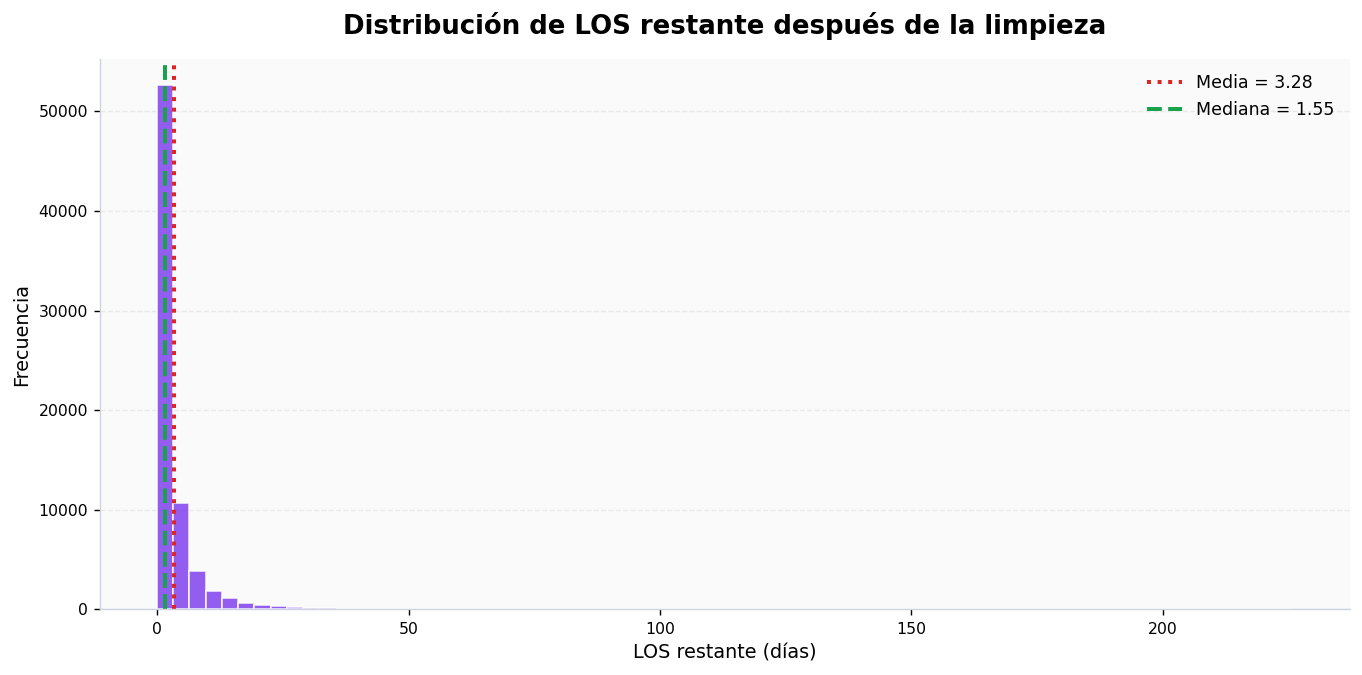

Asimetría: 6.39
Curtosis: 96.876


,los_restante_dias
count,"72,469.000"
mean,3.276
std,5.472
min,0.000
1%,0.054
5%,0.202
25%,0.670
50%,1.546
75%,3.492
90%,7.663


In [53]:
fig, ax = plt.subplots(figsize=(11,5.5))
target_train = train_imputado[TARGET].dropna()

ax.hist(target_train, bins=70, color=MORADO, alpha=.82, edgecolor="white")
ax.axvline(target_train.mean(), color=ROJO, linestyle=":", linewidth=2.3,
           label=f"Media = {target_train.mean():.2f}")
ax.axvline(target_train.median(), color=VERDE, linestyle="--", linewidth=2.3,
           label=f"Mediana = {target_train.median():.2f}")
ax.legend()

formato_ax(
    ax,
    "Distribución de LOS restante después de la limpieza",
    "LOS restante (días)",
    "Frecuencia"
)
plt.tight_layout()
plt.show()

print("Asimetría:", round(target_train.skew(), 3))
print("Curtosis:", round(target_train.kurt(), 3))
display(target_train.describe(percentiles=[.01,.05,.25,.50,.75,.90,.95,.99]).to_frame())


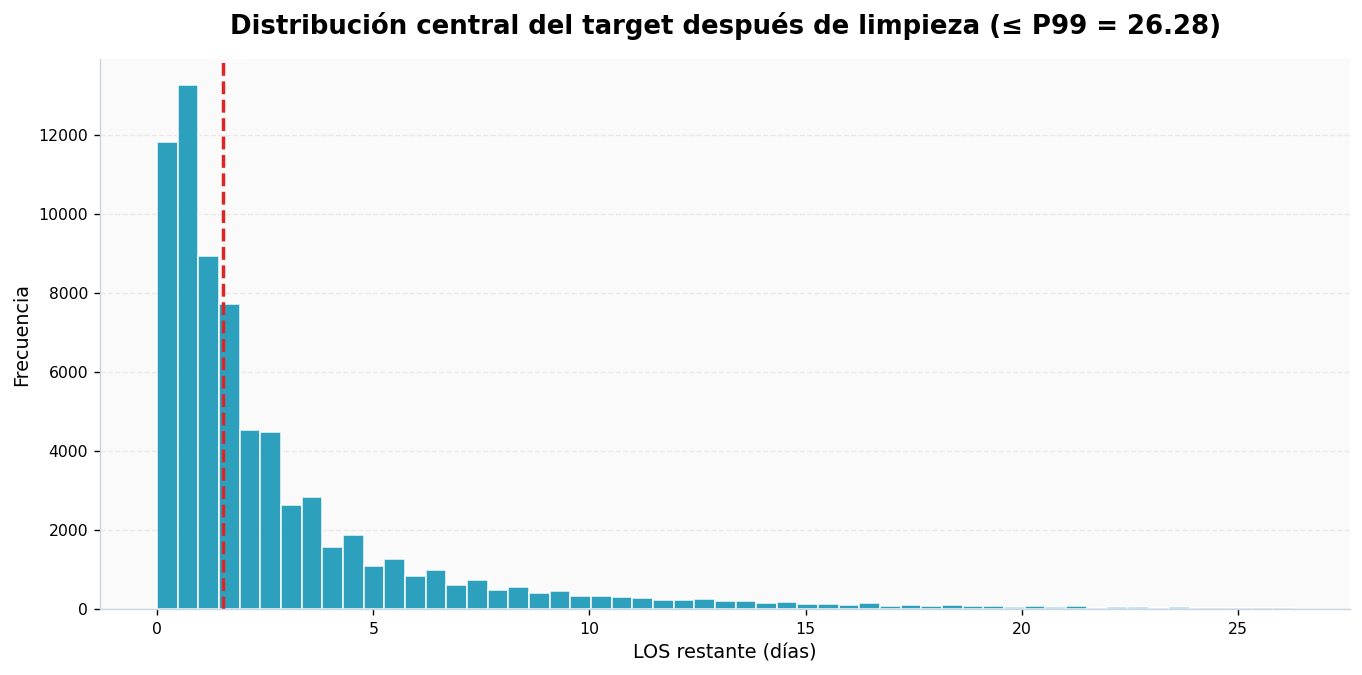

In [54]:
p99 = target_train.quantile(.99)

fig, ax = plt.subplots(figsize=(11,5.5))
central = target_train[target_train <= p99]
ax.hist(central, bins=55, color=TURQUESA, alpha=.85, edgecolor="white")
ax.axvline(central.median(), color=ROJO, linestyle="--", linewidth=2)

formato_ax(
    ax,
    f"Distribución central del target después de limpieza (≤ P99 = {p99:.2f})",
    "LOS restante (días)",
    "Frecuencia"
)
plt.tight_layout()
plt.show()


## 22.6 Boxplots de predictores después de la limpieza

Los valores extremos se mantienen visibles. El objetivo es comprobar que ya no existan magnitudes incompatibles como las observadas antes de la limpieza.


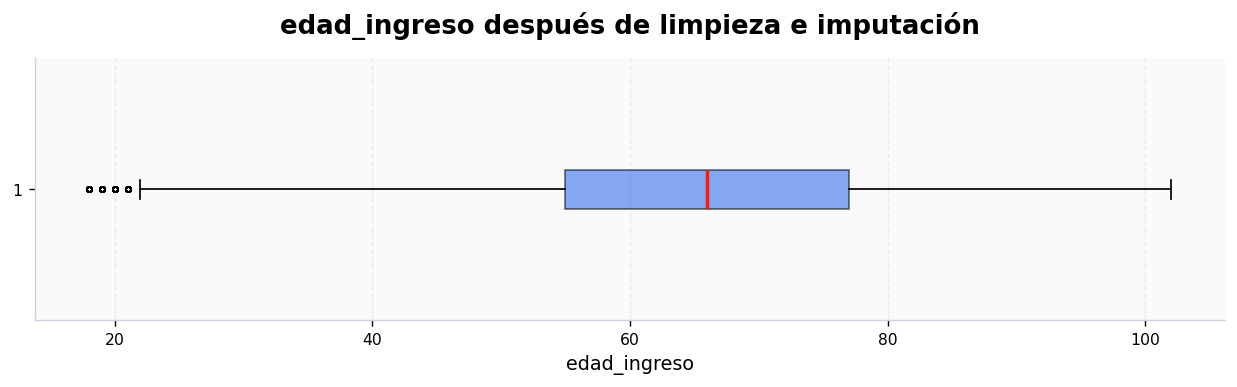

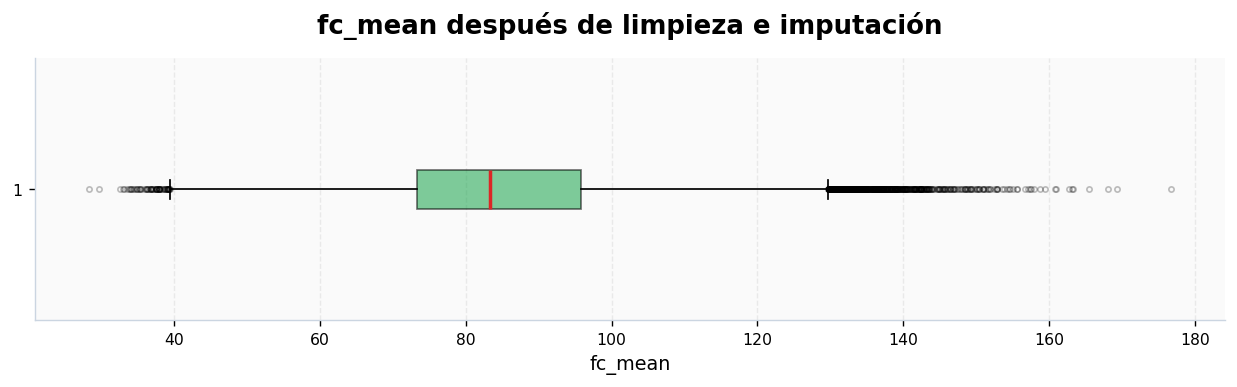

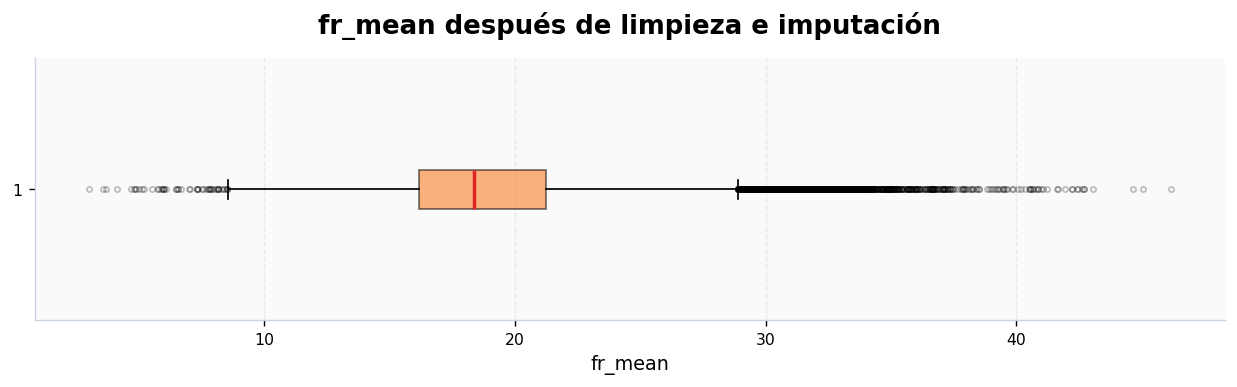

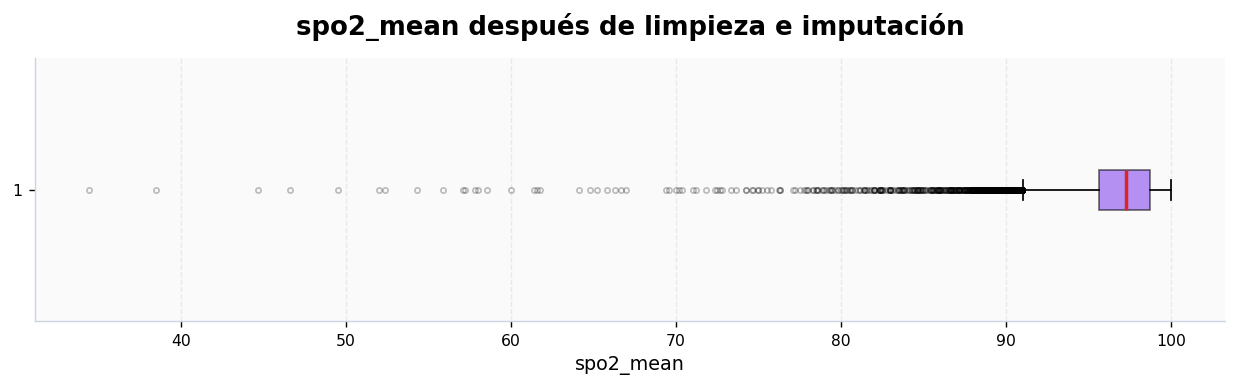

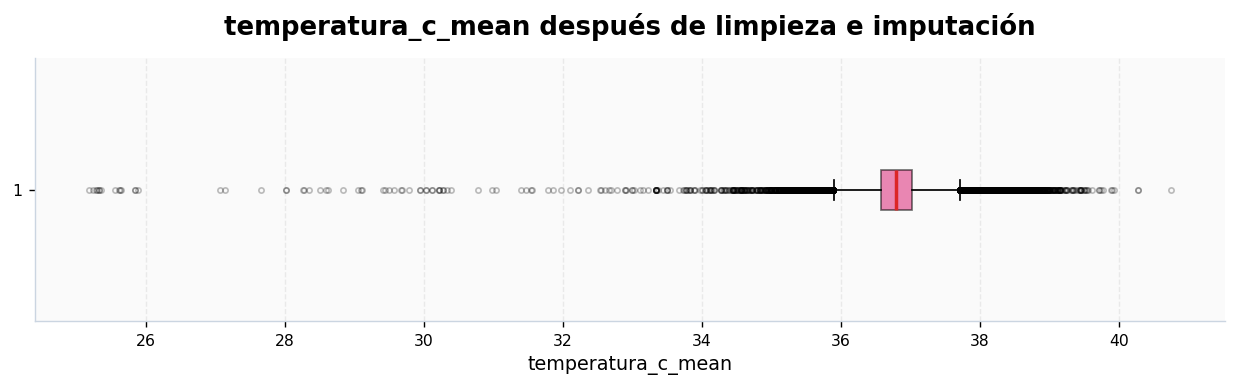

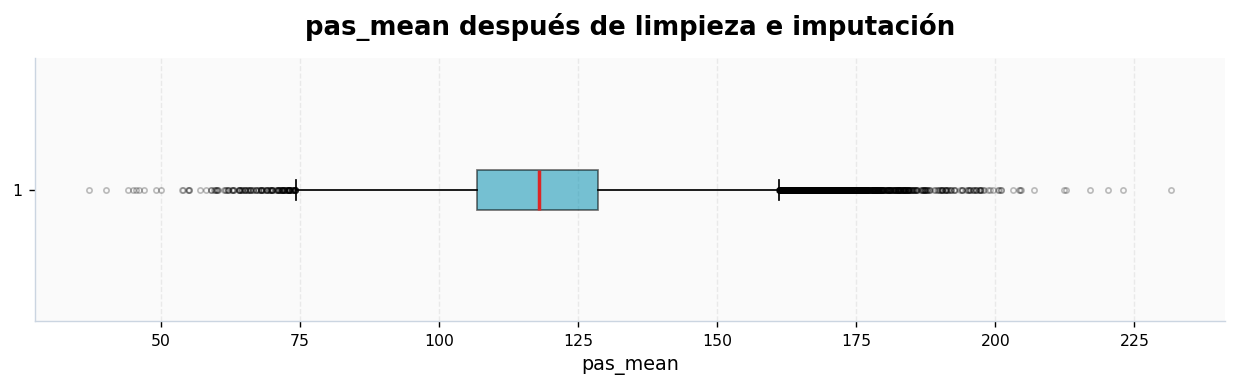

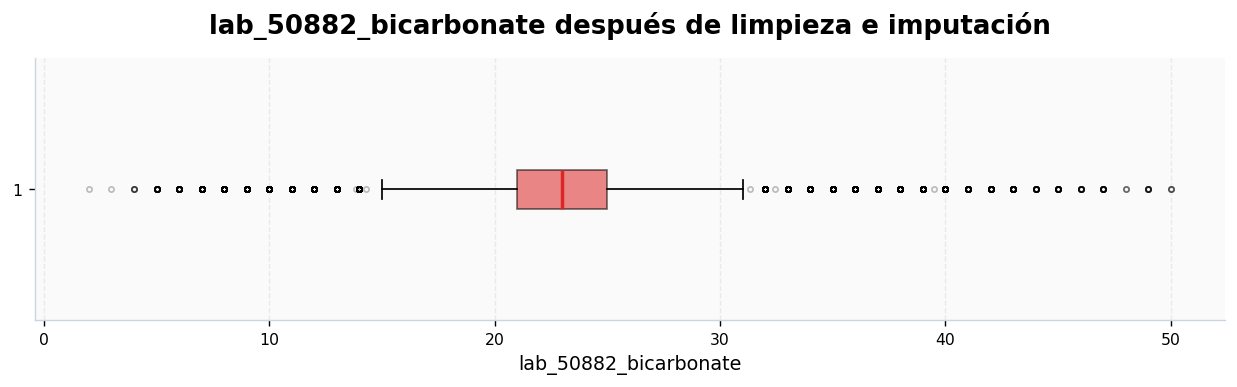

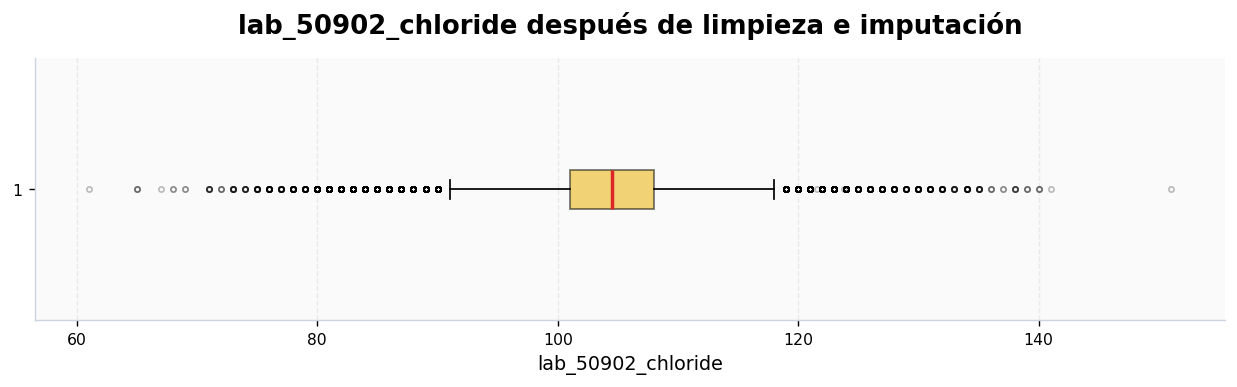

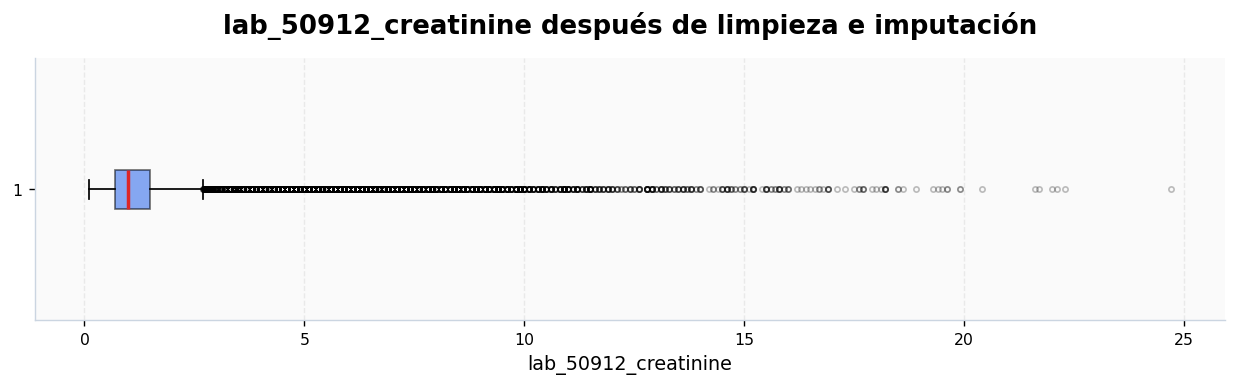

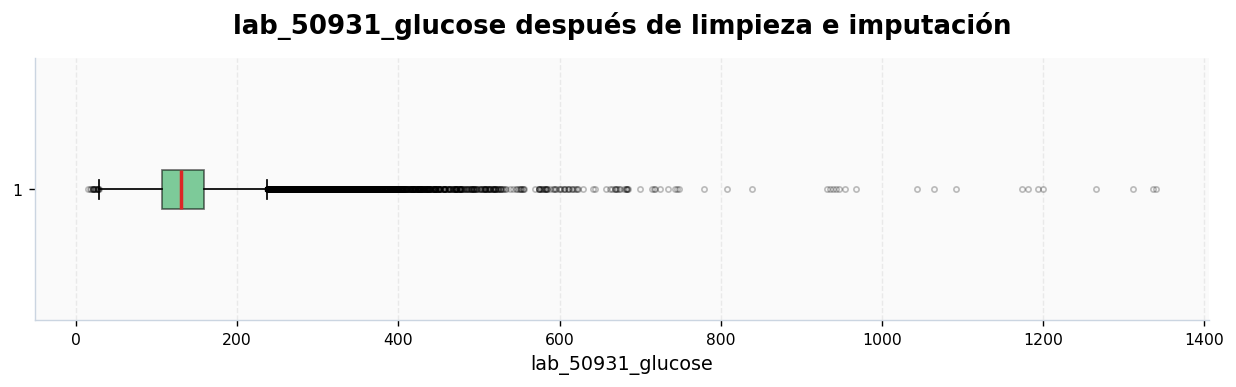

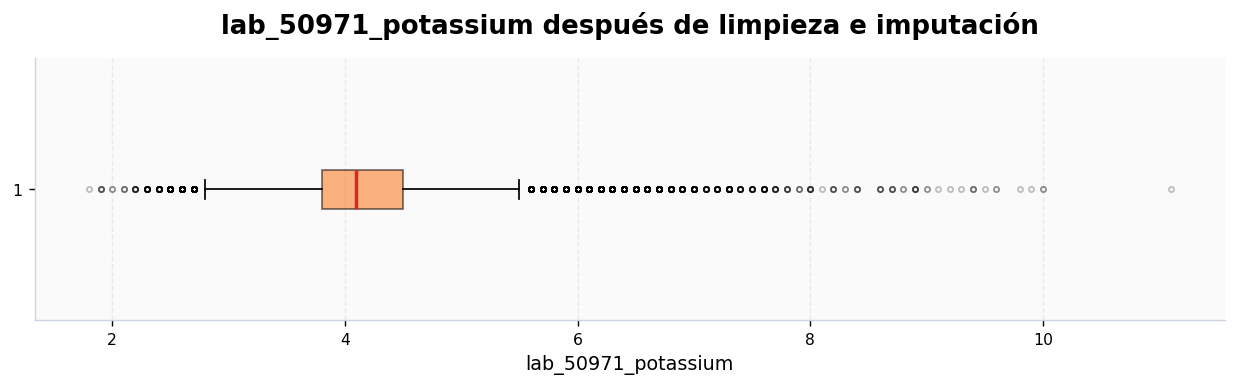

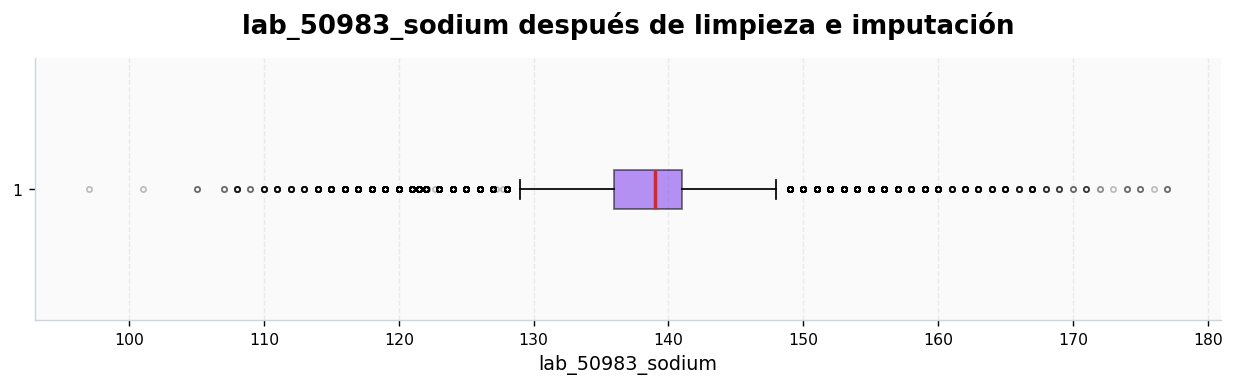

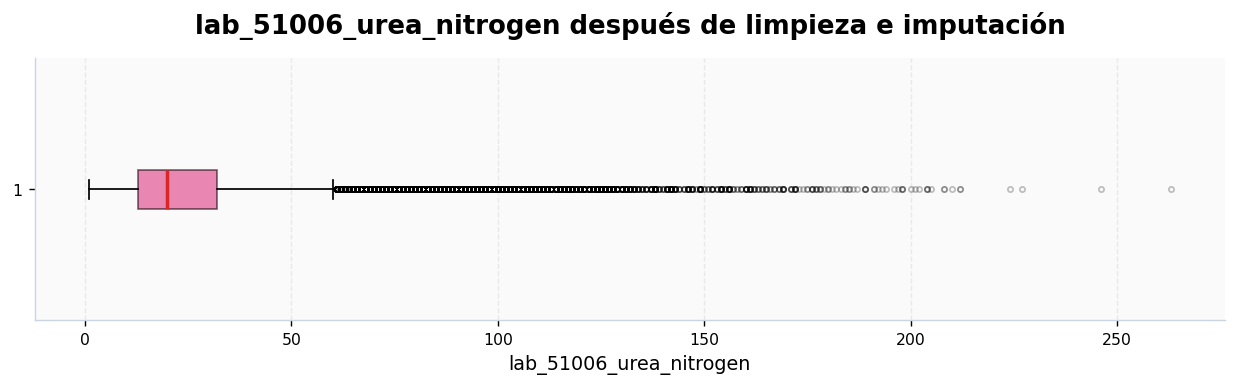

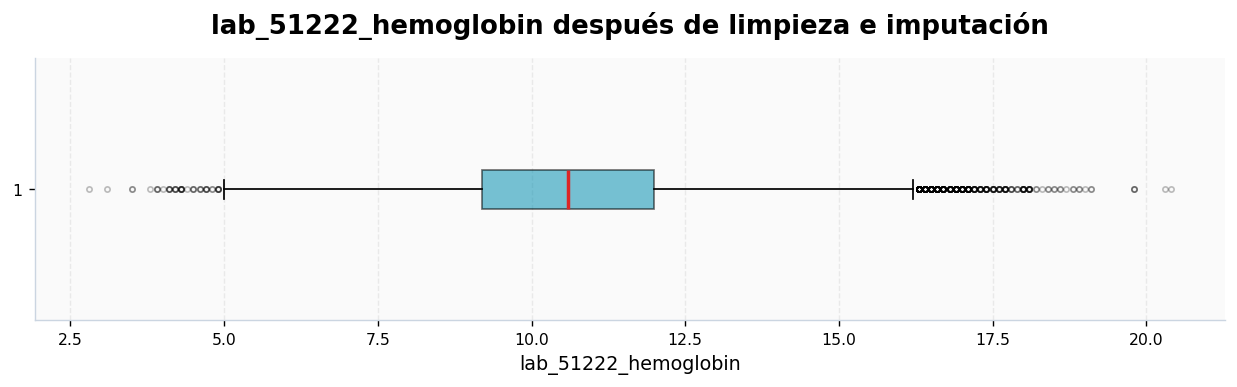

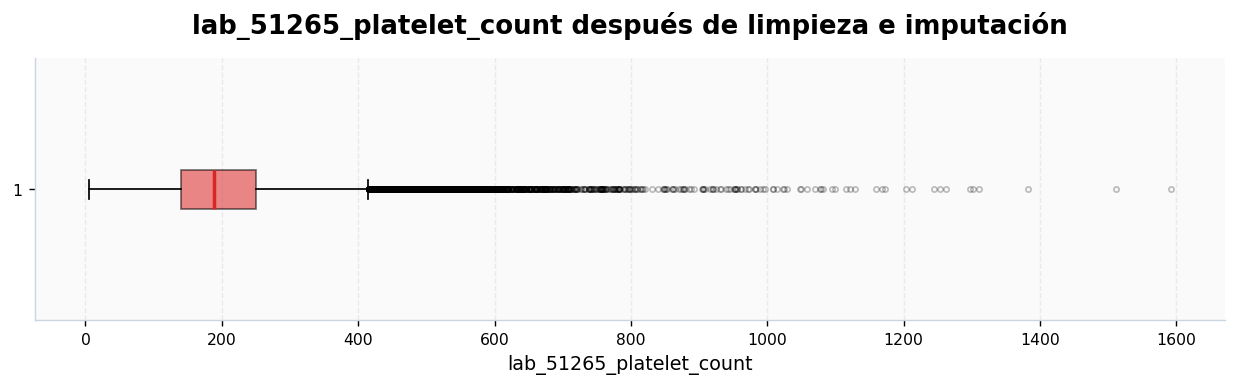

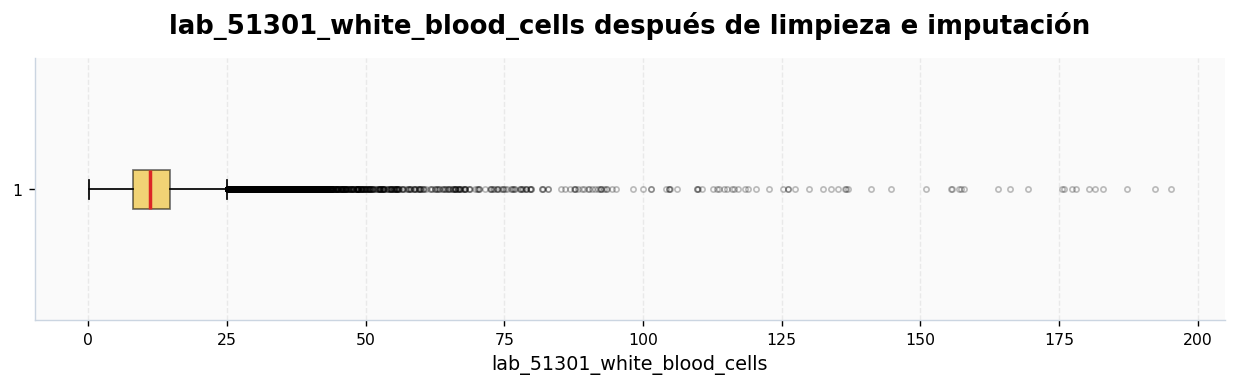

In [55]:
for i, c in enumerate(numeric_features):
    fig, ax = plt.subplots(figsize=(10,3.2))
    bp = ax.boxplot(
        train_imputado[c].dropna(),
        vert=False,
        patch_artist=True,
        showfliers=True,
        flierprops={"marker":"o", "markersize":3, "alpha":.25}
    )
    bp["boxes"][0].set_facecolor(PALETA[i % len(PALETA)])
    bp["boxes"][0].set_alpha(.55)
    bp["medians"][0].set_color(ROJO)
    bp["medians"][0].set_linewidth(2)

    formato_ax(
        ax,
        f"{c} después de limpieza e imputación",
        c,
        "",
        eje_grid="x"
    )
    plt.tight_layout()
    plt.show()


## 22.7 Outliers estadísticos después de la limpieza

Se recalcula IQR únicamente para describir la distribución final. Estos valores **siguen sin eliminarse automáticamente**.


,variable,limite_inferior_IQR,limite_superior_IQR,n_outliers,pct_outliers
8,lab_50912_creatinine,-0.500,2.700,6964,9.610
4,temperatura_c_mean,35.894,37.708,5541,7.646
12,lab_51006_urea_nitrogen,-15.500,60.500,5425,7.486
6,lab_50882_bicarbonate,15.000,31.000,4300,5.934
9,lab_50931_glucose,29.000,237.000,4244,5.856
11,lab_50983_sodium,128.500,148.500,3479,4.801
15,lab_51301_white_blood_cells,-2.200,25.000,3050,4.209
14,lab_51265_platelet_count,-25.000,415.000,2693,3.716
7,lab_50902_chloride,90.500,118.500,2586,3.568
10,lab_50971_potassium,2.750,5.550,2241,3.092


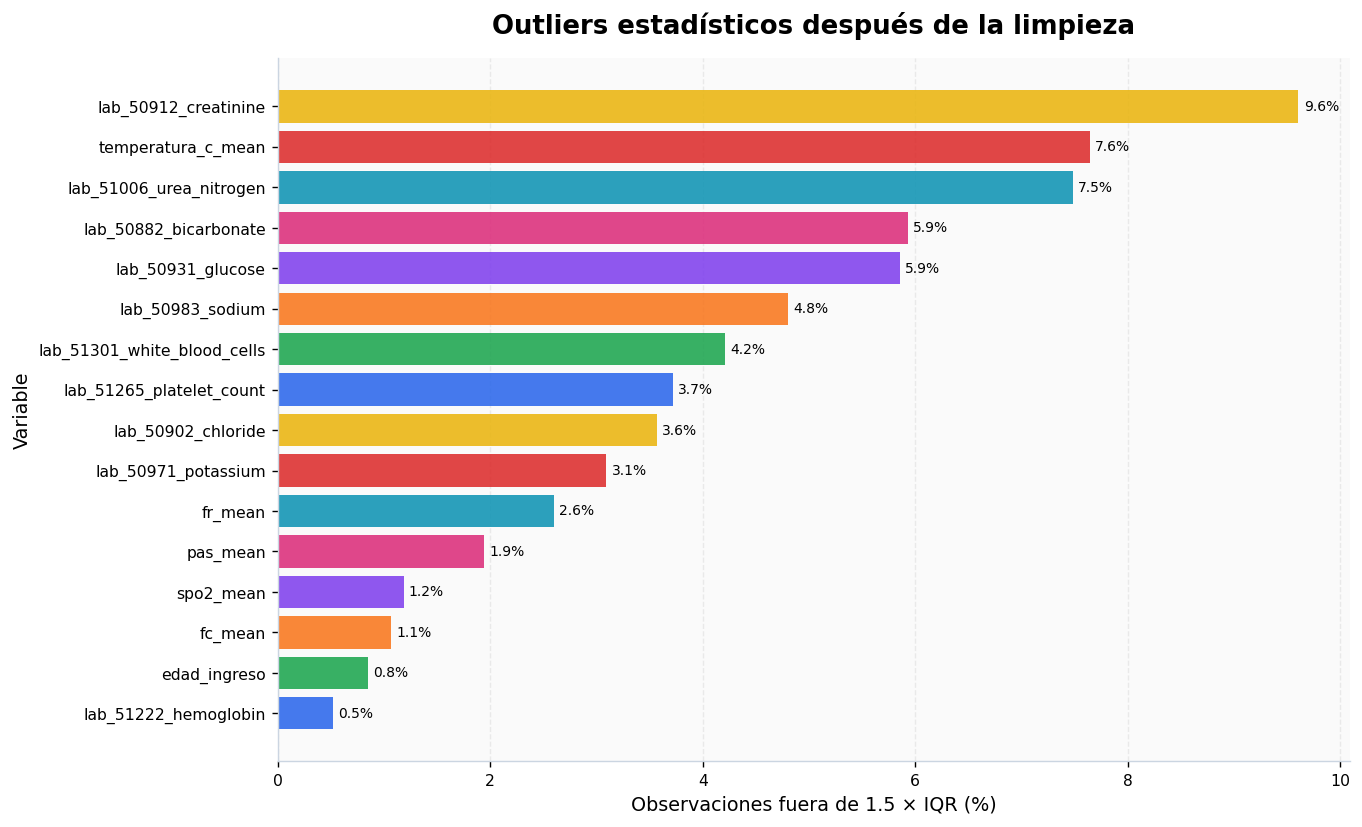

In [56]:
out_post = []

for c in numeric_features:
    s = train_imputado[c].dropna()
    q1, q3 = s.quantile([.25,.75])
    iqr = q3-q1
    li, ls = q1-1.5*iqr, q3+1.5*iqr
    n = ((s<li)|(s>ls)).sum()

    out_post.append({
        "variable":c,
        "limite_inferior_IQR":li,
        "limite_superior_IQR":ls,
        "n_outliers":int(n),
        "pct_outliers":n/len(s)*100
    })

outliers_post = pd.DataFrame(out_post).sort_values("pct_outliers", ascending=False)
display(outliers_post)

fig, ax = plt.subplots(figsize=(11, max(6,len(outliers_post)*.42)))
tmp = outliers_post.sort_values("pct_outliers")
colores = [PALETA[i % len(PALETA)] for i in range(len(tmp))]
bars = ax.barh(tmp["variable"], tmp["pct_outliers"], color=colores, alpha=.85)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)

formato_ax(
    ax,
    "Outliers estadísticos después de la limpieza",
    "Observaciones fuera de 1.5 × IQR (%)",
    "Variable",
    eje_grid="x"
)
plt.tight_layout()
plt.show()


## 22.8 Correlación después de la limpieza e imputación

La matriz se recalcula únicamente con TRAIN imputado. Así evitamos utilizar TEST para tomar decisiones posteriores sobre multicolinealidad.


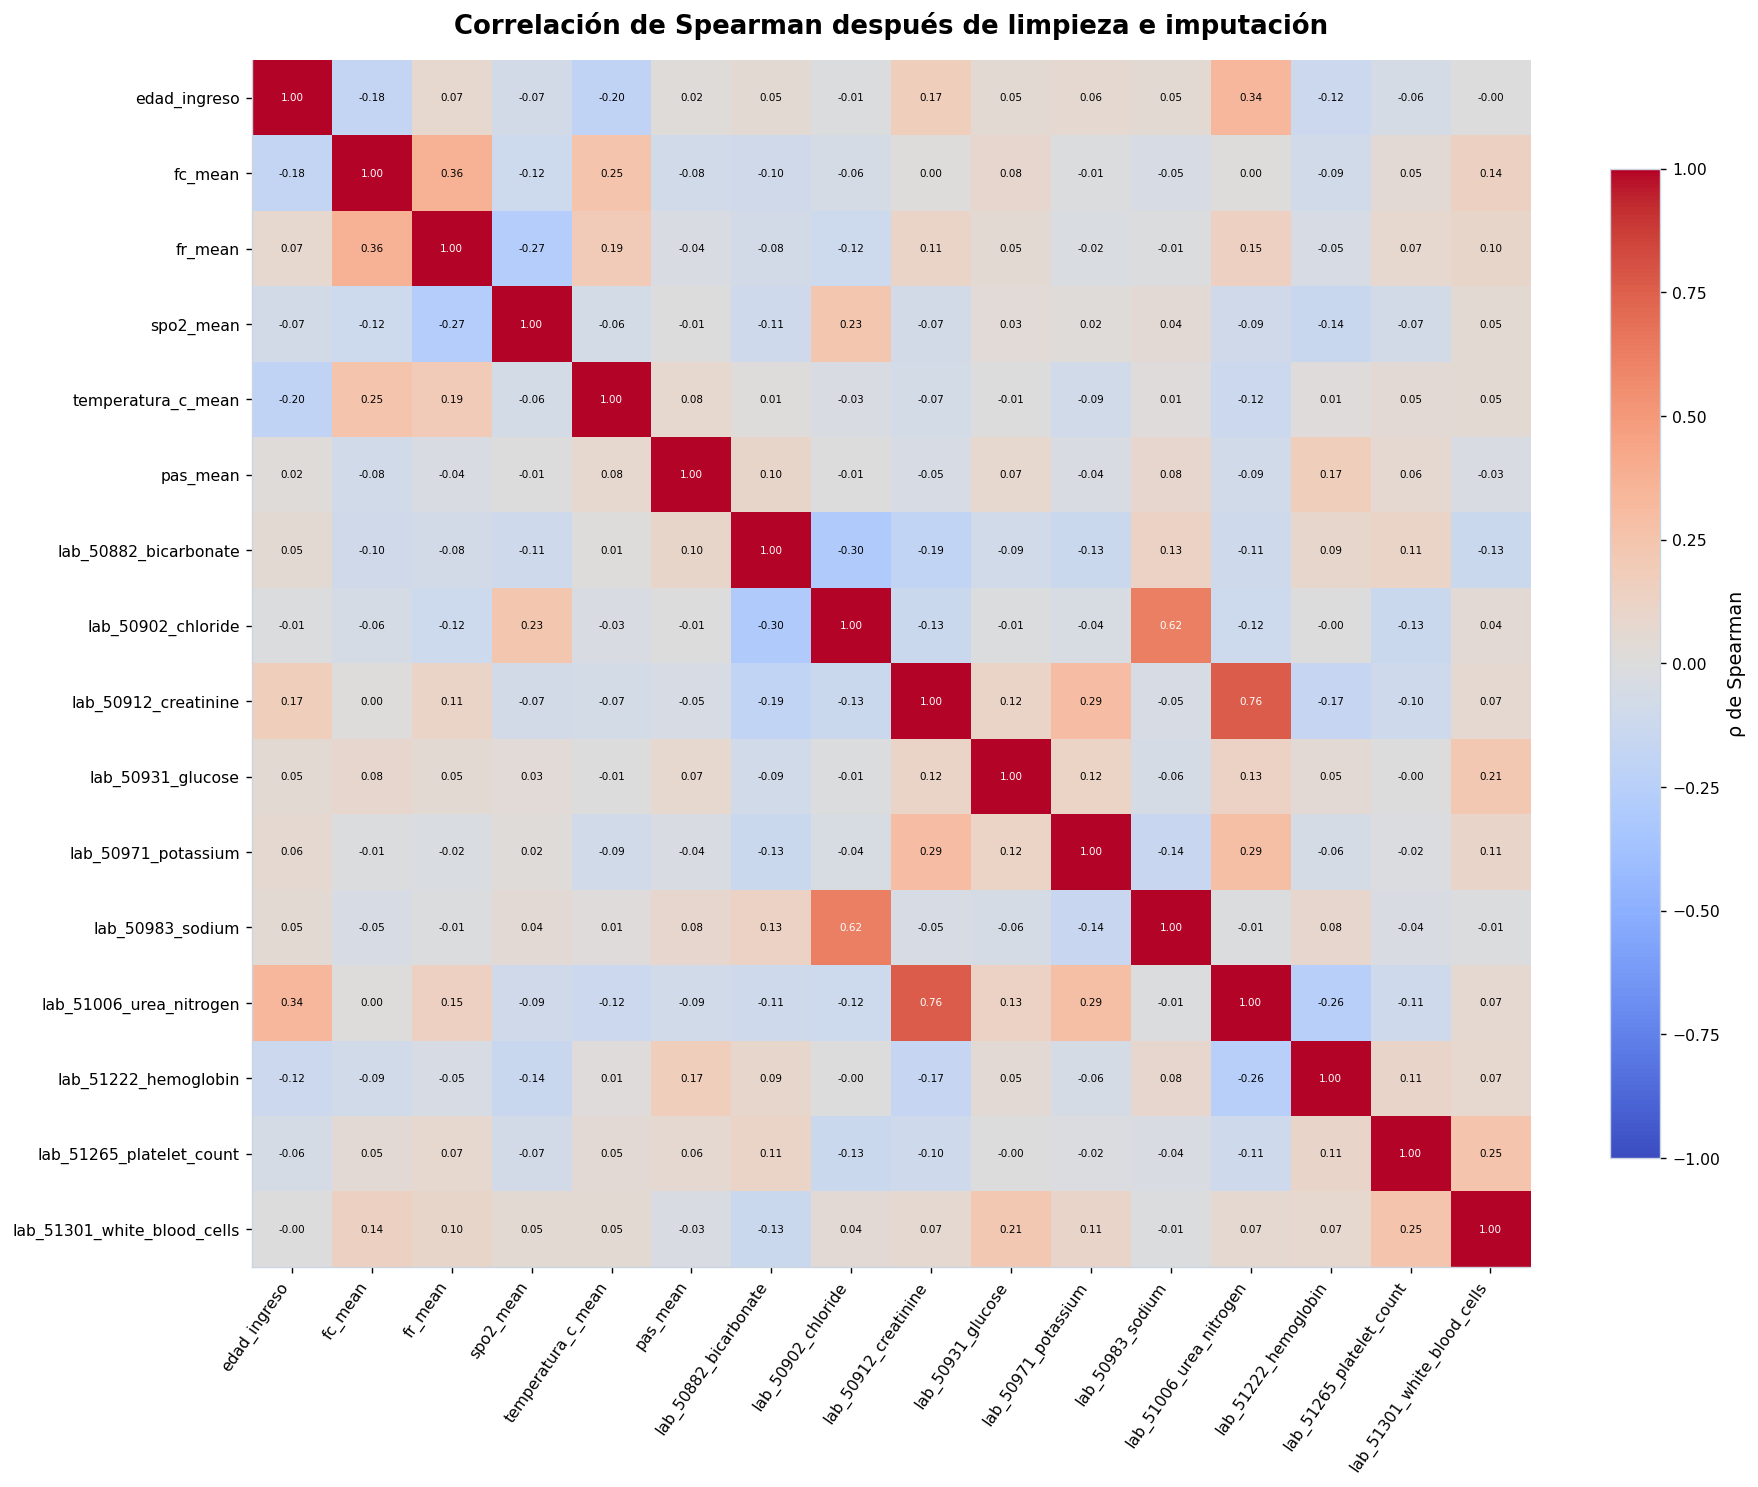

In [57]:
corr_post = train_imputado[numeric_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(15,12))
im = ax.imshow(corr_post, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
cbar = fig.colorbar(im, ax=ax, shrink=.82)
cbar.set_label("ρ de Spearman")

ax.set_xticks(range(len(corr_post.columns)))
ax.set_xticklabels(corr_post.columns, rotation=55, ha="right")
ax.set_yticks(range(len(corr_post.columns)))
ax.set_yticklabels(corr_post.columns)

for i in range(len(corr_post)):
    for j in range(len(corr_post)):
        val = corr_post.iloc[i,j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=6, color="white" if abs(val)>.55 else "black")

ax.set_title("Correlación de Spearman después de limpieza e imputación", pad=15)
plt.tight_layout()
plt.show()


In [58]:
upper_post = corr_post.abs().where(
    np.triu(np.ones(corr_post.shape), k=1).astype(bool)
)

pares_post = (
    upper_post.stack()
    .reset_index()
    .rename(columns={"level_0":"variable_1","level_1":"variable_2",0:"rho_abs"})
    .sort_values("rho_abs", ascending=False)
)

print("Pares con |rho| >= 0.80:")
display(pares_post[pares_post["rho_abs"] >= .80])


Pares con |rho| >= 0.80:


,variable_1,variable_2,rho_abs


## 22.9 Asociación predictor–target después de la limpieza

Se calcula Spearman usando únicamente TRAIN. La gráfica ordenada facilita identificar qué predictores presentan mayor asociación monotónica con la estancia restante.


,variable,rho_spearman,rho_abs,p_value
2,fr_mean,0.131,0.131,0.000
12,lab_51006_urea_nitrogen,0.120,0.120,0.000
15,lab_51301_white_blood_cells,0.110,0.110,0.000
1,fc_mean,0.102,0.102,0.000
4,temperatura_c_mean,0.101,0.101,0.000
8,lab_50912_creatinine,0.090,0.090,0.000
9,lab_50931_glucose,0.085,0.085,0.000
6,lab_50882_bicarbonate,-0.070,0.070,0.000
13,lab_51222_hemoglobin,-0.069,0.069,0.000
3,spo2_mean,0.063,0.063,0.000


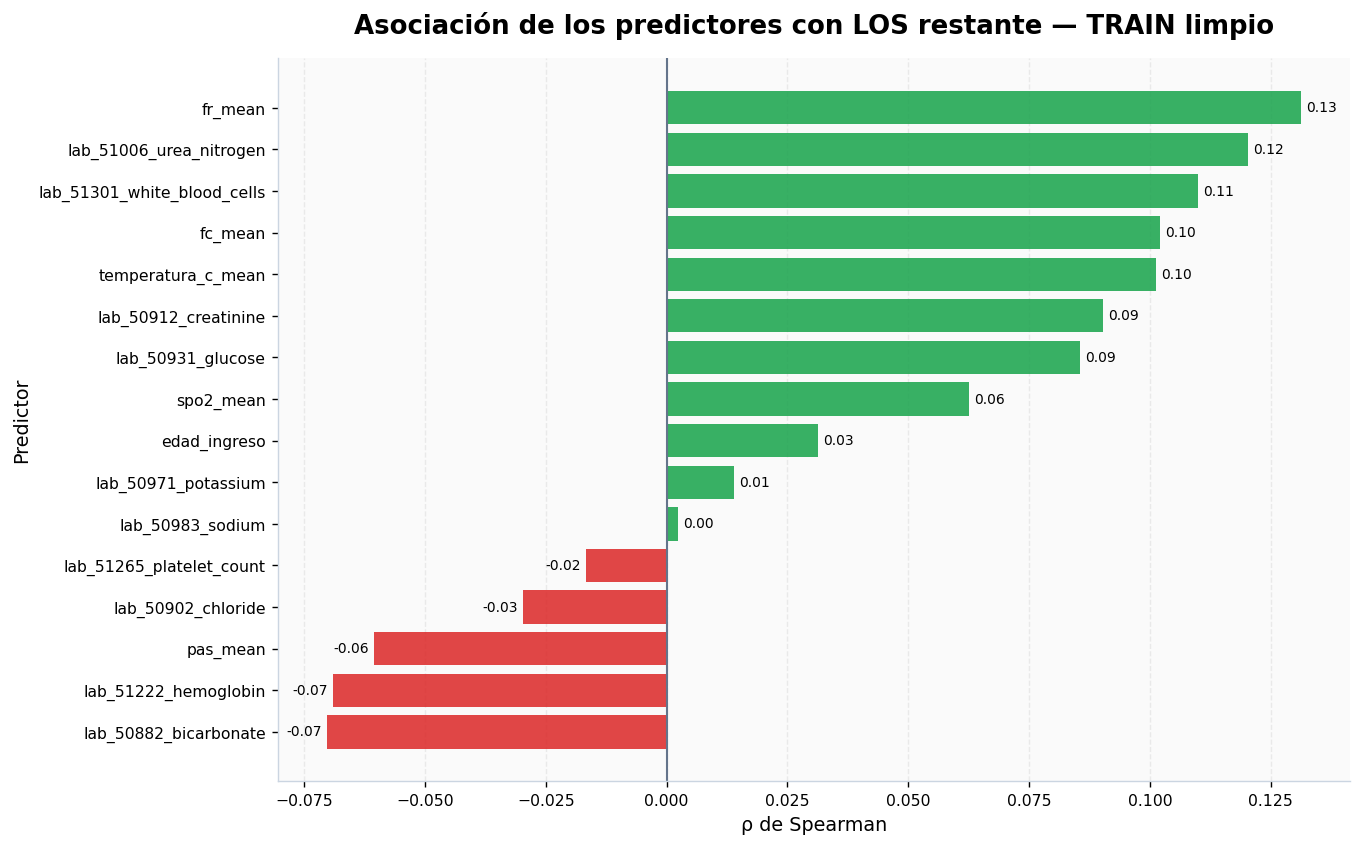

In [59]:
assoc_post = []

for c in numeric_features:
    pares = train_imputado[[c,TARGET]].dropna()
    rho, p = stats.spearmanr(pares[c], pares[TARGET])
    assoc_post.append({
        "variable":c,
        "rho_spearman":rho,
        "rho_abs":abs(rho),
        "p_value":p
    })

assoc_post = pd.DataFrame(assoc_post).sort_values("rho_abs", ascending=False)
display(assoc_post)

graf = assoc_post.sort_values("rho_spearman")
colores = [
    VERDE if v >= 0 else ROJO
    for v in graf["rho_spearman"]
]

fig, ax = plt.subplots(figsize=(11,max(6,len(graf)*.43)))
bars = ax.barh(graf["variable"], graf["rho_spearman"], color=colores, alpha=.85)
ax.axvline(0, color=GRIS, linewidth=1.2)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

formato_ax(
    ax,
    "Asociación de los predictores con LOS restante — TRAIN limpio",
    "ρ de Spearman",
    "Predictor",
    eje_grid="x"
)
plt.tight_layout()
plt.show()


## 22.10 Comparación visual de TRAIN y TEST

Esta revisión permite verificar que la partición por paciente no haya producido conjuntos con distribuciones marcadamente diferentes. **No se usa para ajustar parámetros**, solo como diagnóstico.


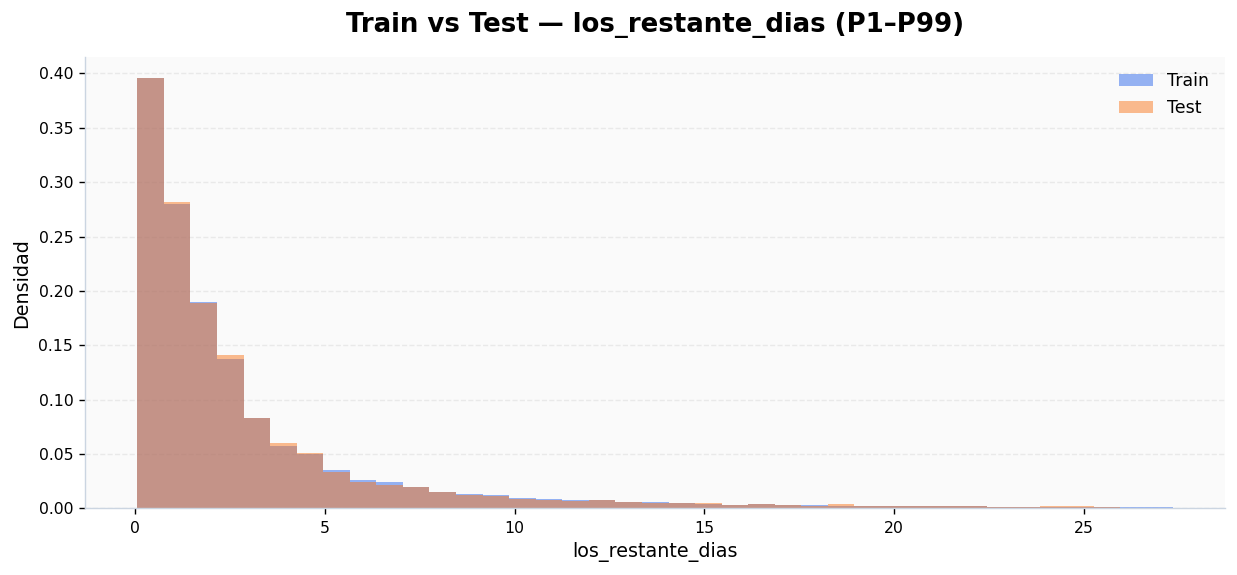

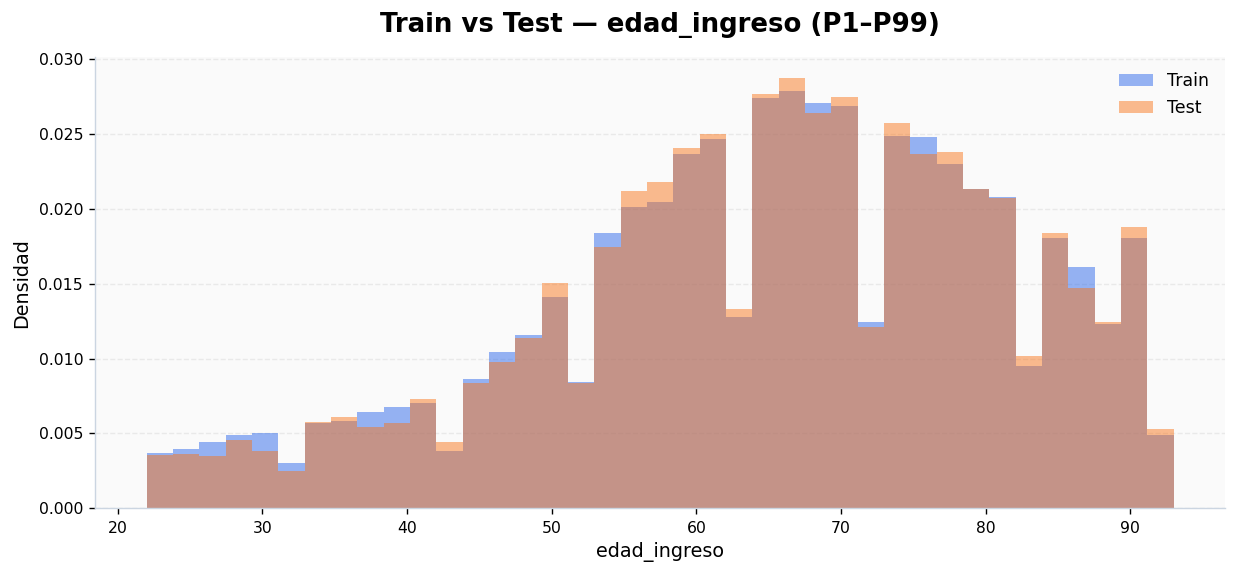

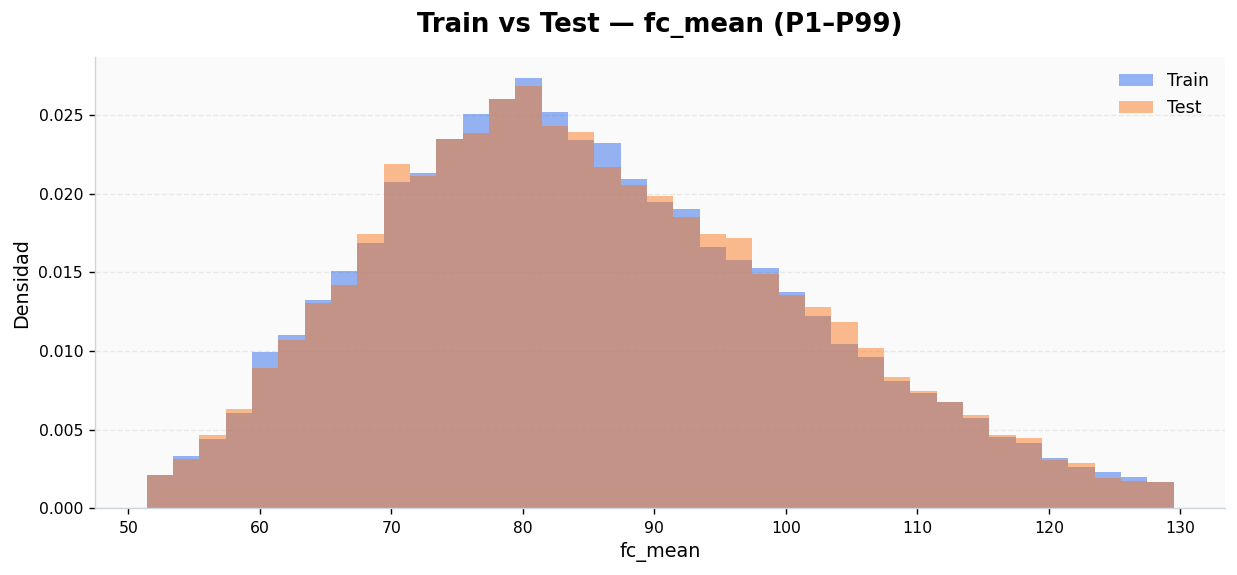

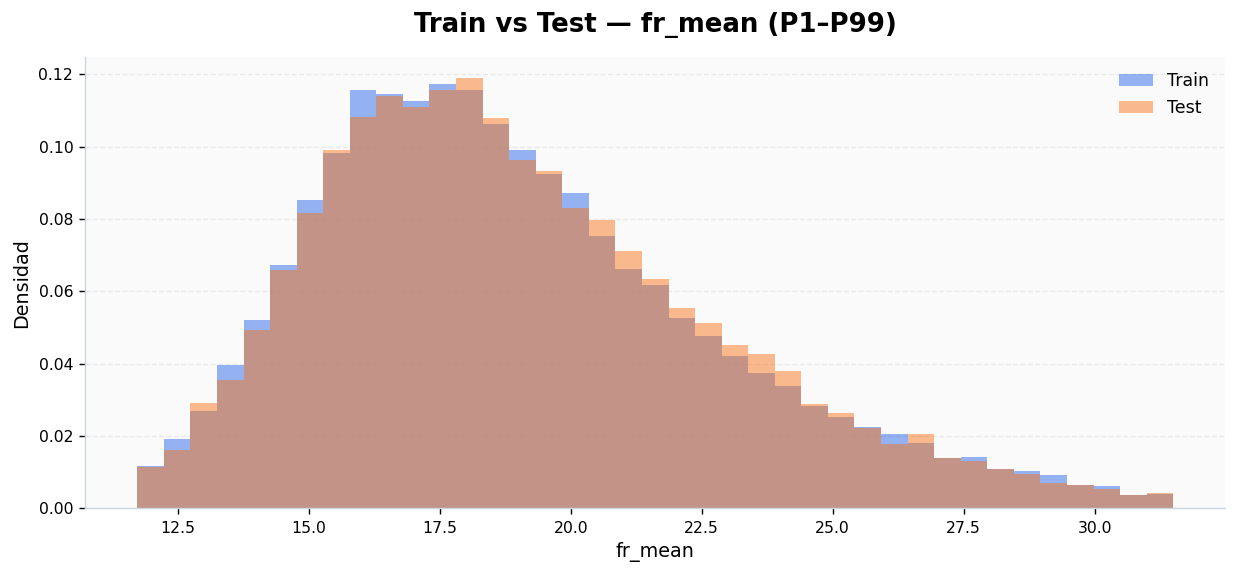

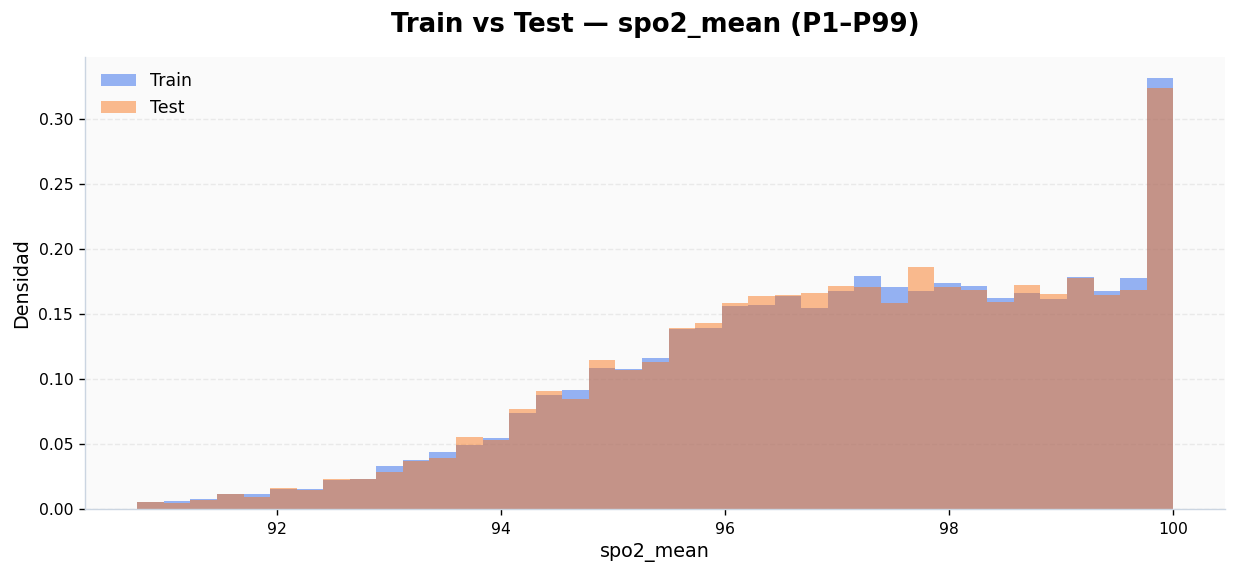

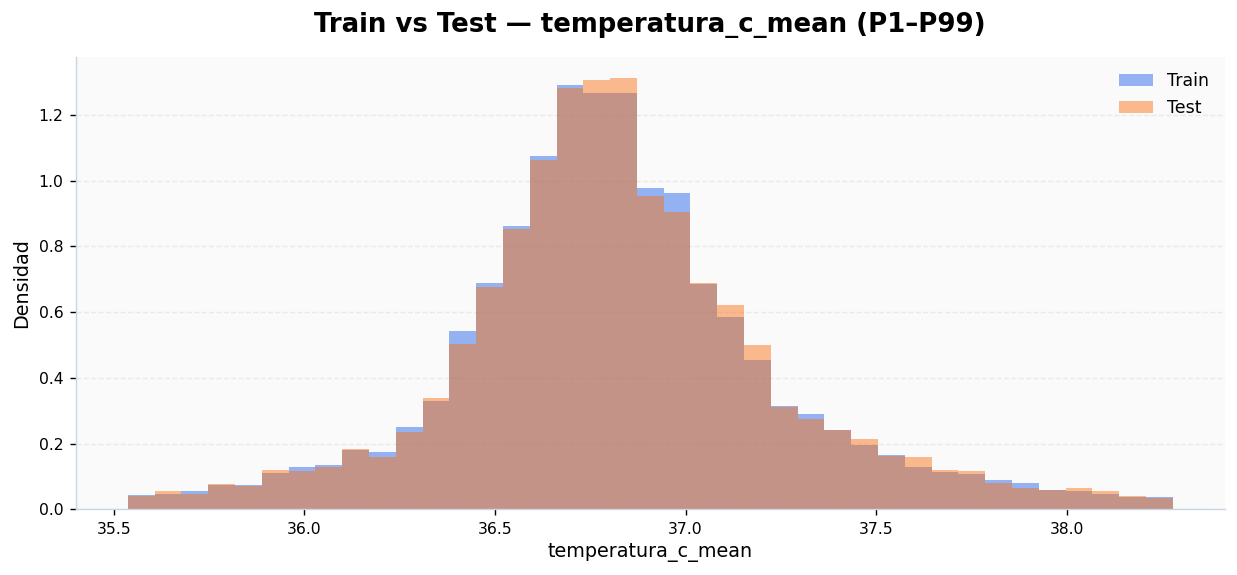

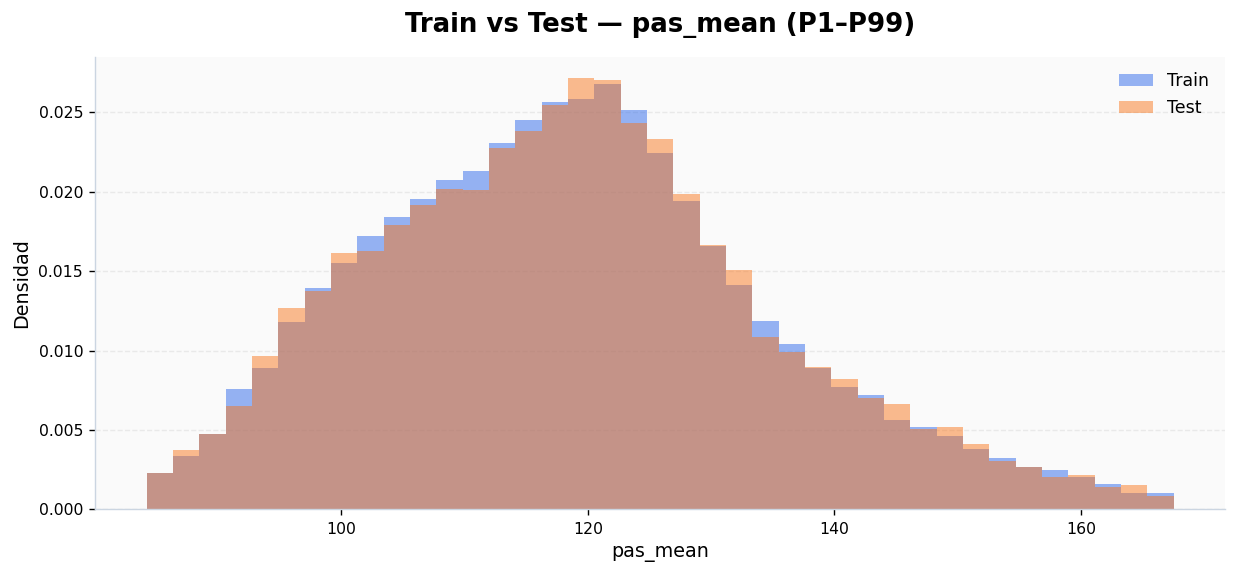

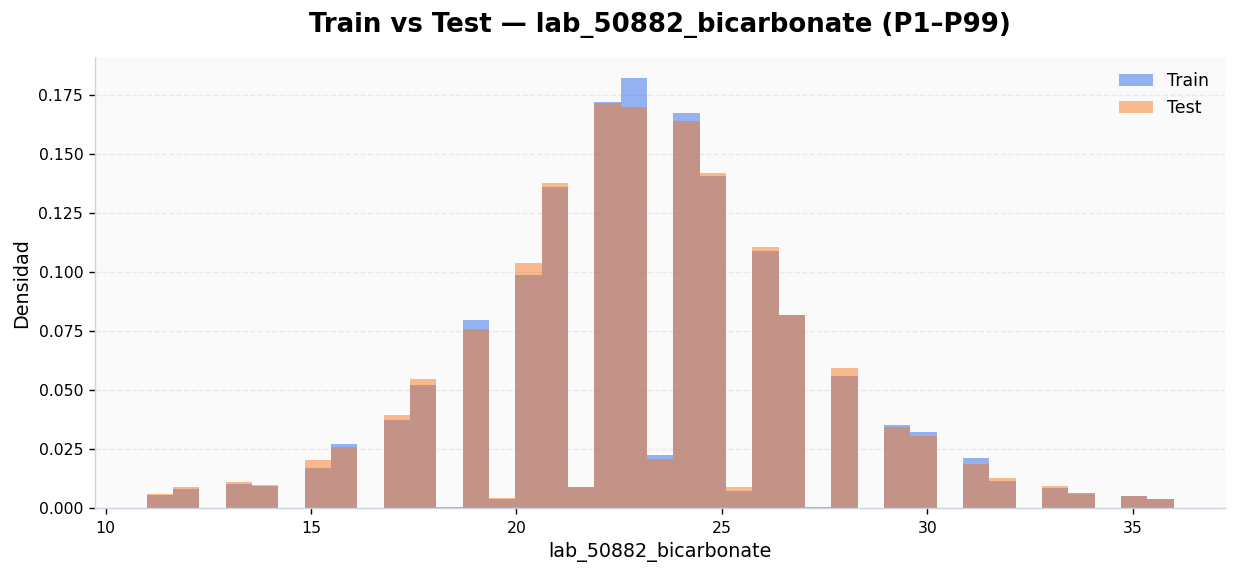

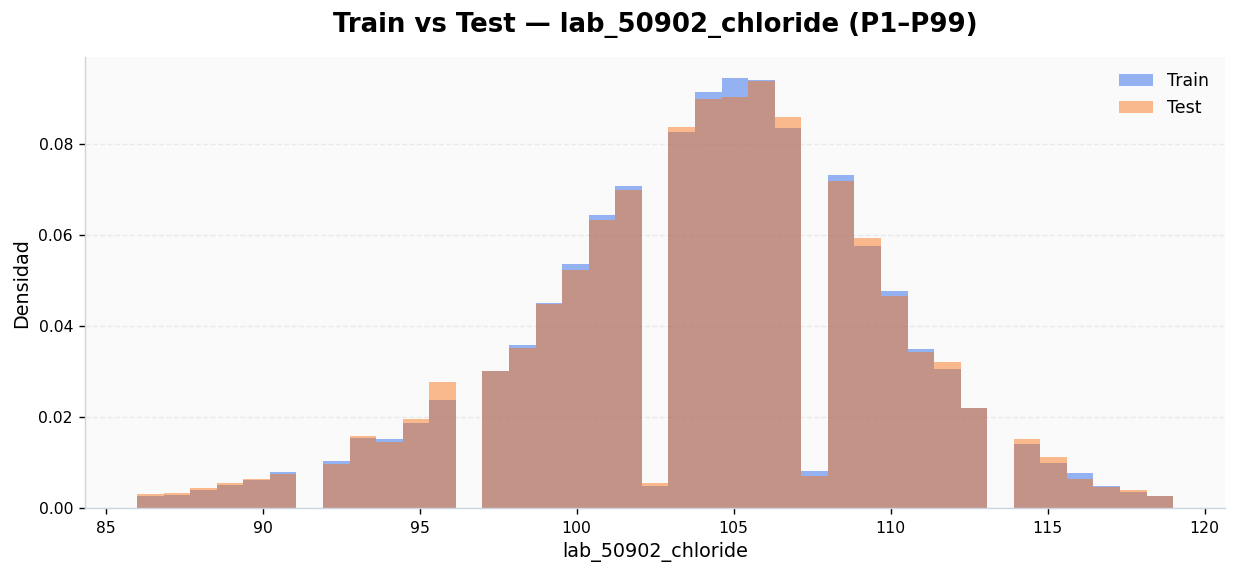

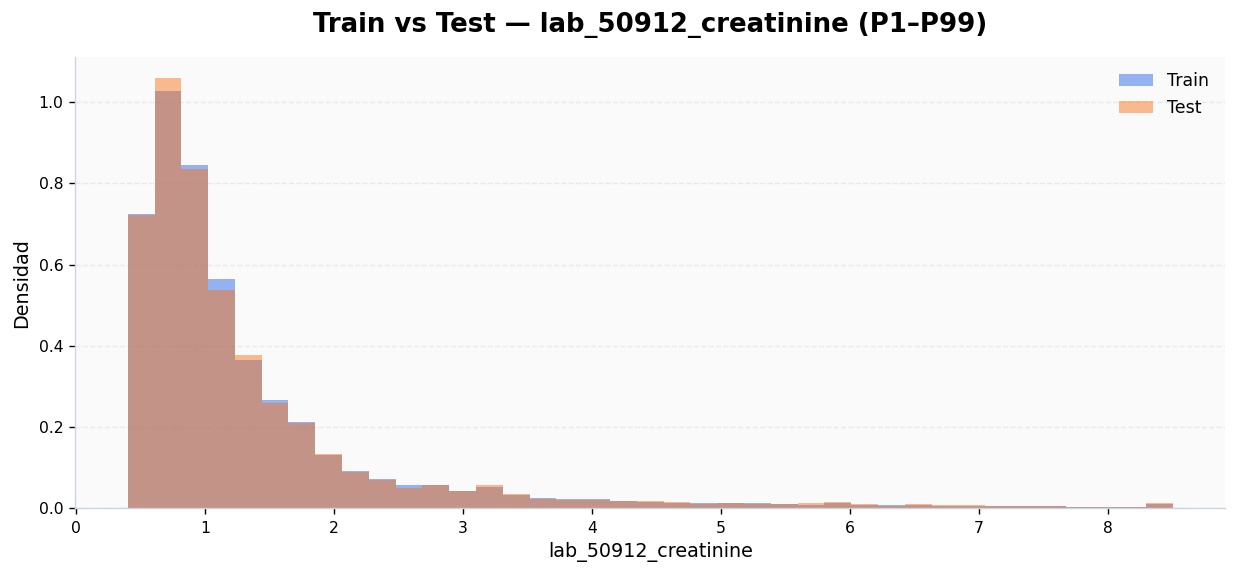

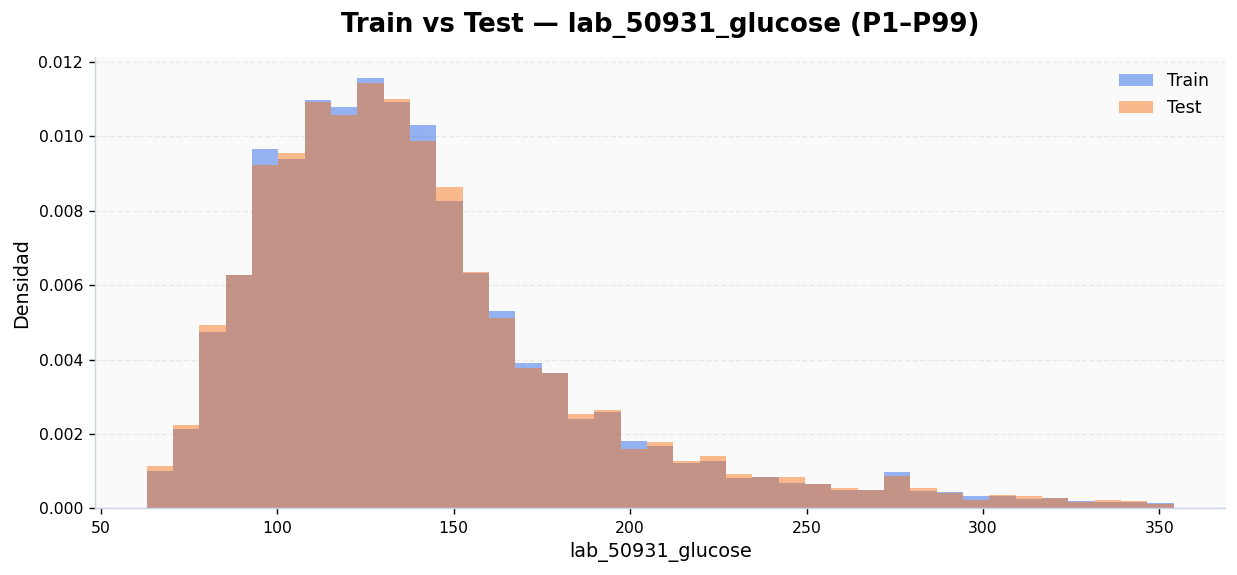

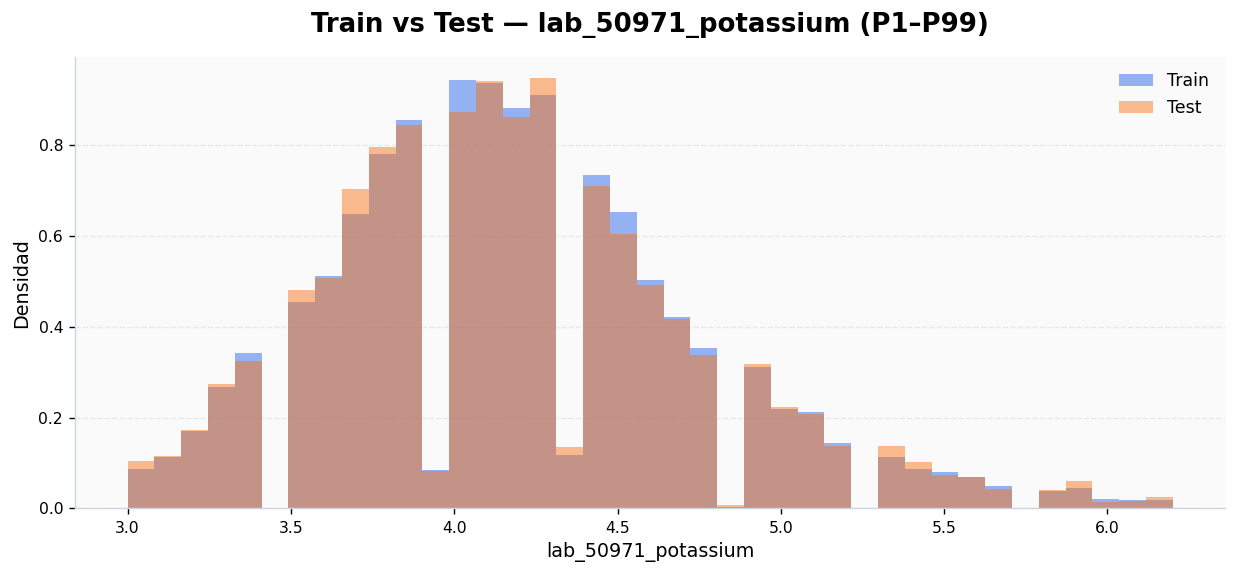

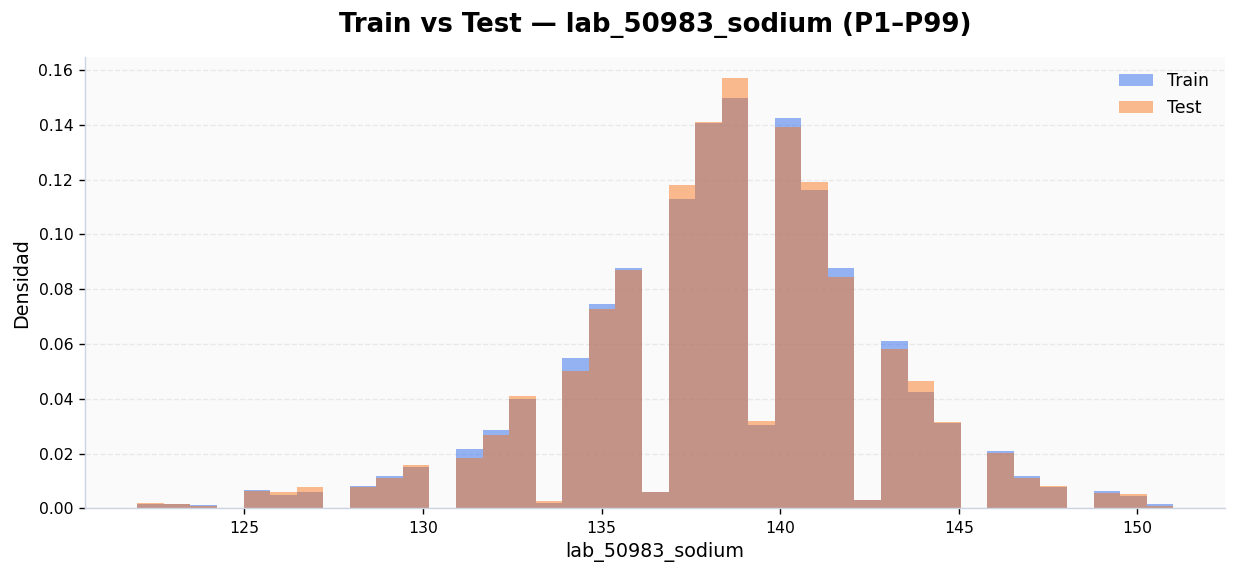

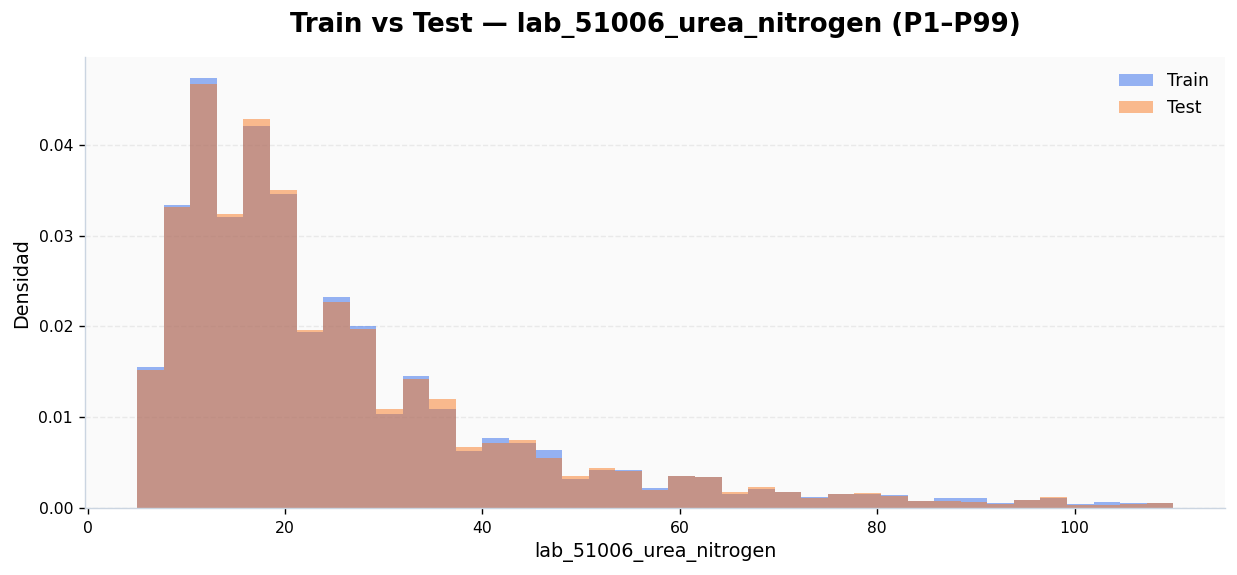

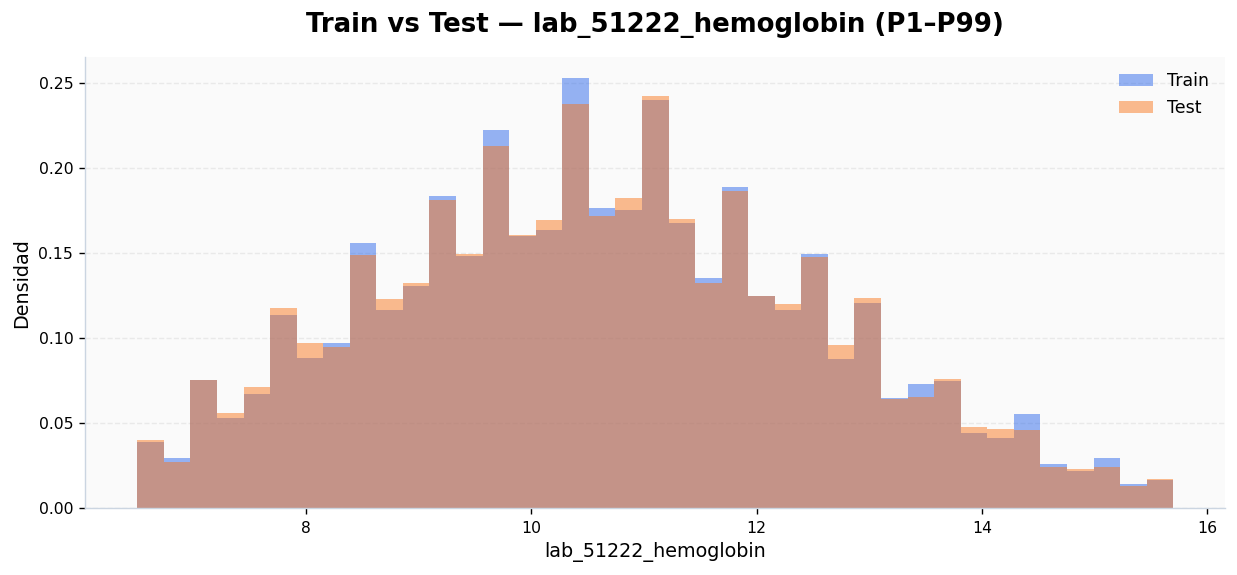

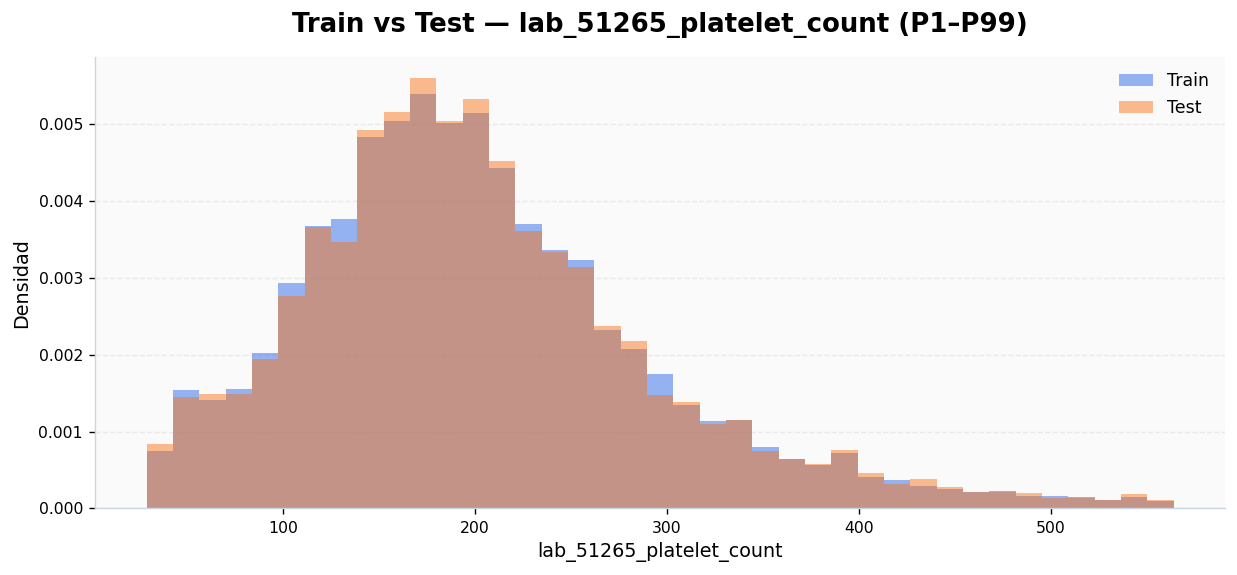

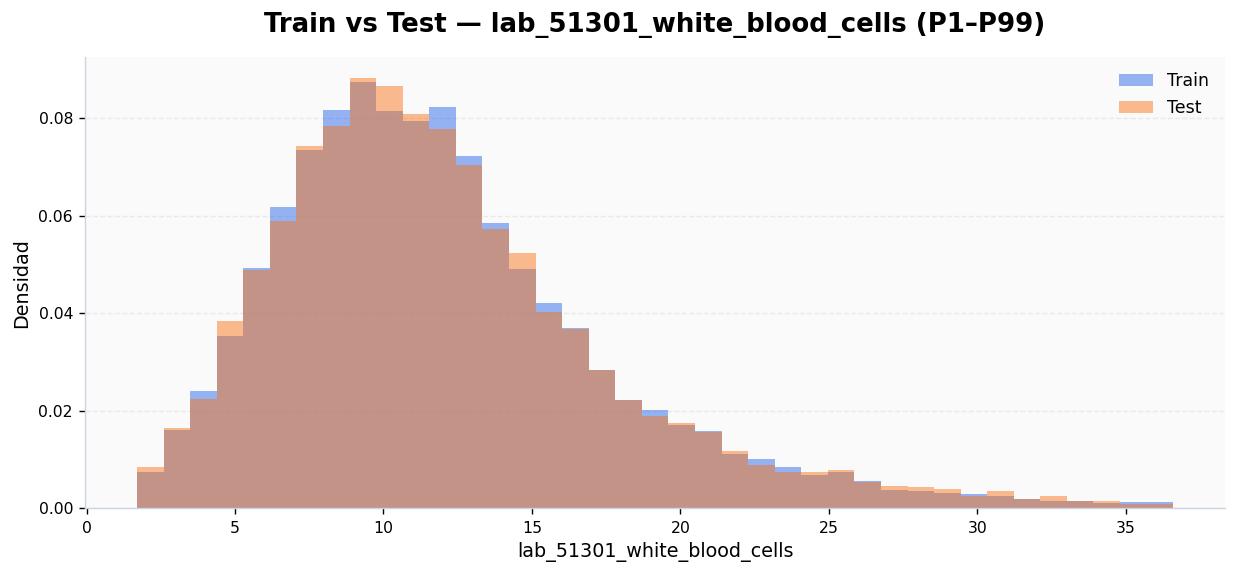

In [60]:
variables_revision = [TARGET] + numeric_features

for i, c in enumerate(variables_revision):
    tr = train_imputado[c].dropna()
    te = test_imputado[c].dropna()

    lo = min(tr.quantile(.01), te.quantile(.01))
    hi = max(tr.quantile(.99), te.quantile(.99))
    bins = np.linspace(lo, hi, 40)

    fig, ax = plt.subplots(figsize=(10,4.7))
    ax.hist(tr[(tr>=lo)&(tr<=hi)], bins=bins, density=True,
            color=AZUL, alpha=.48, label="Train")
    ax.hist(te[(te>=lo)&(te<=hi)], bins=bins, density=True,
            color=NARANJA, alpha=.48, label="Test")
    ax.legend()

    formato_ax(
        ax,
        f"Train vs Test — {c} (P1–P99)",
        c,
        "Densidad"
    )
    plt.tight_layout()
    plt.show()


## 22.11 Resumen final post-limpieza


In [61]:
resumen_post = pd.DataFrame({
    "variable": numeric_features,
    "faltantes_train_post": [
        train_imputado[c].isna().sum() for c in numeric_features
    ],
    "media_train": [
        train_imputado[c].mean() for c in numeric_features
    ],
    "mediana_train": [
        train_imputado[c].median() for c in numeric_features
    ],
    "std_train": [
        train_imputado[c].std() for c in numeric_features
    ],
    "asimetria_train": [
        train_imputado[c].skew() for c in numeric_features
    ]
})

resumen_post = resumen_post.merge(
    outliers_post[["variable","pct_outliers"]],
    on="variable",
    how="left"
).merge(
    assoc_post[["variable","rho_spearman"]],
    on="variable",
    how="left"
)

display(resumen_post)


,variable,faltantes_train_post,media_train,mediana_train,std_train,asimetria_train,pct_outliers,rho_spearman
0,edad_ingreso,0,64.747,66.000,16.688,-0.544,0.843,0.031
1,fc_mean,0,85.158,83.308,16.923,0.471,1.064,0.102
2,fr_mean,0,19.045,18.364,4.139,0.931,2.601,0.131
3,spo2_mean,0,96.984,97.250,2.375,-3.211,1.184,0.063
4,temperatura_c_mean,0,36.810,36.792,0.545,-3.113,7.646,0.101
5,pas_mean,0,118.835,118.024,17.324,0.521,1.943,-0.060
6,lab_50882_bicarbonate,0,23.157,23.000,4.388,0.283,5.934,-0.070
7,lab_50902_chloride,0,104.057,104.511,6.197,-0.343,3.568,-0.030
8,lab_50912_creatinine,0,1.456,1.000,1.510,4.406,9.610,0.090
9,lab_50931_glucose,0,141.935,130.823,58.215,3.453,5.856,0.085


In [62]:
POST_DIR = RESULTS_DIR / "eda_post_limpieza"
POST_DIR.mkdir(parents=True, exist_ok=True)

comp_falt.to_csv(POST_DIR/"01_faltantes_antes_despues.csv")
desc_post.to_csv(POST_DIR/"02_descriptivos_post_limpieza.csv")
outliers_post.to_csv(POST_DIR/"03_outliers_post_limpieza.csv", index=False)
corr_post.to_csv(POST_DIR/"04_correlacion_spearman_post.csv")
pares_post.to_csv(POST_DIR/"05_pares_correlacion_post.csv", index=False)
assoc_post.to_csv(POST_DIR/"06_asociacion_target_post.csv", index=False)
resumen_post.to_csv(POST_DIR/"07_resumen_post_limpieza.csv", index=False)

print("Resultados del EDA post-limpieza guardados en:")
print(POST_DIR.resolve())


Resultados del EDA post-limpieza guardados en:
C:\Users\grise\Downloads\estancia-hospitalaria-uci\results\eda_post_limpieza


# Conclusión del EDA post-limpieza

Este segundo EDA permite demostrar que la limpieza no consistió simplemente en eliminar observaciones extremas. Se conservaron los extremos clínicamente posibles, se invalidaron únicamente mediciones incompatibles con los controles de calidad y la imputación se ajustó exclusivamente con TRAIN.

Antes de construir la regresión, los siguientes pasos serán:

- revisar los resultados reales de este EDA post-limpieza;
- evaluar multicolinealidad mediante VIF únicamente en TRAIN;
- codificar `gender`;
- decidir si el target se modelará en escala original y/o `log1p`;
- estandarizar dentro del pipeline cuando el método de regresión lo requiera;
- comparar modelos y evaluar exclusivamente al final sobre TEST.
